Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers.jpg
Colour image shape : (2160, 3840, 3)
Grayscale shape    : (2160, 3840)
Binary shape       : (2160, 3840)
Otsu threshold     : 120.0
Unique binary values: [  0 255]


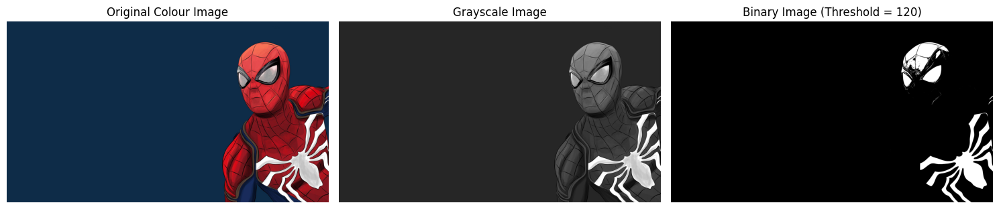

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2. Read image (OpenCV loads as BGR)
img_bgr = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 3. Colour -> Grayscale
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# 4. Grayscale -> Binary (Otsu's automatic threshold)
thresh_val, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 5. Print image details
print("Colour image shape :", img_rgb.shape)
print("Grayscale shape    :", gray.shape)
print("Binary shape       :", binary.shape)
print("Otsu threshold     :", thresh_val)
print("Unique binary values:", np.unique(binary))

# 6. Display all three images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Colour Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binary, cmap="gray")
plt.title(f"Binary Image (Threshold = {thresh_val:.0f})")
plt.axis("off")

plt.tight_layout()
plt.show()

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (1).jpg
Image shape: (2160, 3840, 3)
R range: 0 - 255
G range: 0 - 255
B range: 0 - 255
H range: 0 - 179 (OpenCV scale 0-179)
S range: 0 - 255
V range: 0 - 255


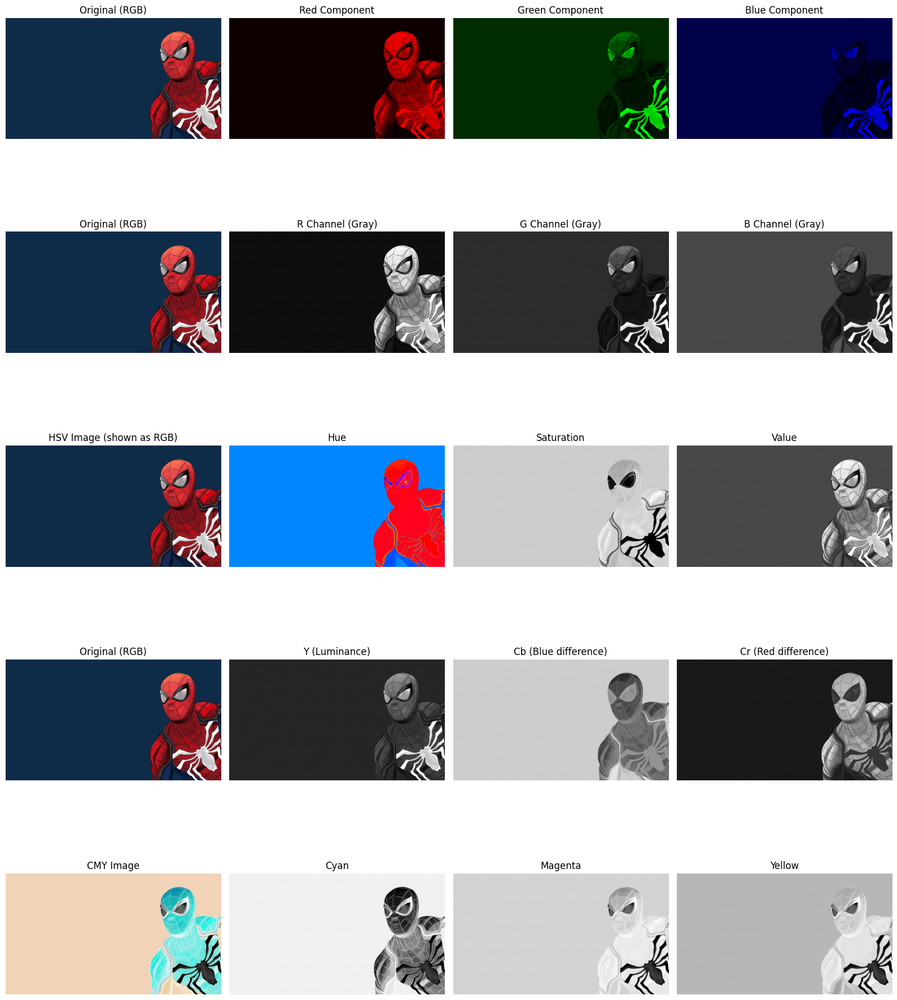

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2. Read image (OpenCV loads as BGR) and convert to RGB
img_bgr = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 3. RGB components
R, G, B = img_rgb[:, :, 0], img_rgb[:, :, 1], img_rgb[:, :, 2]

# Coloured versions of each channel (other channels set to zero)
zeros = np.zeros_like(R)
R_img = np.dstack((R, zeros, zeros))
G_img = np.dstack((zeros, G, zeros))
B_img = np.dstack((zeros, zeros, B))

# 4. HSV model
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

# 5. YCbCr model (OpenCV uses YCrCb order)
ycrcb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)
Y, Cr, Cb = ycrcb[:, :, 0], ycrcb[:, :, 1], ycrcb[:, :, 2]

# 6. CMY model (CMY = 255 - RGB)
cmy = 255 - img_rgb
C, M, Y_cmy = cmy[:, :, 0], cmy[:, :, 1], cmy[:, :, 2]

# 7. Print details
print("Image shape:", img_rgb.shape)
print("R range:", R.min(), "-", R.max())
print("G range:", G.min(), "-", G.max())
print("B range:", B.min(), "-", B.max())
print("H range:", H.min(), "-", H.max(), "(OpenCV scale 0-179)")
print("S range:", S.min(), "-", S.max())
print("V range:", V.min(), "-", V.max())

# 8. Display everything
fig, axes = plt.subplots(5, 4, figsize=(16, 20))

# Row 1: RGB (coloured)
axes[0, 0].imshow(img_rgb);  axes[0, 0].set_title("Original (RGB)")
axes[0, 1].imshow(R_img);    axes[0, 1].set_title("Red Component")
axes[0, 2].imshow(G_img);    axes[0, 2].set_title("Green Component")
axes[0, 3].imshow(B_img);    axes[0, 3].set_title("Blue Component")

# Row 2: RGB (grayscale intensity)
axes[1, 0].imshow(img_rgb);        axes[1, 0].set_title("Original (RGB)")
axes[1, 1].imshow(R, cmap="gray"); axes[1, 1].set_title("R Channel (Gray)")
axes[1, 2].imshow(G, cmap="gray"); axes[1, 2].set_title("G Channel (Gray)")
axes[1, 3].imshow(B, cmap="gray"); axes[1, 3].set_title("B Channel (Gray)")

# Row 3: HSV
axes[2, 0].imshow(hsv[:, :, ::-1] if False else cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)); axes[2, 0].set_title("HSV Image (shown as RGB)")
axes[2, 1].imshow(H, cmap="hsv");  axes[2, 1].set_title("Hue")
axes[2, 2].imshow(S, cmap="gray"); axes[2, 2].set_title("Saturation")
axes[2, 3].imshow(V, cmap="gray"); axes[2, 3].set_title("Value")

# Row 4: YCbCr
axes[3, 0].imshow(img_rgb);         axes[3, 0].set_title("Original (RGB)")
axes[3, 1].imshow(Y, cmap="gray");  axes[3, 1].set_title("Y (Luminance)")
axes[3, 2].imshow(Cb, cmap="gray"); axes[3, 2].set_title("Cb (Blue difference)")
axes[3, 3].imshow(Cr, cmap="gray"); axes[3, 3].set_title("Cr (Red difference)")

# Row 5: CMY
axes[4, 0].imshow(cmy);                 axes[4, 0].set_title("CMY Image")
axes[4, 1].imshow(C, cmap="gray");      axes[4, 1].set_title("Cyan")
axes[4, 2].imshow(M, cmap="gray");      axes[4, 2].set_title("Magenta")
axes[4, 3].imshow(Y_cmy, cmap="gray");  axes[4, 3].set_title("Yellow")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()


Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (2).jpg
Original image size: (256, 256)
Sampling factor 1: size = (256, 256)
Sampling factor 2: size = (128, 128)
Sampling factor 4: size = (64, 64)
Sampling factor 8: size = (32, 32)
Sampling factor 16: size = (16, 16)


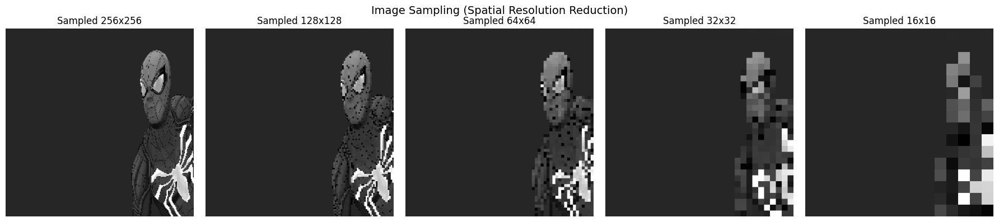

Quantization: 256 gray levels -> unique values found: 256
Quantization: 64 gray levels -> unique values found: 64
Quantization: 16 gray levels -> unique values found: 16
Quantization: 4 gray levels -> unique values found: 4
Quantization: 2 gray levels -> unique values found: 2


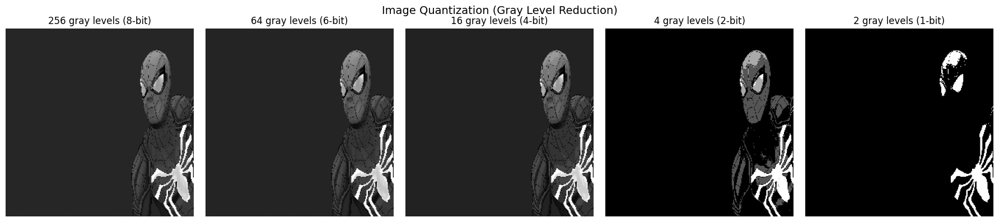

Nearest Neighbour  -> MSE =  1348.97, PSNR = 16.83 dB
Bilinear           -> MSE =   961.24, PSNR = 18.30 dB
Bicubic            -> MSE =  1109.24, PSNR = 17.68 dB
Lanczos            -> MSE =  1139.92, PSNR = 17.56 dB


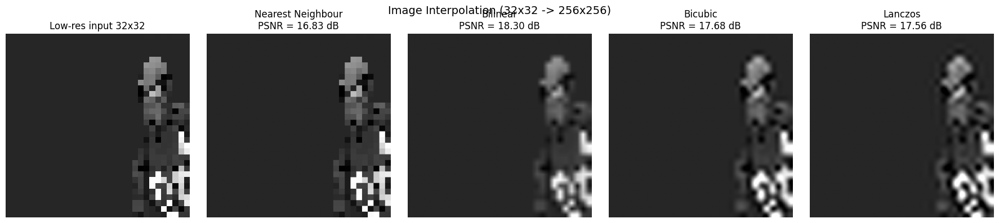

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2. Read image as grayscale and resize to 256x256 for clear comparison
gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))
h, w = gray.shape
print("Original image size:", gray.shape)

# ---------------------------------------------------
# 3. SAMPLING (reduce spatial resolution)
# ---------------------------------------------------
factors = [1, 2, 4, 8, 16]
sampled_images = []
for f in factors:
    small = gray[::f, ::f]                        # keep every f-th pixel
    print(f"Sampling factor {f}: size = {small.shape}")
    # enlarge back with nearest neighbour only to display the blocky effect
    shown = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
    sampled_images.append((shown, small.shape))

plt.figure(figsize=(18, 4))
for i, (im, shp) in enumerate(sampled_images):
    plt.subplot(1, len(factors), i + 1)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Sampled {shp[0]}x{shp[1]}")
    plt.axis("off")
plt.suptitle("Image Sampling (Spatial Resolution Reduction)", fontsize=14)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 4. QUANTIZATION (reduce number of gray levels)
# ---------------------------------------------------
levels = [256, 64, 16, 4, 2]
quantized_images = []
for L in levels:
    step = 256 // L
    q = (gray // step) * step                     # map to L levels
    q = (q.astype(np.float32) * 255 / q.max()).astype(np.uint8) if q.max() > 0 else q
    quantized_images.append((q, L))
    print(f"Quantization: {L} gray levels -> unique values found: {len(np.unique(q))}")

plt.figure(figsize=(18, 4))
for i, (im, L) in enumerate(quantized_images):
    plt.subplot(1, len(levels), i + 1)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(f"{L} gray levels ({int(np.log2(L))}-bit)")
    plt.axis("off")
plt.suptitle("Image Quantization (Gray Level Reduction)", fontsize=14)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 5. INTERPOLATION (resize a small image back up)
# ---------------------------------------------------
small = gray[::8, ::8]                            # 32x32 low-resolution image
methods = {
    "Nearest Neighbour": cv2.INTER_NEAREST,
    "Bilinear":          cv2.INTER_LINEAR,
    "Bicubic":           cv2.INTER_CUBIC,
    "Lanczos":           cv2.INTER_LANCZOS4,
}

plt.figure(figsize=(18, 4))
plt.subplot(1, 5, 1)
plt.imshow(small, cmap="gray", vmin=0, vmax=255)
plt.title(f"Low-res input {small.shape[0]}x{small.shape[1]}")
plt.axis("off")

for i, (name, m) in enumerate(methods.items()):
    up = cv2.resize(small, (w, h), interpolation=m)
    mse = np.mean((gray.astype(np.float32) - up.astype(np.float32)) ** 2)
    psnr = 10 * np.log10(255 ** 2 / mse)
    print(f"{name:18s} -> MSE = {mse:8.2f}, PSNR = {psnr:5.2f} dB")
    plt.subplot(1, 5, i + 2)
    plt.imshow(up, cmap="gray", vmin=0, vmax=255)
    plt.title(f"{name}\nPSNR = {psnr:.2f} dB")
    plt.axis("off")

plt.suptitle("Image Interpolation (32x32 -> 256x256)", fontsize=14)
plt.tight_layout()
plt.show()


Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (3).jpg
Image size: (256, 256)

Pixel p = (128, 128), intensity = 38
N4(p): [(127, 128), (129, 128), (128, 127), (128, 129)]
ND(p): [(127, 127), (127, 129), (129, 127), (129, 129)]
N8(p): [(127, 128), (129, 128), (128, 127), (128, 129), (127, 127), (127, 129), (129, 127), (129, 129)]


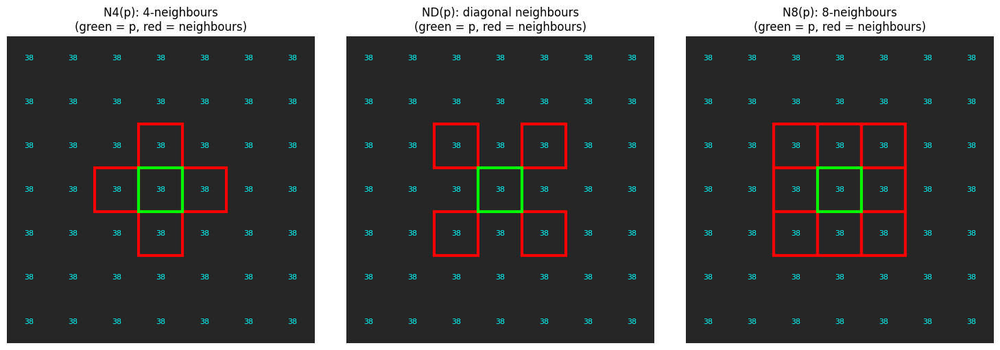


Connected components (4-connectivity): 51
Connected components (8-connectivity): 30


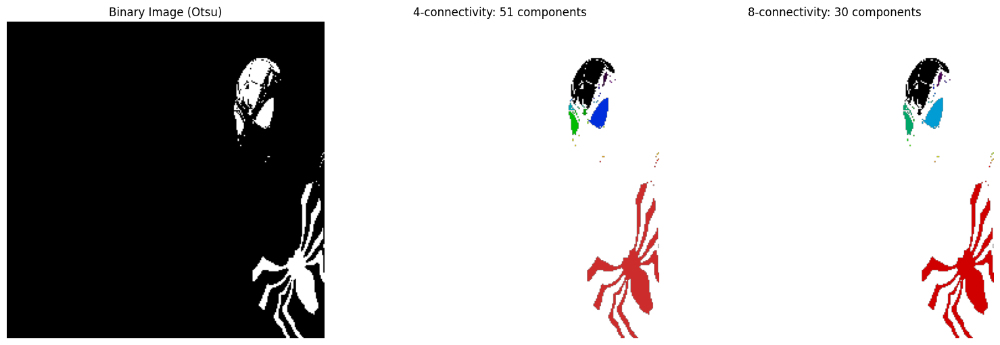


Example matrix:
 [[0 1 1]
 [0 2 0]
 [0 0 1]] 
V = {1, 2}
4-adjacent((0, 2), (1, 1)): False
8-adjacent((0, 2), (1, 1)): True
m-adjacent((0, 2), (1, 1)): False

p = (50, 40), q = (200, 180)
Euclidean distance (De)      : 205.18
City-block distance (D4)     : 290
Chessboard distance (D8)     : 150


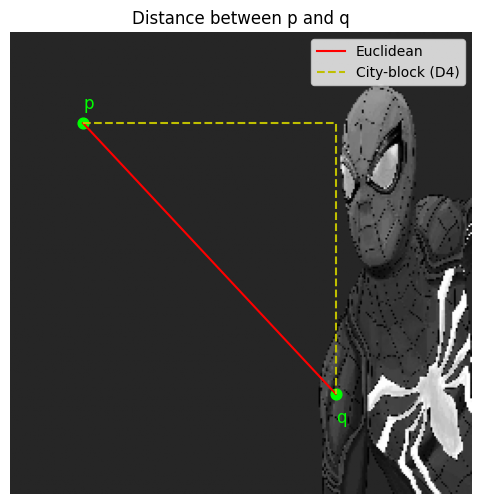

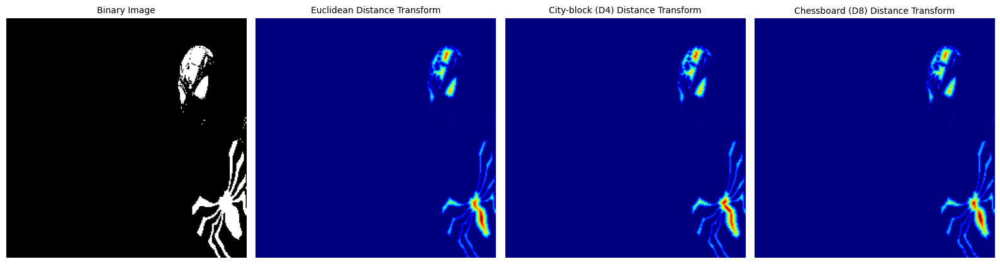

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2. Read as grayscale, resize for easy viewing
gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))
h, w = gray.shape
print("Image size:", gray.shape)

# ---------------------------------------------------
# 3. NEIGHBOURS  (N4, ND, N8)
# ---------------------------------------------------
def N4(r, c, shape):
    pts = [(r-1, c), (r+1, c), (r, c-1), (r, c+1)]
    return [(i, j) for i, j in pts if 0 <= i < shape[0] and 0 <= j < shape[1]]

def ND(r, c, shape):
    pts = [(r-1, c-1), (r-1, c+1), (r+1, c-1), (r+1, c+1)]
    return [(i, j) for i, j in pts if 0 <= i < shape[0] and 0 <= j < shape[1]]

def N8(r, c, shape):
    return N4(r, c, shape) + ND(r, c, shape)

r, c = h // 2, w // 2          # chosen pixel p(r, c)  (change if you like)
print(f"\nPixel p = ({r}, {c}), intensity = {gray[r, c]}")
print("N4(p):", N4(r, c, gray.shape))
print("ND(p):", ND(r, c, gray.shape))
print("N8(p):", N8(r, c, gray.shape))

# Show a 7x7 patch around p with neighbours highlighted
k = 3
patch = gray[r-k:r+k+1, c-k:c+k+1]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, fn) in zip(axes, [("N4(p): 4-neighbours", N4),
                                 ("ND(p): diagonal neighbours", ND),
                                 ("N8(p): 8-neighbours", N8)]):
    ax.imshow(patch, cmap="gray", vmin=0, vmax=255)
    for (i, j) in fn(r, c, gray.shape):
        ax.add_patch(plt.Rectangle((j-c+k-0.5, i-r+k-0.5), 1, 1,
                                   fill=False, edgecolor="red", linewidth=3))
    ax.add_patch(plt.Rectangle((k-0.5, k-0.5), 1, 1,
                               fill=False, edgecolor="lime", linewidth=3))
    for a in range(patch.shape[0]):
        for b in range(patch.shape[1]):
            ax.text(b, a, patch[a, b], ha="center", va="center",
                    color="cyan", fontsize=8)
    ax.set_title(name + "\n(green = p, red = neighbours)")
    ax.axis("off")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 4. CONNECTIVITY  (4-, 8-connectivity on a binary image)
# ---------------------------------------------------
_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

n4, lab4 = cv2.connectedComponents(binary, connectivity=4)
n8, lab8 = cv2.connectedComponents(binary, connectivity=8)
print("\nConnected components (4-connectivity):", n4 - 1)
print("Connected components (8-connectivity):", n8 - 1)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(binary, cmap="gray"); plt.title("Binary Image (Otsu)"); plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(np.ma.masked_where(lab4 == 0, lab4), cmap="nipy_spectral")
plt.title(f"4-connectivity: {n4-1} components"); plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(np.ma.masked_where(lab8 == 0, lab8), cmap="nipy_spectral")
plt.title(f"8-connectivity: {n8-1} components"); plt.axis("off")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 5. m-ADJACENCY (mixed adjacency) on a small example
# ---------------------------------------------------
A = np.array([[0, 1, 1],
              [0, 2, 0],
              [0, 0, 1]])
V = {1, 2}                      # set of intensity values defining adjacency

def adj4(p, q):
    return abs(p[0]-q[0]) + abs(p[1]-q[1]) == 1

def adjD(p, q):
    return abs(p[0]-q[0]) == 1 and abs(p[1]-q[1]) == 1

def in_V(p):
    return A[p] in V

def m_adjacent(p, q):
    if not (in_V(p) and in_V(q)):
        return False
    if adj4(p, q):
        return True
    if adjD(p, q):
        common = [x for x in N4(*p, A.shape) if x in N4(*q, A.shape)]
        return not any(in_V(x) for x in common)
    return False

p, q = (0, 2), (1, 1)
print("\nExample matrix:\n", A, "\nV =", V)
print(f"4-adjacent{p, q}:", adj4(p, q) and in_V(p) and in_V(q))
print(f"8-adjacent{p, q}:", (adj4(p, q) or adjD(p, q)) and in_V(p) and in_V(q))
print(f"m-adjacent{p, q}:", m_adjacent(p, q))

# ---------------------------------------------------
# 6. DISTANCE MEASURES between two pixels
# ---------------------------------------------------
p = (50, 40)
q = (200, 180)

def euclidean(p, q):  return np.sqrt((p[0]-q[0])**2 + (p[1]-q[1])**2)
def city_block(p, q): return abs(p[0]-q[0]) + abs(p[1]-q[1])          # D4
def chessboard(p, q): return max(abs(p[0]-q[0]), abs(p[1]-q[1]))      # D8

print(f"\np = {p}, q = {q}")
print(f"Euclidean distance (De)      : {euclidean(p, q):.2f}")
print(f"City-block distance (D4)     : {city_block(p, q)}")
print(f"Chessboard distance (D8)     : {chessboard(p, q)}")

plt.figure(figsize=(6, 6))
plt.imshow(gray, cmap="gray")
plt.plot([p[1], q[1]], [p[0], q[0]], "r-", label="Euclidean")
plt.plot([p[1], q[1], q[1]], [p[0], p[0], q[0]], "y--", label="City-block (D4)")
plt.scatter([p[1], q[1]], [p[0], q[0]], c="lime", s=60)
plt.text(p[1], p[0]-8, "p", color="lime", fontsize=12)
plt.text(q[1], q[0]+16, "q", color="lime", fontsize=12)
plt.legend(); plt.title("Distance between p and q"); plt.axis("off")
plt.show()

# Distance transform: distance of each white pixel to the nearest black pixel
dt_e = cv2.distanceTransform(binary, cv2.DIST_L2, 5)
dt_4 = cv2.distanceTransform(binary, cv2.DIST_L1, 3)
dt_8 = cv2.distanceTransform(binary, cv2.DIST_C, 3)

plt.figure(figsize=(16, 4.5))
for i, (im, t) in enumerate([(binary, "Binary Image"),
                             (dt_e, "Euclidean Distance Transform"),
                             (dt_4, "City-block (D4) Distance Transform"),
                             (dt_8, "Chessboard (D8) Distance Transform")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(im, cmap="gray" if i == 0 else "jet")
    plt.title(t, fontsize=10); plt.axis("off")
plt.tight_layout()
plt.show()

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (4).jpg
Image size: (2160, 3840) | Min: 0 | Max: 255


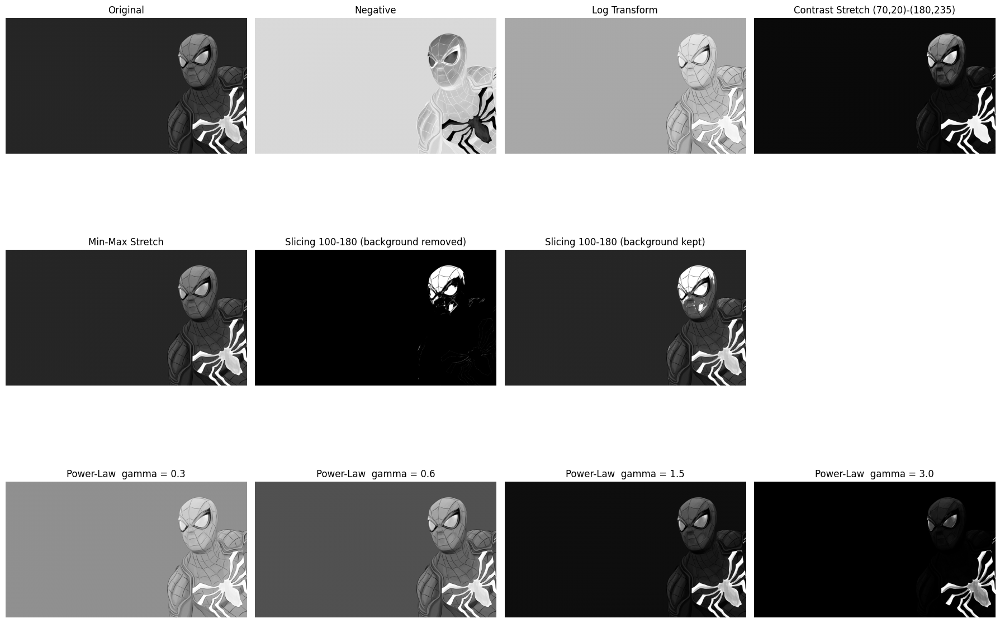

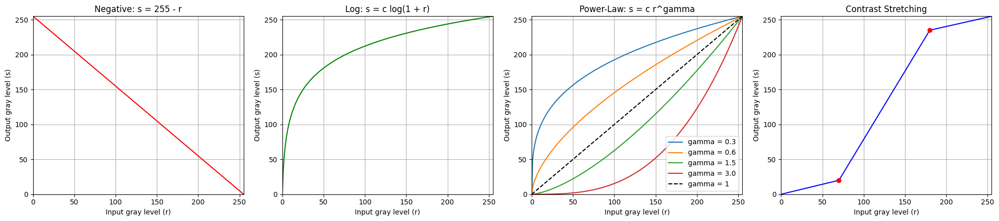

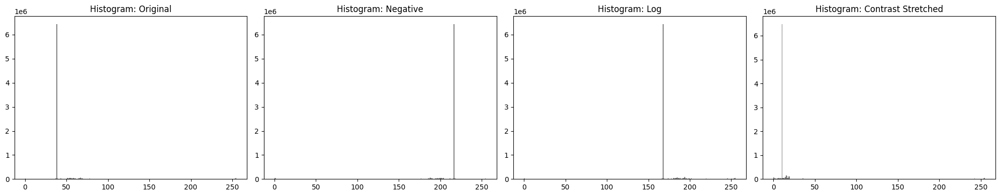

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2. Read as grayscale
gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
print("Image size:", gray.shape, "| Min:", gray.min(), "| Max:", gray.max())

r = np.arange(256, dtype=np.float32)       # input gray levels for plotting curves
f = gray.astype(np.float32)

# ---------------------------------------------------
# 3. IMAGE NEGATIVE:  s = (L - 1) - r
# ---------------------------------------------------
negative = 255 - gray
neg_curve = 255 - r

# ---------------------------------------------------
# 4. LOG TRANSFORMATION:  s = c * log(1 + r)
# ---------------------------------------------------
c_log = 255 / np.log(1 + f.max())
log_img = (c_log * np.log(1 + f)).astype(np.uint8)
log_curve = c_log * np.log(1 + r)

# ---------------------------------------------------
# 5. POWER-LAW (GAMMA):  s = c * r^gamma
# ---------------------------------------------------
gammas = [0.3, 0.6, 1.5, 3.0]
gamma_imgs = []
for g in gammas:
    s = 255 * (f / 255) ** g
    gamma_imgs.append(s.astype(np.uint8))

# ---------------------------------------------------
# 6. CONTRAST STRETCHING (piecewise linear)
# ---------------------------------------------------
r1, s1 = 70, 20
r2, s2 = 180, 235

def contrast_stretch(x, r1, s1, r2, s2):
    out = np.zeros_like(x, dtype=np.float32)
    m1 = x < r1
    m2 = (x >= r1) & (x <= r2)
    m3 = x > r2
    out[m1] = (s1 / r1) * x[m1]
    out[m2] = ((s2 - s1) / (r2 - r1)) * (x[m2] - r1) + s1
    out[m3] = ((255 - s2) / (255 - r2)) * (x[m3] - r2) + s2
    return out

stretched = contrast_stretch(f, r1, s1, r2, s2).astype(np.uint8)
stretch_curve = contrast_stretch(r, r1, s1, r2, s2)

# Min-max normalisation (full-range stretching)
minmax = ((f - f.min()) / (f.max() - f.min()) * 255).astype(np.uint8)

# ---------------------------------------------------
# 7. INTENSITY (GRAY-LEVEL) SLICING
# ---------------------------------------------------
A, B = 100, 180                              # range of interest

# (a) Highlight range, set everything else to black
slice_bg_removed = np.where((gray >= A) & (gray <= B), 255, 0).astype(np.uint8)

# (b) Highlight range, preserve the other intensities
slice_bg_kept = np.where((gray >= A) & (gray <= B), 255, gray).astype(np.uint8)

# ---------------------------------------------------
# 8. DISPLAY: Negative, Log, Contrast stretching, Slicing
# ---------------------------------------------------
fig, axes = plt.subplots(3, 4, figsize=(18, 13))

axes[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255);     axes[0, 0].set_title("Original")
axes[0, 1].imshow(negative, cmap="gray", vmin=0, vmax=255); axes[0, 1].set_title("Negative")
axes[0, 2].imshow(log_img, cmap="gray", vmin=0, vmax=255);  axes[0, 2].set_title("Log Transform")
axes[0, 3].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 3].set_title(f"Contrast Stretch ({r1},{s1})-({r2},{s2})")

axes[1, 0].imshow(minmax, cmap="gray", vmin=0, vmax=255);   axes[1, 0].set_title("Min-Max Stretch")
axes[1, 1].imshow(slice_bg_removed, cmap="gray", vmin=0, vmax=255)
axes[1, 1].set_title(f"Slicing {A}-{B} (background removed)")
axes[1, 2].imshow(slice_bg_kept, cmap="gray", vmin=0, vmax=255)
axes[1, 2].set_title(f"Slicing {A}-{B} (background kept)")
axes[1, 3].axis("off")

for i, (g, im) in enumerate(zip(gammas, gamma_imgs)):
    axes[2, i].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[2, i].set_title(f"Power-Law  gamma = {g}")

for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 9. TRANSFORMATION CURVES
# ---------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

axes[0].plot(r, neg_curve, "r")
axes[0].set_title("Negative: s = 255 - r")

axes[1].plot(r, log_curve, "g")
axes[1].set_title("Log: s = c log(1 + r)")

for g in gammas:
    axes[2].plot(r, 255 * (r / 255) ** g, label=f"gamma = {g}")
axes[2].plot(r, r, "k--", label="gamma = 1")
axes[2].legend()
axes[2].set_title("Power-Law: s = c r^gamma")

axes[3].plot(r, stretch_curve, "b")
axes[3].plot([r1, r2], [s1, s2], "ro")
axes[3].set_title("Contrast Stretching")

for ax in axes:
    ax.set_xlabel("Input gray level (r)")
    ax.set_ylabel("Output gray level (s)")
    ax.set_xlim(0, 255); ax.set_ylim(0, 255)
    ax.grid(True)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 10. HISTOGRAMS (before vs after)
# ---------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (im, t) in zip(axes, [(gray, "Original"), (negative, "Negative"),
                              (log_img, "Log"), (stretched, "Contrast Stretched")]):
    ax.hist(im.ravel(), bins=256, range=(0, 255), color="gray")
    ax.set_title("Histogram: " + t)
plt.tight_layout()
plt.show()

Upload the INPUT image


Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (6).jpg
Image size: (2160, 3840) | Min: 0 | Max: 255
Manual vs OpenCV equalisation max difference: 2

Upload the REFERENCE image (whose histogram you want to match)


Saving best-free-travel-images-main-image-hd-op (1).webp to best-free-travel-images-main-image-hd-op (1).webp


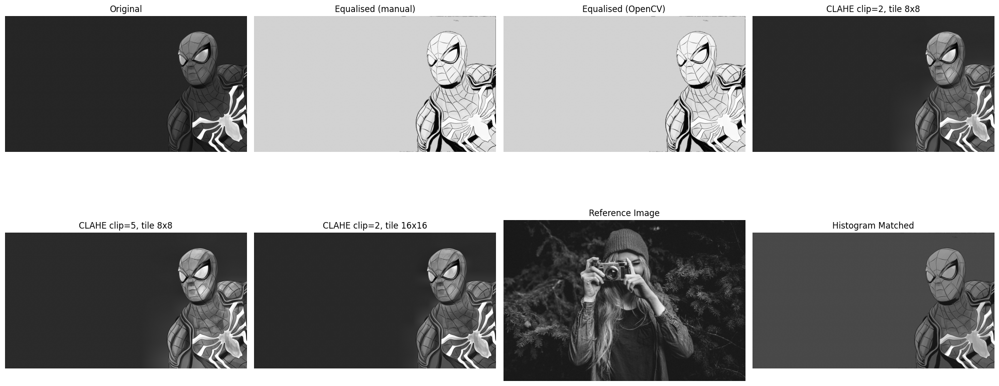

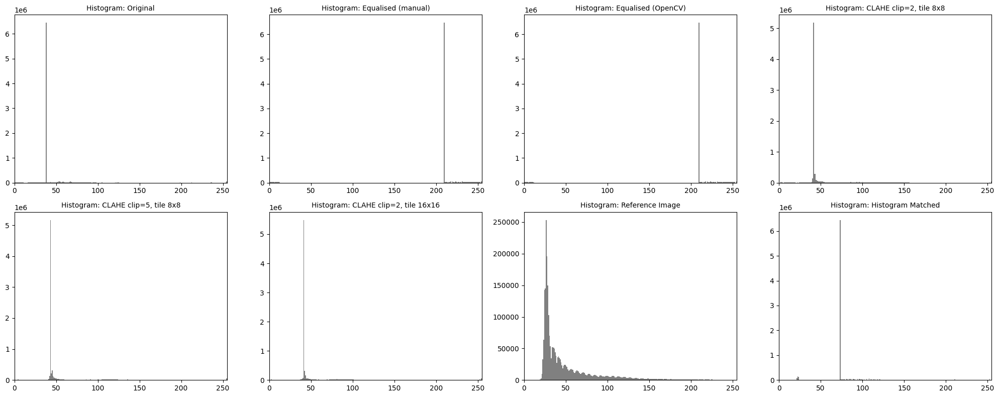

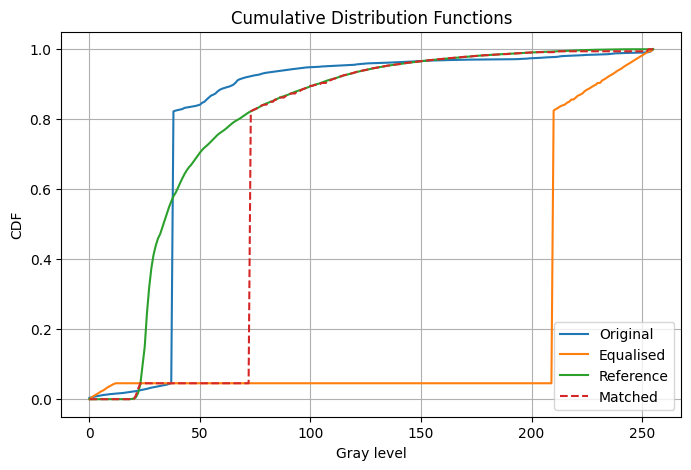

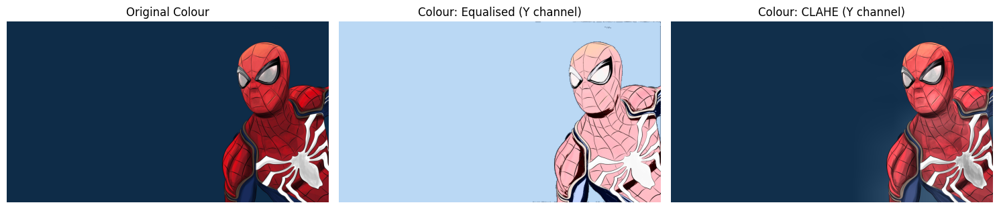

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload the input image (low-contrast images show the best results)
print("Upload the INPUT image")
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
print("Image size:", gray.shape, "| Min:", gray.min(), "| Max:", gray.max())

# ---------------------------------------------------
# 2. HISTOGRAM EQUALISATION (manual): s_k = (L-1) * CDF(r_k)
# ---------------------------------------------------
hist = np.bincount(gray.ravel(), minlength=256)
pdf = hist / hist.sum()
cdf = np.cumsum(pdf)
mapping = np.round(255 * cdf).astype(np.uint8)
eq_manual = mapping[gray]

# OpenCV built-in equalisation
eq_cv = cv2.equalizeHist(gray)
print("Manual vs OpenCV equalisation max difference:",
      np.abs(eq_manual.astype(int) - eq_cv.astype(int)).max())

# ---------------------------------------------------
# 3. CLAHE (Contrast Limited Adaptive Histogram Equalisation)
# ---------------------------------------------------
clahe_a = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_b = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8, 8))
clahe_c = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(16, 16))
img_clahe_a = clahe_a.apply(gray)
img_clahe_b = clahe_b.apply(gray)
img_clahe_c = clahe_c.apply(gray)

# ---------------------------------------------------
# 4. HISTOGRAM MATCHING (specification)
# ---------------------------------------------------
print("\nUpload the REFERENCE image (whose histogram you want to match)")
uploaded_ref = files.upload()
ref_path = list(uploaded_ref.keys())[0]
ref = cv2.imread(ref_path, cv2.IMREAD_GRAYSCALE)

def hist_match(source, reference):
    s_hist = np.bincount(source.ravel(), minlength=256)
    r_hist = np.bincount(reference.ravel(), minlength=256)
    s_cdf = np.cumsum(s_hist) / s_hist.sum()
    r_cdf = np.cumsum(r_hist) / r_hist.sum()
    # for each source level find the reference level with the closest CDF value
    lut = np.zeros(256, dtype=np.uint8)
    for i in range(256):
        lut[i] = np.argmin(np.abs(r_cdf - s_cdf[i]))
    return lut[source]

matched = hist_match(gray, ref)

# ---------------------------------------------------
# 5. DISPLAY IMAGES
# ---------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
items = [(gray, "Original"),
         (eq_manual, "Equalised (manual)"),
         (eq_cv, "Equalised (OpenCV)"),
         (img_clahe_a, "CLAHE clip=2, tile 8x8"),
         (img_clahe_b, "CLAHE clip=5, tile 8x8"),
         (img_clahe_c, "CLAHE clip=2, tile 16x16"),
         (ref, "Reference Image"),
         (matched, "Histogram Matched")]
for ax, (im, t) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis("off")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 6. HISTOGRAMS
# ---------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, (im, t) in zip(axes.ravel(), items):
    ax.hist(im.ravel(), bins=256, range=(0, 255), color="gray")
    ax.set_title("Histogram: " + t, fontsize=10)
    ax.set_xlim(0, 255)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 7. CDF PLOTS (original, equalised, reference, matched)
# ---------------------------------------------------
def cdf_of(im):
    h = np.bincount(im.ravel(), minlength=256)
    return np.cumsum(h) / h.sum()

plt.figure(figsize=(8, 5))
plt.plot(cdf_of(gray), label="Original")
plt.plot(cdf_of(eq_manual), label="Equalised")
plt.plot(cdf_of(ref), label="Reference")
plt.plot(cdf_of(matched), "--", label="Matched")
plt.title("Cumulative Distribution Functions")
plt.xlabel("Gray level"); plt.ylabel("CDF")
plt.legend(); plt.grid(True)
plt.show()

# ---------------------------------------------------
# 8. COLOUR IMAGE: equalise only the luminance (Y) channel
# ---------------------------------------------------
img_bgr = cv2.imread(img_path)
ycrcb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)
ycrcb_eq = ycrcb.copy()
ycrcb_eq[:, :, 0] = cv2.equalizeHist(ycrcb[:, :, 0])
colour_eq = cv2.cvtColor(ycrcb_eq, cv2.COLOR_YCrCb2RGB)

ycrcb_cl = ycrcb.copy()
ycrcb_cl[:, :, 0] = clahe_a.apply(ycrcb[:, :, 0])
colour_clahe = cv2.cvtColor(ycrcb_cl, cv2.COLOR_YCrCb2RGB)

plt.figure(figsize=(15, 5))
for i, (im, t) in enumerate([(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), "Original Colour"),
                             (colour_eq, "Colour: Equalised (Y channel)"),
                             (colour_clahe, "Colour: CLAHE (Y channel)")]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im); plt.title(t); plt.axis("off")
plt.tight_layout()
plt.show()

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (7).jpg
Image size: (2160, 3840)


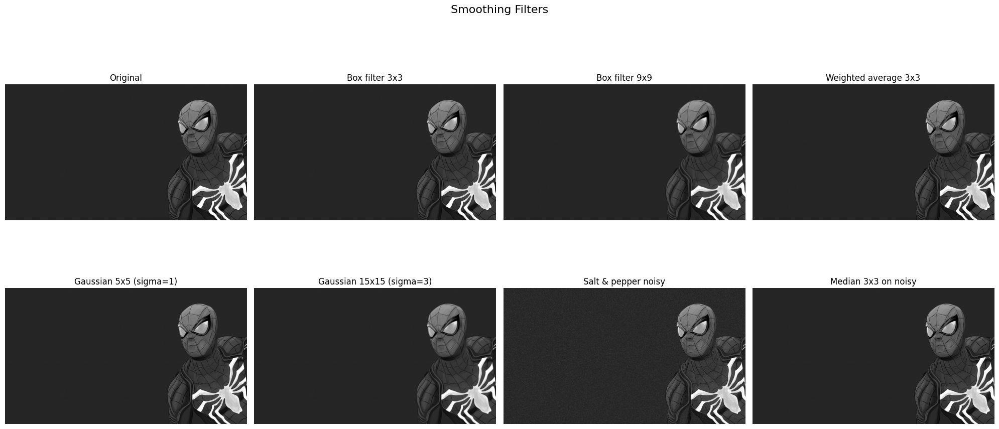

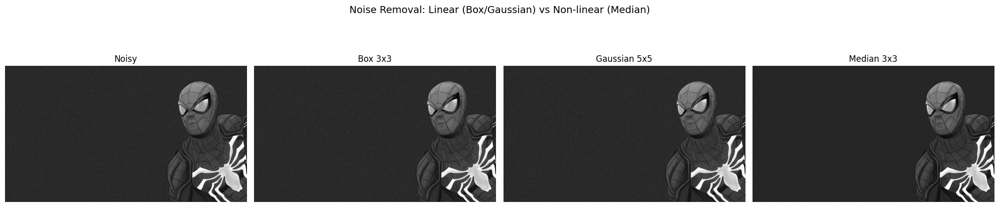

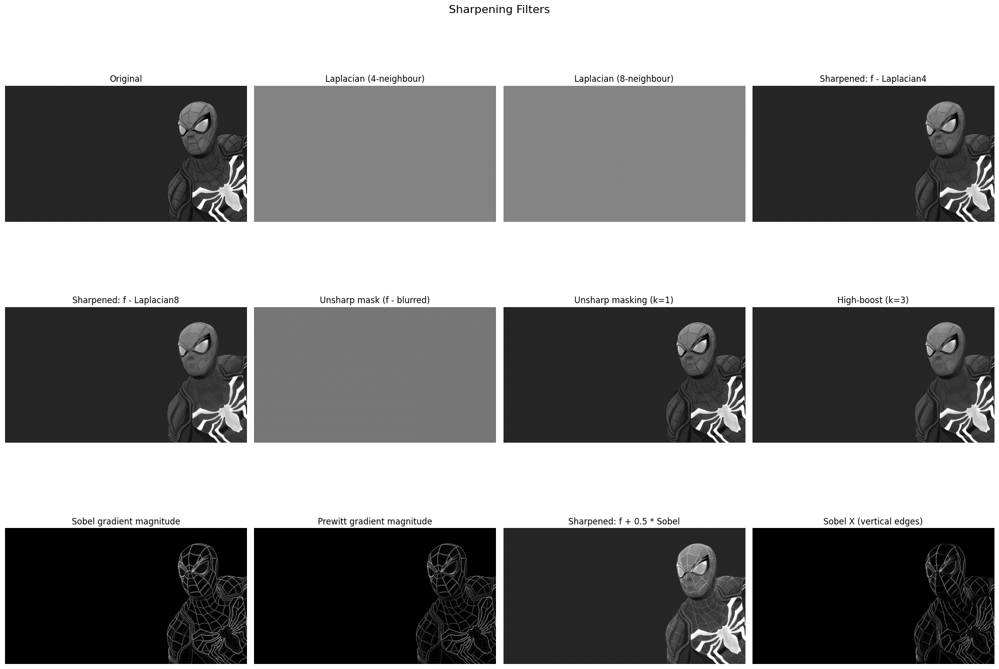

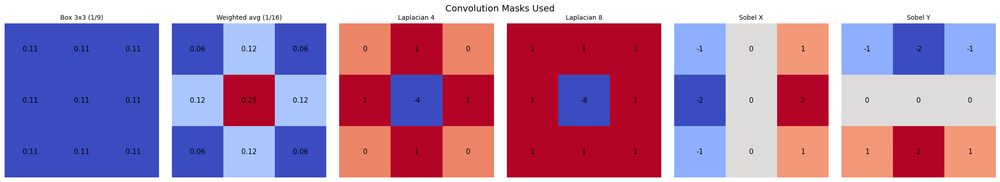


PSNR against the clean original (higher = better noise removal):
Noisy image        : 18.34 dB
Box 3x3            : 26.94 dB
Gaussian 5x5       : 27.82 dB
Median 3x3         : 40.59 dB


In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
print("Image size:", gray.shape)
f = gray.astype(np.float32)

def to_u8(x):
    return np.clip(x, 0, 255).astype(np.uint8)

def norm_u8(x):
    x = x - x.min()
    return (x / x.max() * 255).astype(np.uint8) if x.max() > 0 else x.astype(np.uint8)

# Add salt-and-pepper noise to show how the median filter behaves
noisy = gray.copy()
rng = np.random.default_rng(0)
mask = rng.random(gray.shape)
noisy[mask < 0.02] = 0
noisy[mask > 0.98] = 255

# ---------------------------------------------------
# 2. SMOOTHING (LOW-PASS) FILTERS
# ---------------------------------------------------
box3 = cv2.blur(gray, (3, 3))
box9 = cv2.blur(gray, (9, 9))

gauss5 = cv2.GaussianBlur(gray, (5, 5), 1.0)
gauss15 = cv2.GaussianBlur(gray, (15, 15), 3.0)

# Weighted average mask (centre pixel has more weight)
w_kernel = np.array([[1, 2, 1],
                     [2, 4, 2],
                     [1, 2, 1]], dtype=np.float32) / 16
weighted = cv2.filter2D(gray, -1, w_kernel)

# Noise removal comparison
noisy_box = cv2.blur(noisy, (3, 3))
noisy_gauss = cv2.GaussianBlur(noisy, (5, 5), 1.0)
noisy_median = cv2.medianBlur(noisy, 3)

# ---------------------------------------------------
# 3. SHARPENING (HIGH-PASS) FILTERS
# ---------------------------------------------------
# (a) Laplacian (two kernels: 4-neighbour and 8-neighbour)
lap4_k = np.array([[0, 1, 0],
                   [1, -4, 1],
                   [0, 1, 0]], dtype=np.float32)
lap8_k = np.array([[1, 1, 1],
                   [1, -8, 1],
                   [1, 1, 1]], dtype=np.float32)

lap4 = cv2.filter2D(f, cv2.CV_32F, lap4_k)
lap8 = cv2.filter2D(f, cv2.CV_32F, lap8_k)

# Sharpened = original - Laplacian (centre coefficient is negative)
sharp_lap4 = to_u8(f - lap4)
sharp_lap8 = to_u8(f - lap8)

# (b) Unsharp masking and high-boost filtering
blur = cv2.GaussianBlur(f, (9, 9), 2.0)
unsharp_mask = f - blur
unsharp = to_u8(f + 1.0 * unsharp_mask)          # k = 1
highboost = to_u8(f + 3.0 * unsharp_mask)        # k = 3 (high-boost)

# (c) Gradient filters: Sobel and Prewitt
sobel_x = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3)
sobel_mag = np.sqrt(sobel_x ** 2 + sobel_y ** 2)

prew_x_k = np.array([[-1, 0, 1],
                     [-1, 0, 1],
                     [-1, 0, 1]], dtype=np.float32)
prew_y_k = prew_x_k.T
prew_x = cv2.filter2D(f, cv2.CV_32F, prew_x_k)
prew_y = cv2.filter2D(f, cv2.CV_32F, prew_y_k)
prew_mag = np.sqrt(prew_x ** 2 + prew_y ** 2)

sharp_sobel = to_u8(f + 0.5 * sobel_mag)

# ---------------------------------------------------
# 4. DISPLAY: SMOOTHING
# ---------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
items = [(gray, "Original"),
         (box3, "Box filter 3x3"),
         (box9, "Box filter 9x9"),
         (weighted, "Weighted average 3x3"),
         (gauss5, "Gaussian 5x5 (sigma=1)"),
         (gauss15, "Gaussian 15x15 (sigma=3)"),
         (noisy, "Salt & pepper noisy"),
         (noisy_median, "Median 3x3 on noisy")]
for ax, (im, t) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis("off")
plt.suptitle("Smoothing Filters", fontsize=16)
plt.tight_layout()
plt.show()

# Noise removal comparison
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (im, t) in zip(axes, [(noisy, "Noisy"),
                              (noisy_box, "Box 3x3"),
                              (noisy_gauss, "Gaussian 5x5"),
                              (noisy_median, "Median 3x3")]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis("off")
plt.suptitle("Noise Removal: Linear (Box/Gaussian) vs Non-linear (Median)", fontsize=14)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 5. DISPLAY: SHARPENING
# ---------------------------------------------------
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
items = [(gray, "Original"),
         (norm_u8(lap4), "Laplacian (4-neighbour)"),
         (norm_u8(lap8), "Laplacian (8-neighbour)"),
         (sharp_lap4, "Sharpened: f - Laplacian4"),
         (sharp_lap8, "Sharpened: f - Laplacian8"),
         (norm_u8(unsharp_mask), "Unsharp mask (f - blurred)"),
         (unsharp, "Unsharp masking (k=1)"),
         (highboost, "High-boost (k=3)"),
         (to_u8(sobel_mag), "Sobel gradient magnitude"),
         (to_u8(prew_mag), "Prewitt gradient magnitude"),
         (sharp_sobel, "Sharpened: f + 0.5 * Sobel"),
         (to_u8(np.abs(sobel_x)), "Sobel X (vertical edges)")]
for ax, (im, t) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis("off")
plt.suptitle("Sharpening Filters", fontsize=16)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 6. KERNELS USED
# ---------------------------------------------------
sobel_x_k = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y_k = sobel_x_k.T
box_k = np.ones((3, 3)) / 9

kernels = [("Box 3x3 (1/9)", box_k),
           ("Weighted avg (1/16)", w_kernel),
           ("Laplacian 4", lap4_k),
           ("Laplacian 8", lap8_k),
           ("Sobel X", sobel_x_k),
           ("Sobel Y", sobel_y_k)]

fig, axes = plt.subplots(1, 6, figsize=(22, 4))
for ax, (t, k) in zip(axes, kernels):
    ax.imshow(k, cmap="coolwarm")
    for i in range(3):
        for j in range(3):
            val = k[i, j]
            ax.text(j, i, f"{val:.2f}" if abs(val) < 1 and val != 0 else f"{val:g}",
                    ha="center", va="center", fontsize=11)
    ax.set_title(t, fontsize=10)
    ax.axis("off")
plt.suptitle("Convolution Masks Used", fontsize=14)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 7. PRINT SUMMARY (PSNR of smoothed noisy images vs original)
# ---------------------------------------------------
def psnr(a, b):
    mse = np.mean((a.astype(np.float32) - b.astype(np.float32)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

print("\nPSNR against the clean original (higher = better noise removal):")
print(f"Noisy image        : {psnr(gray, noisy):.2f} dB")
print(f"Box 3x3            : {psnr(gray, noisy_box):.2f} dB")
print(f"Gaussian 5x5       : {psnr(gray, noisy_gauss):.2f} dB")
print(f"Median 3x3         : {psnr(gray, noisy_median):.2f} dB")

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (8).jpg
Image size: (256, 256)
DC component F(0,0): 3.136608e+06 | equals sum of all pixels: 3.136608e+06
Max reconstruction error: 3.0517578e-05


/tmp/ipykernel_546/3304171903.py:80: RuntimeWarning: invalid value encountered in log
  (cv2.normalize(np.log(1 + mag_only), None, 0, 255, cv2.NORM_MINMAX), "Magnitude-only reconstruction", "gray")]):


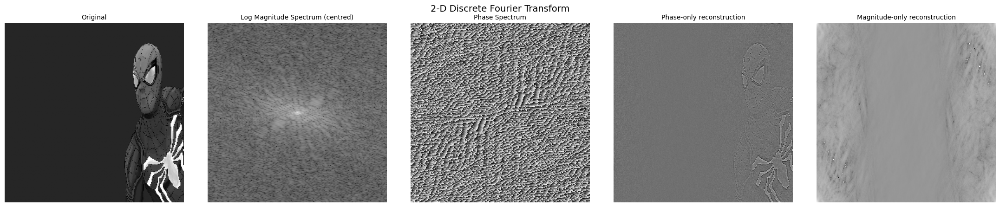

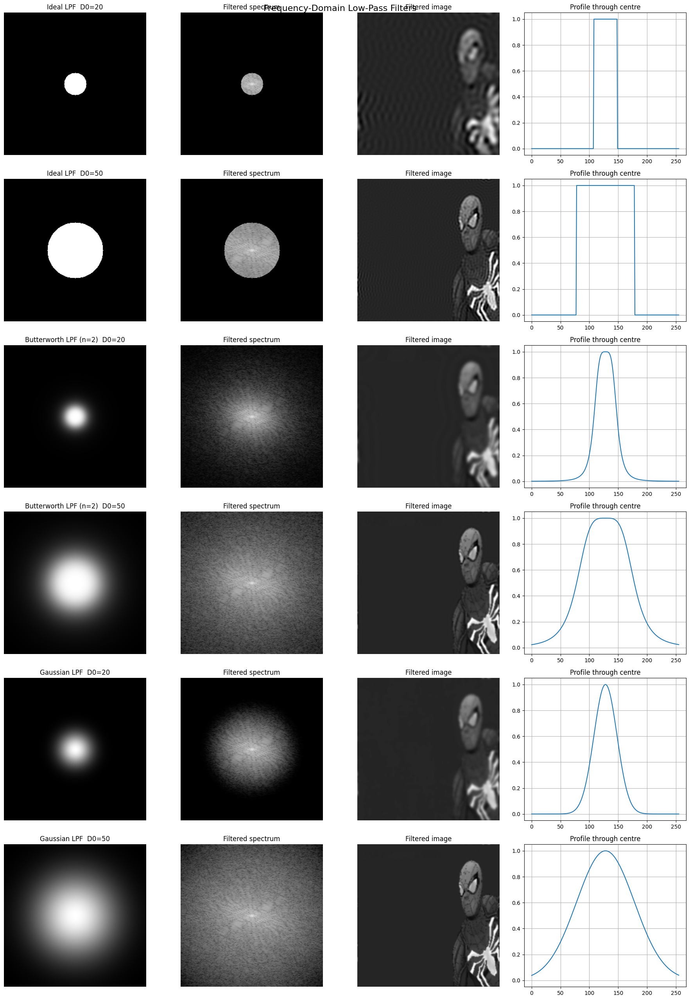

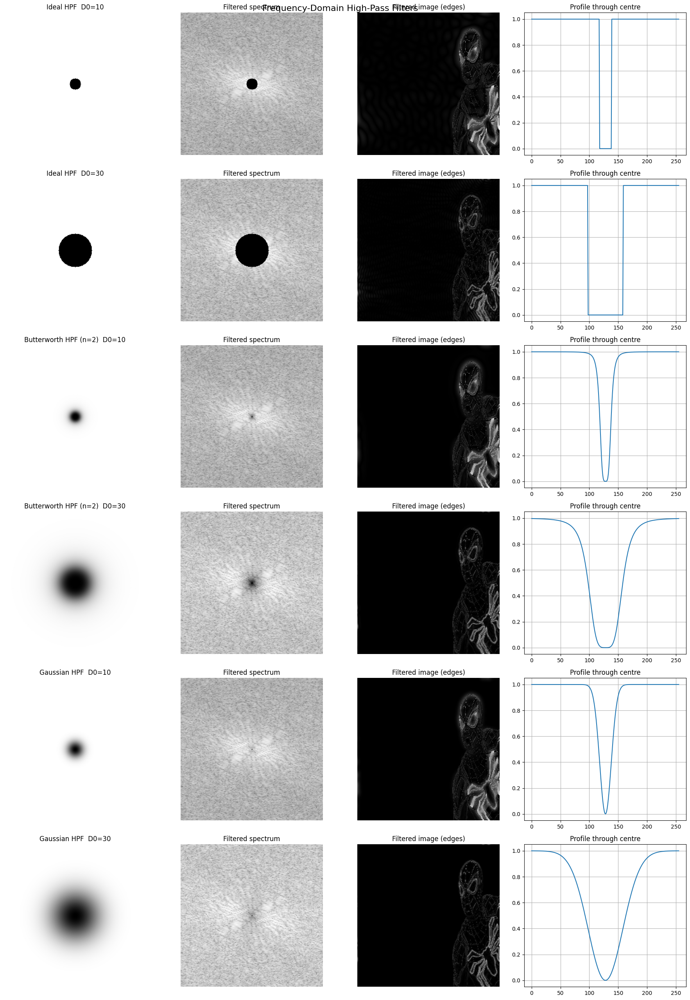

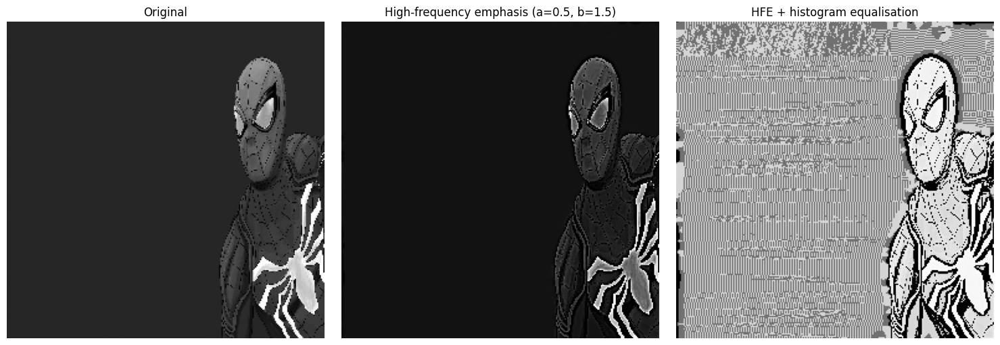


Power retained inside the cutoff circle (Ideal LPF):
D0 =   5 ->  78.65 % of total power
D0 =  10 ->  82.40 % of total power
D0 =  20 ->  86.91 % of total power
D0 =  40 ->  92.82 % of total power
D0 =  80 ->  96.54 % of total power


In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))
f = gray.astype(np.float32)
M, N = f.shape
print("Image size:", gray.shape)

# ---------------------------------------------------
# 2. 2-D DFT, centred spectrum, phase
# ---------------------------------------------------
F = np.fft.fft2(f)
Fshift = np.fft.fftshift(F)                      # move DC component to the centre
magnitude = np.abs(Fshift)
log_spectrum = np.log(1 + magnitude)             # log transform for display
phase = np.angle(Fshift)

print("DC component F(0,0):", np.abs(F[0, 0]).round(2),
      "| equals sum of all pixels:", f.sum().round(2))

# Inverse DFT check (should recover the original image)
recon = np.real(np.fft.ifft2(np.fft.ifftshift(Fshift)))
print("Max reconstruction error:", np.abs(recon - f).max())

# Phase-only and magnitude-only reconstruction
phase_only = np.real(np.fft.ifft2(np.exp(1j * np.angle(F))))
mag_only = np.real(np.fft.ifft2(np.abs(F)))

# ---------------------------------------------------
# 3. DISTANCE MATRIX D(u,v) from the centre of the spectrum
# ---------------------------------------------------
u = np.arange(M) - M // 2
v = np.arange(N) - N // 2
V, U = np.meshgrid(v, u)
D = np.sqrt(U ** 2 + V ** 2)

# ---------------------------------------------------
# 4. LOW-PASS FILTERS  H(u,v)
# ---------------------------------------------------
def ideal_lp(D, D0):
    return (D <= D0).astype(np.float32)

def butterworth_lp(D, D0, n=2):
    return 1 / (1 + (D / D0) ** (2 * n))

def gaussian_lp(D, D0):
    return np.exp(-(D ** 2) / (2 * D0 ** 2))

# ---------------------------------------------------
# 5. HIGH-PASS FILTERS  H_hp = 1 - H_lp
# ---------------------------------------------------
def ideal_hp(D, D0):      return 1 - ideal_lp(D, D0)
def butterworth_hp(D, D0, n=2): return 1 - butterworth_lp(D, D0, n)
def gaussian_hp(D, D0):   return 1 - gaussian_lp(D, D0)

def apply_filter(Fshift, H):
    G = Fshift * H
    g = np.real(np.fft.ifft2(np.fft.ifftshift(G)))
    return np.clip(g, 0, 255).astype(np.uint8), G

def apply_filter_raw(Fshift, H):
    G = Fshift * H
    return np.real(np.fft.ifft2(np.fft.ifftshift(G))), G

# ---------------------------------------------------
# 6. DISPLAY: DFT
# ---------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (im, t, cm) in zip(axes, [(gray, "Original", "gray"),
                                  (log_spectrum, "Log Magnitude Spectrum (centred)", "gray"),
                                  (phase, "Phase Spectrum", "gray"),
                                  (np.clip(phase_only, 0, 255) if False else cv2.normalize(phase_only, None, 0, 255, cv2.NORM_MINMAX), "Phase-only reconstruction", "gray"),
                                  (cv2.normalize(np.log(1 + mag_only), None, 0, 255, cv2.NORM_MINMAX), "Magnitude-only reconstruction", "gray")]):
    ax.imshow(im, cmap=cm)
    ax.set_title(t, fontsize=10)
    ax.axis("off")
plt.suptitle("2-D Discrete Fourier Transform", fontsize=14)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 7. LOW-PASS FILTERING (D0 = 20 and 50)
# ---------------------------------------------------
cutoffs = [20, 50]
fig, axes = plt.subplots(6, 4, figsize=(18, 26))
row = 0
for name, fn in [("Ideal LPF", ideal_lp),
                 ("Butterworth LPF (n=2)", butterworth_lp),
                 ("Gaussian LPF", gaussian_lp)]:
    for D0 in cutoffs:
        H = fn(D, D0)
        g, G = apply_filter(Fshift, H)
        axes[row, 0].imshow(H, cmap="gray");                  axes[row, 0].set_title(f"{name}  D0={D0}")
        axes[row, 1].imshow(np.log(1 + np.abs(G)), cmap="gray"); axes[row, 1].set_title("Filtered spectrum")
        axes[row, 2].imshow(g, cmap="gray", vmin=0, vmax=255);   axes[row, 2].set_title("Filtered image")
        axes[row, 3].plot(H[M // 2, :]);                      axes[row, 3].set_title("Profile through centre")
        axes[row, 3].set_ylim(-0.05, 1.05); axes[row, 3].grid(True)
        for k in range(3):
            axes[row, k].axis("off")
        row += 1
plt.suptitle("Frequency-Domain Low-Pass Filters", fontsize=16)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 8. HIGH-PASS FILTERING (D0 = 10 and 30)
# ---------------------------------------------------
cutoffs_hp = [10, 30]
fig, axes = plt.subplots(6, 4, figsize=(18, 26))
row = 0
for name, fn in [("Ideal HPF", ideal_hp),
                 ("Butterworth HPF (n=2)", butterworth_hp),
                 ("Gaussian HPF", gaussian_hp)]:
    for D0 in cutoffs_hp:
        H = fn(D, D0)
        raw, G = apply_filter_raw(Fshift, H)
        g = cv2.normalize(np.abs(raw), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        axes[row, 0].imshow(H, cmap="gray");                  axes[row, 0].set_title(f"{name}  D0={D0}")
        axes[row, 1].imshow(np.log(1 + np.abs(G)), cmap="gray"); axes[row, 1].set_title("Filtered spectrum")
        axes[row, 2].imshow(g, cmap="gray", vmin=0, vmax=255);   axes[row, 2].set_title("Filtered image (edges)")
        axes[row, 3].plot(H[M // 2, :]);                      axes[row, 3].set_title("Profile through centre")
        axes[row, 3].set_ylim(-0.05, 1.05); axes[row, 3].grid(True)
        for k in range(3):
            axes[row, k].axis("off")
        row += 1
plt.suptitle("Frequency-Domain High-Pass Filters", fontsize=16)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 9. SHARPENING: high-frequency emphasis  H_hfe = a + b * H_hp
# ---------------------------------------------------
H_hfe = 0.5 + 1.5 * gaussian_hp(D, 30)
sharp, _ = apply_filter(Fshift, H_hfe)
sharp_eq = cv2.equalizeHist(sharp)

plt.figure(figsize=(15, 5))
for i, (im, t) in enumerate([(gray, "Original"),
                             (sharp, "High-frequency emphasis (a=0.5, b=1.5)"),
                             (sharp_eq, "HFE + histogram equalisation")]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(t); plt.axis("off")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 10. ENERGY RETAINED BY LOW-PASS FILTERS
# ---------------------------------------------------
total_energy = np.sum(magnitude ** 2)
print("\nPower retained inside the cutoff circle (Ideal LPF):")
for D0 in [5, 10, 20, 40, 80]:
    inside = np.sum((magnitude ** 2)[D <= D0])
    print(f"D0 = {D0:3d} -> {100 * inside / total_energy:6.2f} % of total power")

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (9).jpg
Image size: (256, 256)

Noise type       |   MSE     | PSNR (dB)
----------------------------------------
Gaussian         |    557.44 |  20.67
Poisson          |    382.45 |  22.31
Salt & Pepper    |   2472.49 |  14.20
Speckle          |    121.88 |  27.27
Uniform          |    761.15 |  19.32
Exponential      |   1191.36 |  17.37


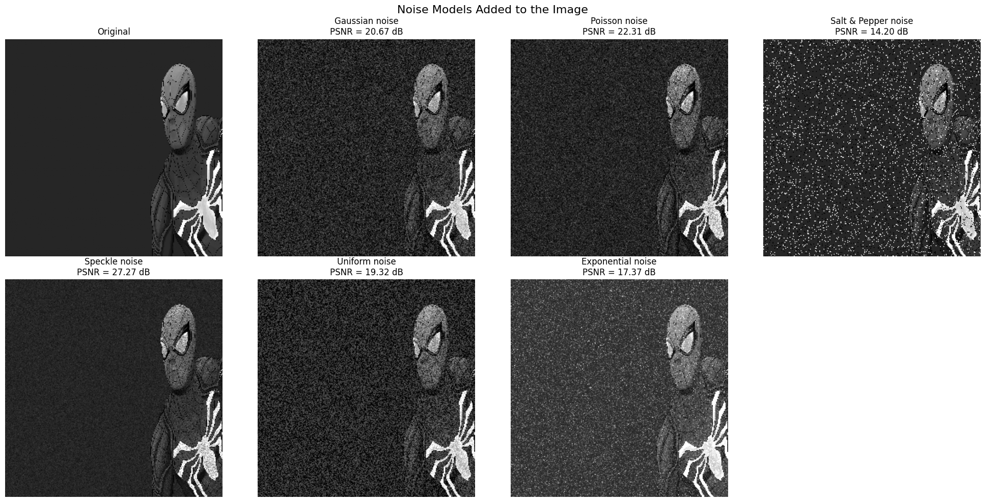

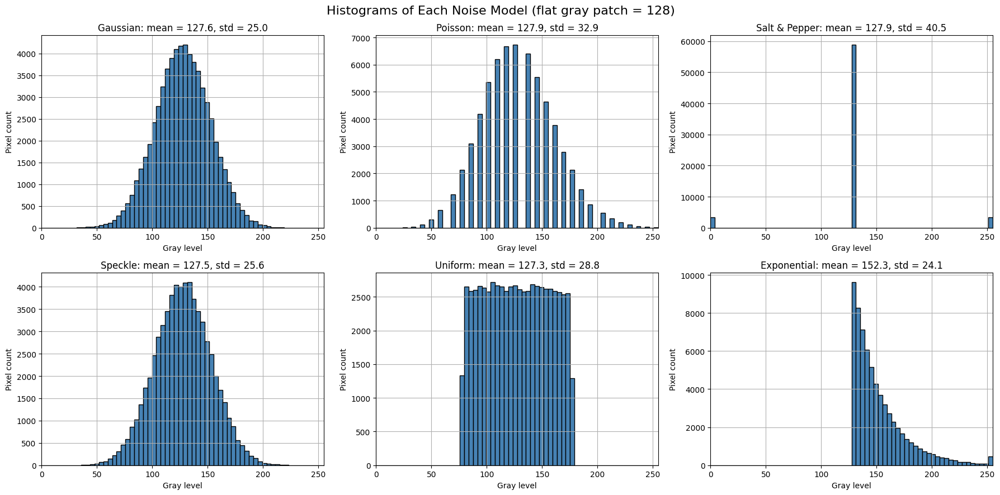

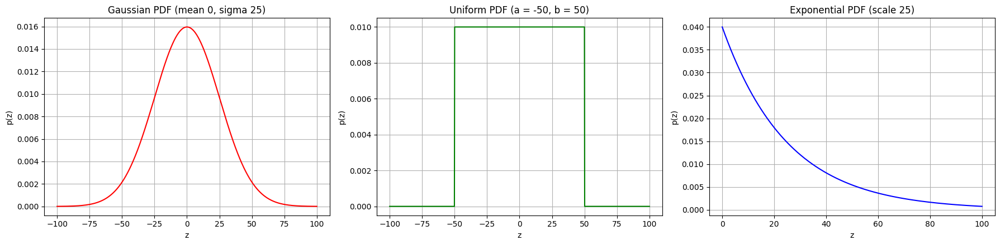


PSNR (dB) after denoising:
Noise           |   Noisy |      Box 3x3 | Gaussian 5x5 |   Median 3x3 |    Bilateral
-------------------------------------------------------------------------------------
Gaussian        |   20.67 |        23.95 |        24.53 |        24.89 |        28.90
Poisson         |   22.31 |        24.32 |        24.80 |        25.49 |        29.44
Salt & Pepper   |   14.20 |        20.74 |        21.43 |        26.65 |        14.36
Speckle         |   27.27 |        24.79 |        25.18 |        26.92 |        30.12
Uniform         |   19.32 |        23.59 |        24.18 |        22.93 |        27.01
Exponential     |   17.37 |        18.81 |        18.98 |        20.87 |        20.12


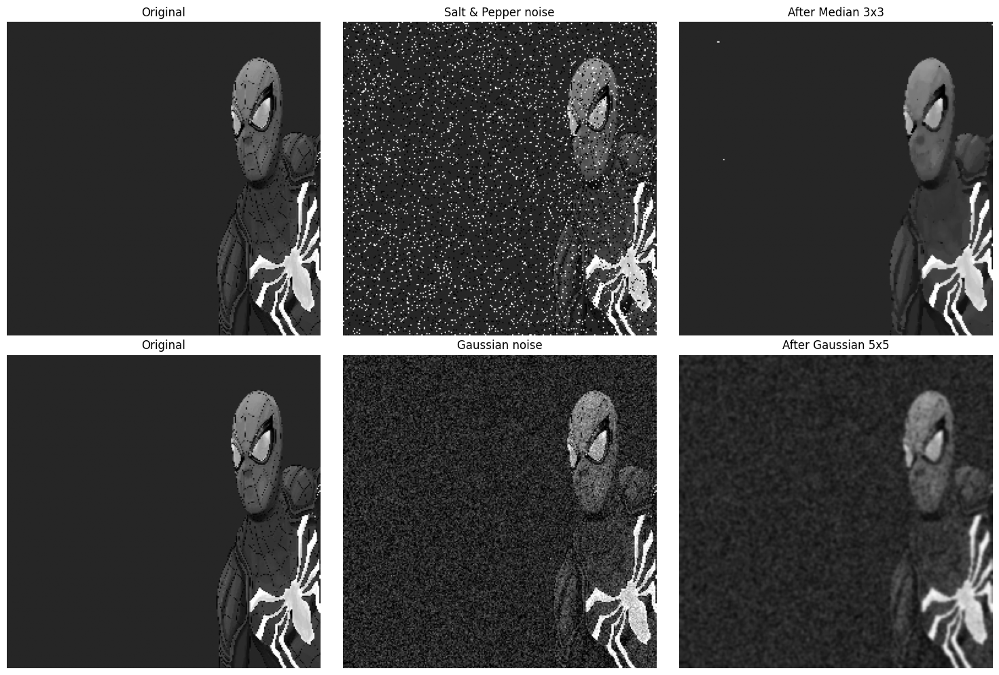

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))
f = gray.astype(np.float32)
print("Image size:", gray.shape)

rng = np.random.default_rng(42)

def to_u8(x):
    return np.clip(x, 0, 255).astype(np.uint8)

# ---------------------------------------------------
# 2. NOISE MODELS (each function takes any float image in 0-255)
# ---------------------------------------------------
def gaussian_noise(img, mean=0, sigma=25):
    # p(z) = 1/(sqrt(2*pi)*sigma) * exp(-(z-mean)^2 / (2*sigma^2))
    return to_u8(img + rng.normal(mean, sigma, img.shape))

def poisson_noise(img, peak=30):
    # Signal-dependent (photon / shot noise): counts ~ Poisson(lambda = intensity * peak / 255)
    lam = img / 255.0 * peak
    return to_u8(rng.poisson(lam) / peak * 255.0)

def salt_pepper_noise(img, ps=0.05, pp=0.05):
    # Impulse noise: salt (255) with prob ps, pepper (0) with prob pp
    out = img.copy()
    r = rng.random(img.shape)
    out[r < pp] = 0
    out[(r >= pp) & (r < pp + ps)] = 255
    return to_u8(out)

def speckle_noise(img, sigma=0.2):
    # Multiplicative noise: g = f + f * n, n ~ N(0, sigma^2)
    n = rng.normal(0, sigma, img.shape)
    return to_u8(img + img * n)

def uniform_noise(img, a=-50, b=50):
    # p(z) = 1/(b-a) for a <= z <= b, else 0
    return to_u8(img + rng.uniform(a, b, img.shape))

def exponential_noise(img, scale=25):
    # p(z) = (1/scale) * exp(-z/scale) for z >= 0 (mean = scale, variance = scale^2)
    return to_u8(img + rng.exponential(scale, img.shape))

noise_fns = {
    "Gaussian":       gaussian_noise,
    "Poisson":        poisson_noise,
    "Salt & Pepper":  salt_pepper_noise,
    "Speckle":        speckle_noise,
    "Uniform":        uniform_noise,
    "Exponential":    exponential_noise,
}

noisy_imgs = {name: fn(f) for name, fn in noise_fns.items()}

# ---------------------------------------------------
# 3. METRICS
# ---------------------------------------------------
def mse(a, b):
    return np.mean((a.astype(np.float32) - b.astype(np.float32)) ** 2)

def psnr(a, b):
    m = mse(a, b)
    return 10 * np.log10(255 ** 2 / m) if m > 0 else float("inf")

print("\nNoise type       |   MSE     | PSNR (dB)")
print("-" * 40)
for name, im in noisy_imgs.items():
    print(f"{name:16s} | {mse(gray, im):9.2f} | {psnr(gray, im):6.2f}")

# ---------------------------------------------------
# 4. DISPLAY NOISY IMAGES
# ---------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
items = [("Original", gray)] + list(noisy_imgs.items())
for ax, (t, im) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t if t == "Original" else f"{t} noise\nPSNR = {psnr(gray, im):.2f} dB")
    ax.axis("off")
axes.ravel()[-1].axis("off")
plt.suptitle("Noise Models Added to the Image", fontsize=16)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 5. NOISE HISTOGRAMS on a flat gray patch (shows the PDF shape)
# ---------------------------------------------------
flat = np.full((256, 256), 128, dtype=np.float32)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (name, fn) in zip(axes.ravel(), noise_fns.items()):
    patch = fn(flat)
    ax.hist(patch.ravel(), bins=64, range=(0, 255), color="steelblue", edgecolor="black")
    ax.set_title(f"{name}: mean = {patch.mean():.1f}, std = {patch.std():.1f}")
    ax.set_xlabel("Gray level"); ax.set_ylabel("Pixel count")
    ax.set_xlim(0, 255); ax.grid(True)
plt.suptitle("Histograms of Each Noise Model (flat gray patch = 128)", fontsize=16)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 6. THEORETICAL PDFs
# ---------------------------------------------------
z = np.linspace(-100, 100, 1000)
zp = np.linspace(0, 100, 1000)
sigma, scale, a, b = 25, 25, -50, 50

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(z, np.exp(-z ** 2 / (2 * sigma ** 2)) / (np.sqrt(2 * np.pi) * sigma), "r")
axes[0].set_title("Gaussian PDF (mean 0, sigma 25)")
axes[1].plot(z, np.where((z >= a) & (z <= b), 1 / (b - a), 0), "g")
axes[1].set_title("Uniform PDF (a = -50, b = 50)")
axes[2].plot(zp, np.exp(-zp / scale) / scale, "b")
axes[2].set_title("Exponential PDF (scale 25)")
for ax in axes:
    ax.set_xlabel("z"); ax.set_ylabel("p(z)"); ax.grid(True)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 7. WHICH FILTER SUITS WHICH NOISE?  (PSNR after filtering)
# ---------------------------------------------------
filters = {
    "Box 3x3":      lambda x: cv2.blur(x, (3, 3)),
    "Gaussian 5x5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median 3x3":   lambda x: cv2.medianBlur(x, 3),
    "Bilateral":    lambda x: cv2.bilateralFilter(x, 7, 50, 50),
}

print("\nPSNR (dB) after denoising:")
header = f"{'Noise':16s}| {'Noisy':>7s} | " + " | ".join(f"{k:>12s}" for k in filters)
print(header)
print("-" * len(header))
for name, im in noisy_imgs.items():
    row = f"{name:16s}| {psnr(gray, im):7.2f} | "
    row += " | ".join(f"{psnr(gray, fn(im)):12.2f}" for fn in filters.values())
    print(row)

# Visual: salt & pepper and Gaussian, before and after the best filter
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for r_i, (nm, flt, fname) in enumerate([("Salt & Pepper", filters["Median 3x3"], "Median 3x3"),
                                        ("Gaussian", filters["Gaussian 5x5"], "Gaussian 5x5")]):
    axes[r_i, 0].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[r_i, 0].set_title("Original")
    axes[r_i, 1].imshow(noisy_imgs[nm], cmap="gray", vmin=0, vmax=255); axes[r_i, 1].set_title(f"{nm} noise")
    axes[r_i, 2].imshow(flt(noisy_imgs[nm]), cmap="gray", vmin=0, vmax=255)
    axes[r_i, 2].set_title(f"After {fname}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (10).jpg
Image size: (256, 256)
Running adaptive median filter (takes a few seconds)...

--- Gaussian noise (sigma = 20) ---
Noisy image                 :  22.42 dB
Arithmetic mean 3x3         :  24.48 dB
Geometric mean 3x3          :  21.73 dB
Harmonic mean 3x3           :  17.94 dB
Median 3x3                  :  25.96 dB
Midpoint 3x3                :  21.88 dB
Alpha-trimmed 5x5 d=6       :  23.45 dB
Adaptive local noise        :  30.42 dB
Adaptive Wiener 5x5         :  30.15 dB

--- Salt & pepper noise (5% + 5%) ---
Noisy image                 :  14.41 dB
Arithmetic mean 3x3         :  20.95 dB
Median 3x3                  :  26.70 dB
Max 3x3 (removes pepper)    :   5.94 dB
Min 3x3 (removes salt)      :  15.25 dB
Alpha-trimmed 5x5 d=10      :  23.75 dB
Adaptive median Smax=7      :  28.67 dB

--- Contraharmonic mean ---
Pepper noise only          :  22.55 dB
  Q = +1.5 (correct sign)  :  21.20 dB
  Q =

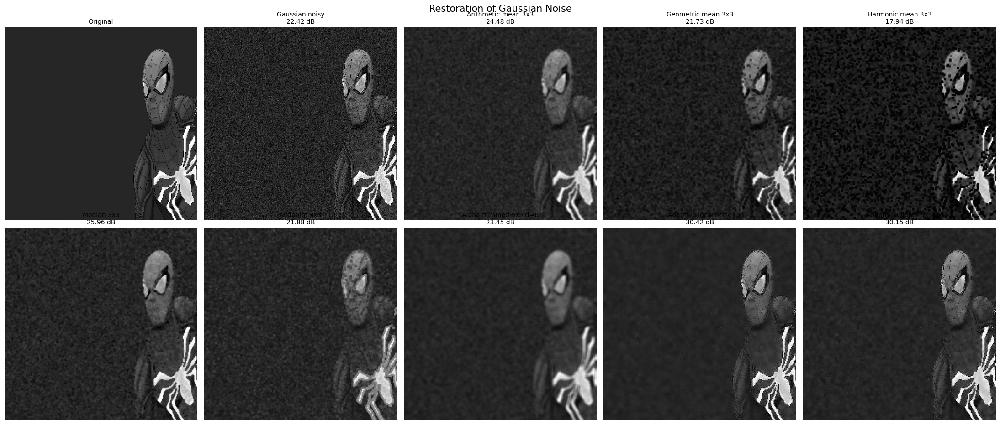

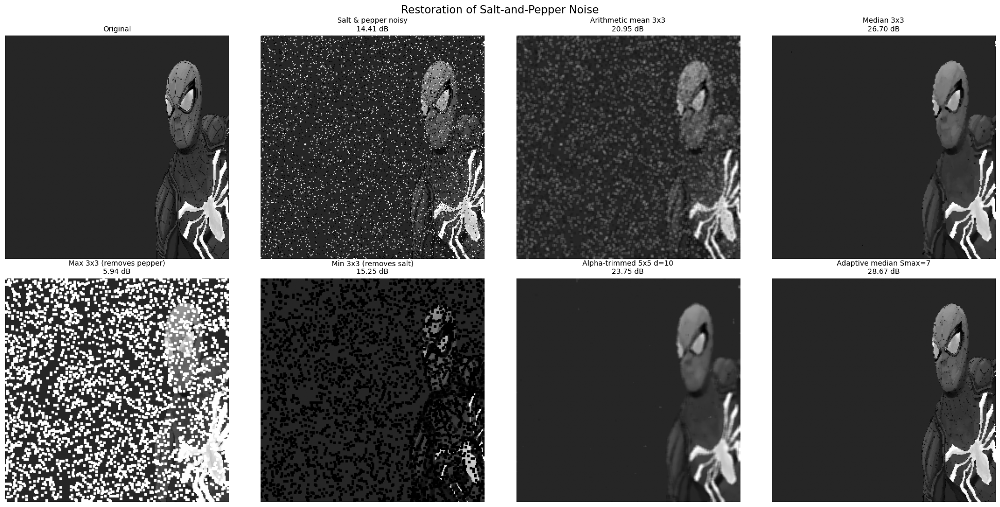

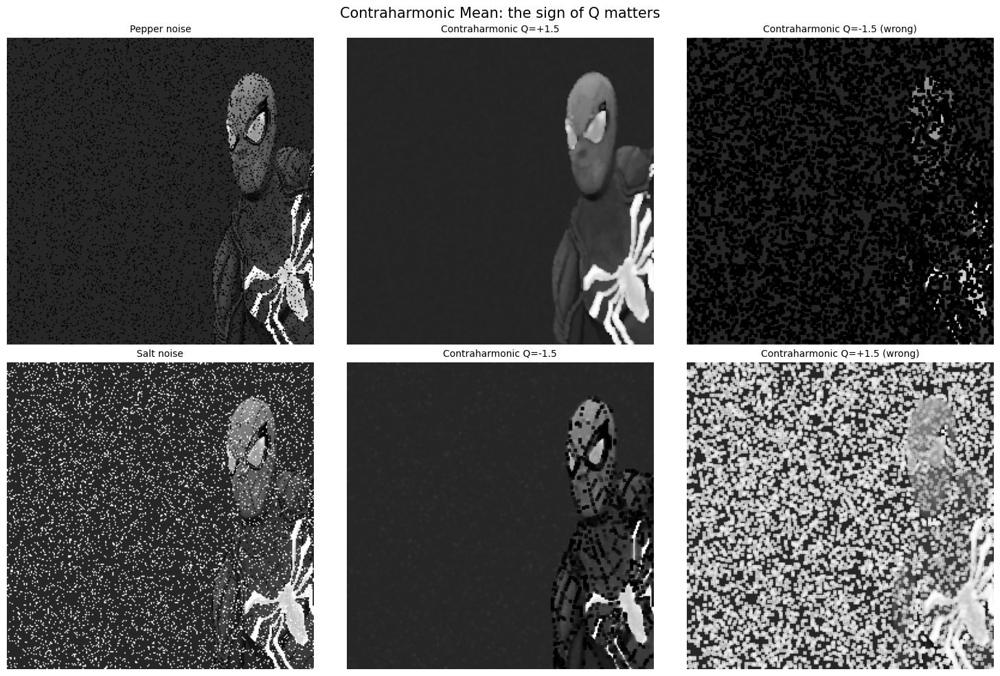


--- Wiener deconvolution (Gaussian blur + noise) ---
Degraded image   :  22.57 dB
Inverse filter   :   4.82 dB
Wiener (K=0.01923):  23.91 dB


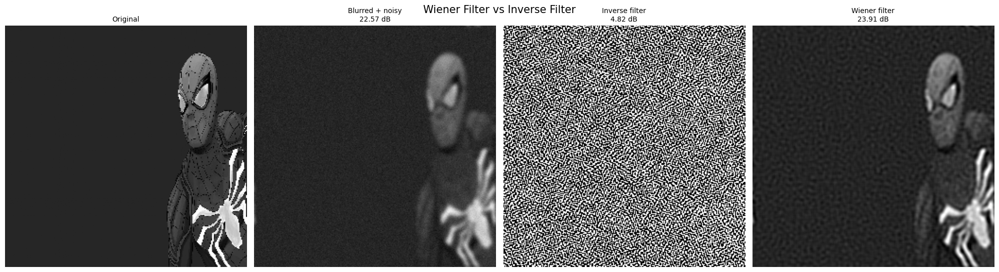

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))
f = gray.astype(np.float32)
H_, W_ = gray.shape
print("Image size:", gray.shape)

rng = np.random.default_rng(1)
to_u8 = lambda x: np.clip(x, 0, 255).astype(np.uint8)

def psnr(a, b):
    mse = np.mean((a.astype(np.float32) - b.astype(np.float32)) ** 2)
    return 10 * np.log10(255 ** 2 / mse) if mse > 0 else float("inf")

# ---------------------------------------------------
# 2. DEGRADED IMAGES
# ---------------------------------------------------
sigma_n = 20
gauss_noisy = to_u8(f + rng.normal(0, sigma_n, f.shape))

def impulse(img, ps, pp):
    out = img.copy(); r = rng.random(img.shape)
    out[r < pp] = 0
    out[(r >= pp) & (r < pp + ps)] = 255
    return out

sp_noisy = impulse(gray, 0.05, 0.05)        # salt & pepper
pepper_noisy = impulse(gray, 0.0, 0.10)     # pepper only
salt_noisy = impulse(gray, 0.10, 0.0)       # salt only

# ---------------------------------------------------
# 3. MEAN FILTERS (3x3 window)
# ---------------------------------------------------
def box(x, k):
    return cv2.boxFilter(x, -1, (k, k), borderType=cv2.BORDER_REFLECT)

def arithmetic_mean(img, k=3):
    return to_u8(box(img.astype(np.float32), k))

def geometric_mean(img, k=3):
    x = img.astype(np.float32) + 1.0
    return to_u8(np.exp(box(np.log(x), k)) - 1.0)          # (prod)^(1/mn)

def harmonic_mean(img, k=3):
    x = img.astype(np.float32) + 1.0
    return to_u8(1.0 / box(1.0 / x, k) - 1.0)               # mn / sum(1/g)

def contraharmonic_mean(img, k=3, Q=1.5):
    x = img.astype(np.float32) / 255.0 + 1e-3                # scale to avoid overflow
    num = box(x ** (Q + 1), k)
    den = box(x ** Q, k)
    return to_u8((num / den - 1e-3) * 255.0)                 # sum g^(Q+1) / sum g^Q

# ---------------------------------------------------
# 4. ORDER-STATISTIC FILTERS
# ---------------------------------------------------
def median_filter(img, k=3):   return cv2.medianBlur(img, k)
def max_filter(img, k=3):      return cv2.dilate(img, np.ones((k, k), np.uint8))
def min_filter(img, k=3):      return cv2.erode(img, np.ones((k, k), np.uint8))
def midpoint_filter(img, k=3):
    return to_u8((max_filter(img, k).astype(np.float32) + min_filter(img, k).astype(np.float32)) / 2)

def alpha_trimmed_mean(img, k=5, d=6):
    # remove the d/2 lowest and d/2 highest values, average the remaining mn-d values
    p = np.pad(img, k // 2, mode="reflect").astype(np.float32)
    win = np.lib.stride_tricks.sliding_window_view(p, (k, k)).reshape(img.shape[0], img.shape[1], k * k)
    win = np.sort(win, axis=2)
    return to_u8(win[:, :, d // 2: k * k - d // 2].mean(axis=2))

# ---------------------------------------------------
# 5. ADAPTIVE FILTERS
# ---------------------------------------------------
def local_stats(img, k):
    x = img.astype(np.float32)
    m = box(x, k)
    var = np.maximum(box(x * x, k) - m * m, 0)
    return m, var

def adaptive_local_noise(img, noise_var, k=7):
    # f^ = g - (var_noise / var_local) * (g - mean_local), ratio capped at 1
    g = img.astype(np.float32)
    m, var = local_stats(img, k)
    ratio = np.minimum(noise_var / np.maximum(var, 1e-6), 1.0)
    return to_u8(g - ratio * (g - m))

def adaptive_median(img, smax=7):
    pad = smax // 2
    p = np.pad(img, pad, mode="reflect")
    out = img.copy()
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            k = 3
            while True:
                r = k // 2
                w = p[i + pad - r: i + pad + r + 1, j + pad - r: j + pad + r + 1]
                zmin, zmax, zmed = w.min(), w.max(), np.median(w)
                if zmin < zmed < zmax:                      # Level A passed
                    z = img[i, j]
                    out[i, j] = z if zmin < z < zmax else zmed   # Level B
                    break
                k += 2
                if k > smax:
                    out[i, j] = zmed
                    break
    return out

def wiener_adaptive(img, noise_var=None, k=5):
    # f^ = m + max(0, var - nv) / max(var, nv) * (g - m)
    g = img.astype(np.float32)
    m, var = local_stats(img, k)
    if noise_var is None:
        noise_var = var.mean()                  # estimate when unknown
    gain = np.maximum(var - noise_var, 0) / np.maximum(np.maximum(var, noise_var), 1e-6)
    return to_u8(m + gain * (g - m))

# ---------------------------------------------------
# 6. APPLY FILTERS
# ---------------------------------------------------
# (A) Gaussian noise
gA = {
    "Arithmetic mean 3x3":   arithmetic_mean(gauss_noisy),
    "Geometric mean 3x3":    geometric_mean(gauss_noisy),
    "Harmonic mean 3x3":     harmonic_mean(gauss_noisy),
    "Median 3x3":            median_filter(gauss_noisy),
    "Midpoint 3x3":          midpoint_filter(gauss_noisy),
    "Alpha-trimmed 5x5 d=6": alpha_trimmed_mean(gauss_noisy, 5, 6),
    "Adaptive local noise":  adaptive_local_noise(gauss_noisy, sigma_n ** 2),
    "Adaptive Wiener 5x5":   wiener_adaptive(gauss_noisy, sigma_n ** 2),
}

# (B) Salt-and-pepper noise
print("Running adaptive median filter (takes a few seconds)...")
gB = {
    "Arithmetic mean 3x3":   arithmetic_mean(sp_noisy),
    "Median 3x3":            median_filter(sp_noisy),
    "Max 3x3 (removes pepper)": max_filter(sp_noisy),
    "Min 3x3 (removes salt)":   min_filter(sp_noisy),
    "Alpha-trimmed 5x5 d=10":   alpha_trimmed_mean(sp_noisy, 5, 10),
    "Adaptive median Smax=7":   adaptive_median(sp_noisy, 7),
}

# (C) Contraharmonic on single-polarity impulse noise
cp = contraharmonic_mean(pepper_noisy, 3, Q=1.5)     # positive Q removes pepper
cs = contraharmonic_mean(salt_noisy, 3, Q=-1.5)      # negative Q removes salt
cw = contraharmonic_mean(pepper_noisy, 3, Q=-1.5)    # wrong sign -> makes it worse

# ---------------------------------------------------
# 7. PSNR TABLES
# ---------------------------------------------------
print("\n--- Gaussian noise (sigma = 20) ---")
print(f"{'Noisy image':28s}: {psnr(gray, gauss_noisy):6.2f} dB")
for k, v in gA.items():
    print(f"{k:28s}: {psnr(gray, v):6.2f} dB")

print("\n--- Salt & pepper noise (5% + 5%) ---")
print(f"{'Noisy image':28s}: {psnr(gray, sp_noisy):6.2f} dB")
for k, v in gB.items():
    print(f"{k:28s}: {psnr(gray, v):6.2f} dB")

print("\n--- Contraharmonic mean ---")
print(f"Pepper noise only          : {psnr(gray, pepper_noisy):6.2f} dB")
print(f"  Q = +1.5 (correct sign)  : {psnr(gray, cp):6.2f} dB")
print(f"  Q = -1.5 (wrong sign)    : {psnr(gray, cw):6.2f} dB")
print(f"Salt noise only            : {psnr(gray, salt_noisy):6.2f} dB")
print(f"  Q = -1.5 (correct sign)  : {psnr(gray, cs):6.2f} dB")

# ---------------------------------------------------
# 8. DISPLAY
# ---------------------------------------------------
def show_grid(items, rows, cols, title, size=(20, 10)):
    fig, axes = plt.subplots(rows, cols, figsize=size)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (t, im) in zip(axes.ravel(), items):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=10)
    plt.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_grid([("Original", gray),
           (f"Gaussian noisy\n{psnr(gray, gauss_noisy):.2f} dB", gauss_noisy)] +
          [(f"{k}\n{psnr(gray, v):.2f} dB", v) for k, v in gA.items()],
          2, 5, "Restoration of Gaussian Noise", (22, 9.5))

show_grid([("Original", gray),
           (f"Salt & pepper noisy\n{psnr(gray, sp_noisy):.2f} dB", sp_noisy)] +
          [(f"{k}\n{psnr(gray, v):.2f} dB", v) for k, v in gB.items()],
          2, 4, "Restoration of Salt-and-Pepper Noise", (20, 10))

show_grid([("Pepper noise", pepper_noisy), ("Contraharmonic Q=+1.5", cp), ("Contraharmonic Q=-1.5 (wrong)", cw),
           ("Salt noise", salt_noisy), ("Contraharmonic Q=-1.5", cs), ("Contraharmonic Q=+1.5 (wrong)", contraharmonic_mean(salt_noisy, 3, 1.5))],
          2, 3, "Contraharmonic Mean: the sign of Q matters", (15, 10))

# ---------------------------------------------------
# 9. BONUS: WIENER DECONVOLUTION (blur + noise, frequency domain)
# ---------------------------------------------------
ks = 9
psf1 = cv2.getGaussianKernel(ks, 2.0)
psf = psf1 @ psf1.T
psf_pad = np.zeros_like(f); psf_pad[:ks, :ks] = psf
psf_pad = np.roll(psf_pad, (-(ks // 2), -(ks // 2)), axis=(0, 1))   # centre PSF at origin
Hf = np.fft.fft2(psf_pad)

blurred = np.real(np.fft.ifft2(np.fft.fft2(f) * Hf))
noise_sd = 5
degraded = to_u8(blurred + rng.normal(0, noise_sd, f.shape))
Gf = np.fft.fft2(degraded.astype(np.float32))

# Inverse filter (unstable: noise is amplified where |H| is tiny)
inv = np.where(np.abs(Hf) > 1e-3, 1 / Hf, 0)
restored_inv = to_u8(np.real(np.fft.ifft2(Gf * inv)))

# Wiener filter: W = conj(H) / (|H|^2 + K), K = noise power / signal power
K = noise_sd ** 2 / f.var()
W = np.conj(Hf) / (np.abs(Hf) ** 2 + K)
restored_wiener = to_u8(np.real(np.fft.ifft2(Gf * W)))

print("\n--- Wiener deconvolution (Gaussian blur + noise) ---")
print(f"Degraded image   : {psnr(gray, degraded):6.2f} dB")
print(f"Inverse filter   : {psnr(gray, restored_inv):6.2f} dB")
print(f"Wiener (K={K:.5f}): {psnr(gray, restored_wiener):6.2f} dB")

show_grid([("Original", gray),
           (f"Blurred + noisy\n{psnr(gray, degraded):.2f} dB", degraded),
           (f"Inverse filter\n{psnr(gray, restored_inv):.2f} dB", restored_inv),
           (f"Wiener filter\n{psnr(gray, restored_wiener):.2f} dB", restored_wiener)],
          1, 4, "Wiener Filter vs Inverse Filter", (20, 5.5))

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (11).jpg
Image size: (256, 256)

Periodic-noise image PSNR: 18.59 dB
Detected spikes (u0, v0): [(-20, 30), (-30, -20)]
Actual noise freqs      : [(30, 20), (20, -30)] (sign may be mirrored)
Ring radius D0 = 36.06, band width W = 14


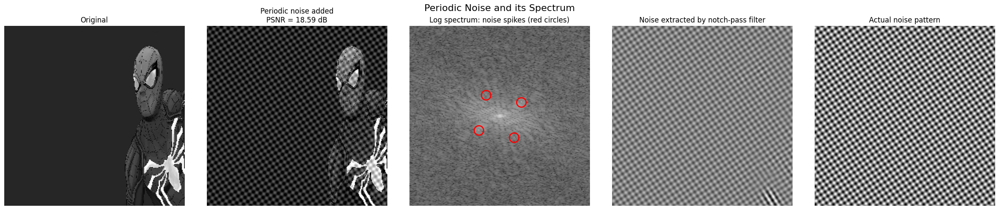


PSNR after periodic-noise removal:
Noisy image                       :  18.59 dB
Ideal band-reject                 :  27.43 dB
Butterworth band-reject (n=2)     :  28.41 dB
Gaussian band-reject              :  29.66 dB
Ideal notch reject (D0=6)         :  35.55 dB
Butterworth notch reject (D0=8)   :  34.22 dB
Gaussian notch reject (D0=8)      :  33.42 dB


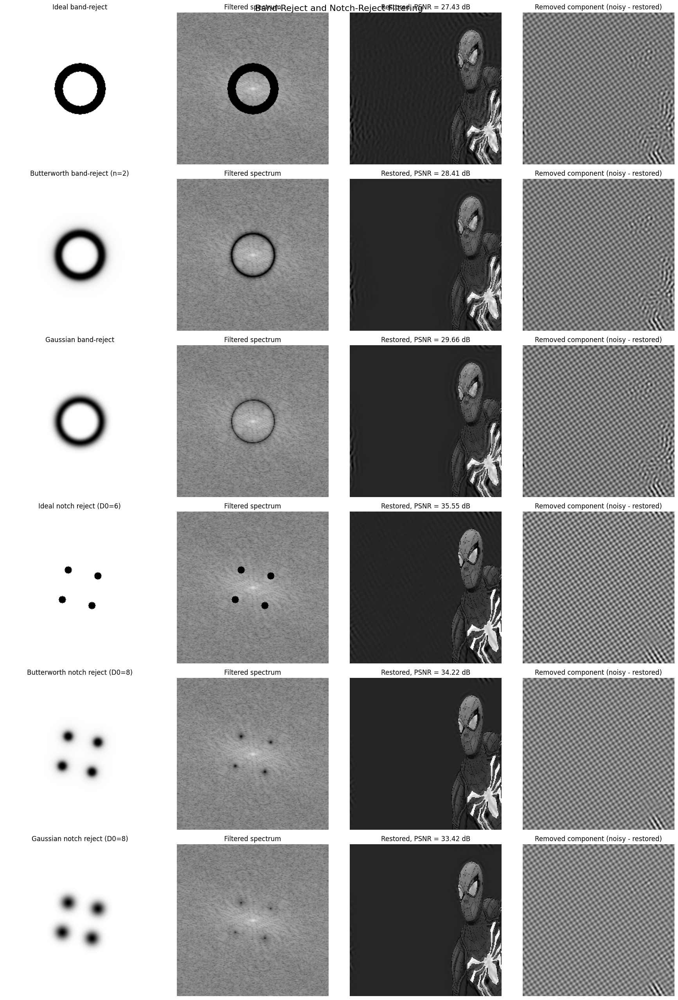

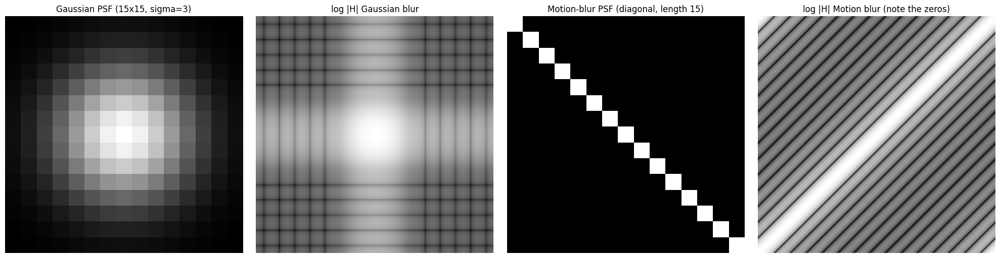


--- Gaussian blur, no noise ---
Degraded image            :  21.56 dB
Inverse filter            : 211.46 dB
Pseudo-inverse (|H|>=0.1) :  22.59 dB
Wiener, K = 1.00e-08 (sd^2/var):  29.50 dB
Wiener K sweep            : K=1e-06: 27.25, K=1e-05: 26.12, K=1e-04: 24.87, K=1e-03: 23.80, K=1e-02: 22.90, K=1e-01: 21.62
Lucy-Richardson 10/30/100 :  22.52 /  22.96 /  23.47 dB
LR best iteration         : 100 (23.47 dB)

--- Gaussian blur + noise (sd=5) ---
Degraded image            :  21.33 dB
Inverse filter            :   4.34 dB
Pseudo-inverse (|H|>=0.1) :  22.34 dB
Wiener, K = 1.92e-02 (sd^2/var):  22.49 dB
Wiener K sweep            : K=1e-06: 4.80, K=1e-05: 5.90, K=1e-04: 11.75, K=1e-03: 20.56, K=1e-02: 22.63, K=1e-01: 21.60
Lucy-Richardson 10/30/100 :  22.20 /  22.53 /  22.66 dB
LR best iteration         : 79 (22.68 dB)

--- Motion blur + noise (sd=3) ---
Degraded image            :  20.43 dB
Inverse filter            :   7.71 dB
Pseudo-inverse (|H|>=0.1) :  22.41 dB
Wiener, K = 6.92e-03 (sd

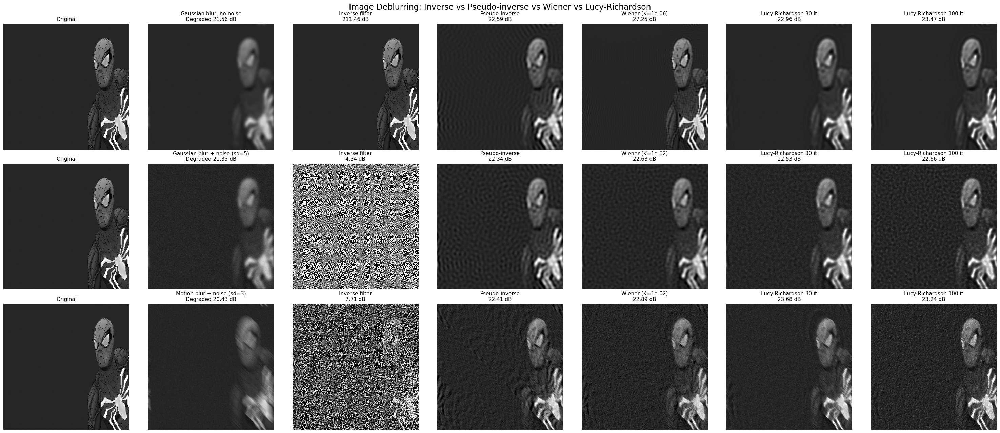

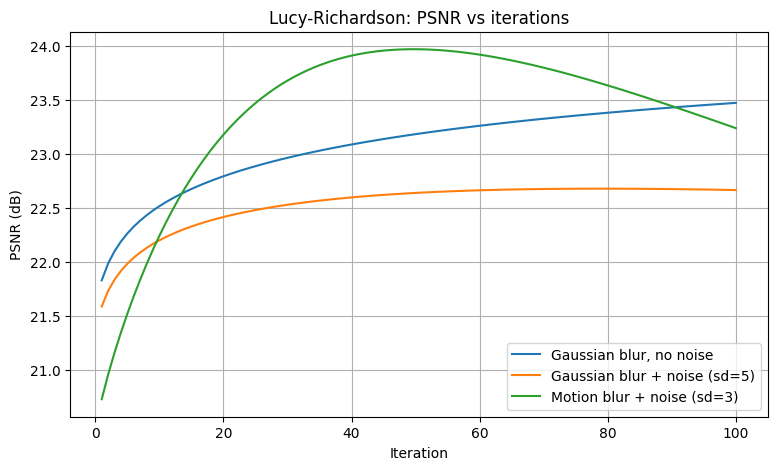

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))
f = gray.astype(np.float64)
M, N = f.shape
print("Image size:", gray.shape)

rng = np.random.default_rng(7)

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 10 * np.log10(255 ** 2 / mse) if mse > 0 else float("inf")

def clip255(x):
    return np.clip(x, 0, 255)

def norm255(x):
    x = x - x.min()
    return x / x.max() * 255 if x.max() > 0 else x

# Centred frequency coordinates and distance from the centre
u = np.arange(M) - M // 2
v = np.arange(N) - N // 2
V, U = np.meshgrid(v, u)
D = np.sqrt(U ** 2 + V ** 2)

def to_freq(img):
    return np.fft.fftshift(np.fft.fft2(img))

def to_space(Fs):
    return np.real(np.fft.ifft2(np.fft.ifftshift(Fs)))

# =====================================================================
# PART A: PERIODIC NOISE REMOVAL (BAND-REJECT AND NOTCH FILTERS)
# =====================================================================

# ---------------------------------------------------
# A1. Add periodic (sinusoidal) noise: A*sin(2*pi*(u0*x/M + v0*y/N))
# ---------------------------------------------------
x = np.arange(M)[:, None]
y = np.arange(N)[None, :]
components = [(30, 20, 30), (20, -30, 30)]          # (u0, v0, amplitude), both on one ring
pnoise = np.zeros((M, N))
for (u0, v0, A) in components:
    pnoise += A * np.sin(2 * np.pi * (u0 * x / M + v0 * y / N))
noisy = f + pnoise
print(f"\nPeriodic-noise image PSNR: {psnr(f, noisy):.2f} dB")

# ---------------------------------------------------
# A2. Find the noise spikes in the spectrum automatically
# ---------------------------------------------------
Fn = to_freq(noisy)
mag = np.abs(Fn)
work = mag.copy()
work[D <= 20] = 0                                    # ignore the low-frequency centre
work[(np.abs(U) <= 3) | (np.abs(V) <= 3)] = 0        # ignore axes (border-edge artefacts)

notches = []
for _ in range(len(components)):
    r, c = np.unravel_index(np.argmax(work), work.shape)
    u0, v0 = int(U[r, c]), int(V[r, c])
    notches.append((u0, v0))
    work[((U - u0) ** 2 + (V - v0) ** 2 <= 100) | ((U + u0) ** 2 + (V + v0) ** 2 <= 100)] = 0

print("Detected spikes (u0, v0):", notches)
print("Actual noise freqs      :", [(a, b) for a, b, _ in components], "(sign may be mirrored)")

D0_ring = np.mean([np.hypot(a, b) for a, b in notches])   # radius of the noise ring
W = 14                                                    # band width
print(f"Ring radius D0 = {D0_ring:.2f}, band width W = {W}")

# ---------------------------------------------------
# A3. Filter definitions
# ---------------------------------------------------
def ideal_br(D, D0, W):
    return np.where((D >= D0 - W / 2) & (D <= D0 + W / 2), 0.0, 1.0)

def butter_br(D, D0, W, n=2):
    Ds = np.where(D == 0, 1e-6, D)
    with np.errstate(divide="ignore", over="ignore"):
        ratio = (Ds * W) / (Ds ** 2 - D0 ** 2)
        return 1 / (1 + ratio ** (2 * n))

def gauss_br(D, D0, W):
    Ds = np.where(D == 0, 1e-6, D)
    return 1 - np.exp(-(((Ds ** 2 - D0 ** 2) / (Ds * W)) ** 2))

def notch_d(u0, v0):
    return np.sqrt((U - u0) ** 2 + (V - v0) ** 2), np.sqrt((U + u0) ** 2 + (V + v0) ** 2)

def ideal_notch(notches, D0):
    H = np.ones((M, N))
    for (u0, v0) in notches:
        d1, d2 = notch_d(u0, v0)
        H[(d1 <= D0) | (d2 <= D0)] = 0
    return H

def butter_notch(notches, D0, n=2):
    H = np.ones((M, N))
    for (u0, v0) in notches:
        d1, d2 = notch_d(u0, v0)
        d1, d2 = np.maximum(d1, 1e-6), np.maximum(d2, 1e-6)
        H *= (1 / (1 + (D0 / d1) ** (2 * n))) * (1 / (1 + (D0 / d2) ** (2 * n)))
    return H

def gauss_notch(notches, D0):
    H = np.ones((M, N))
    for (u0, v0) in notches:
        d1, d2 = notch_d(u0, v0)
        H *= (1 - np.exp(-d1 ** 2 / (2 * D0 ** 2))) * (1 - np.exp(-d2 ** 2 / (2 * D0 ** 2)))
    return H

def apply_H(img, H):
    G = to_freq(img) * H
    return to_space(G), G

# ---------------------------------------------------
# A4. Notch-pass filter extracts the noise pattern itself
# ---------------------------------------------------
H_nr = butter_notch(notches, 8, 2)
noise_est, _ = apply_H(noisy, 1 - H_nr)

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[0].set_title("Original")
axes[1].imshow(clip255(noisy), cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Periodic noise added\nPSNR = {psnr(f, noisy):.2f} dB")
axes[2].imshow(np.log(1 + mag), cmap="gray")
for (u0, v0) in notches:
    for s in (1, -1):
        axes[2].plot(N // 2 + s * v0, M // 2 + s * u0, "ro", mfc="none", ms=16, mew=2)
axes[2].set_title("Log spectrum: noise spikes (red circles)")
axes[3].imshow(norm255(noise_est), cmap="gray"); axes[3].set_title("Noise extracted by notch-pass filter")
axes[4].imshow(norm255(pnoise), cmap="gray");    axes[4].set_title("Actual noise pattern")
for ax in axes:
    ax.axis("off")
plt.suptitle("Periodic Noise and its Spectrum", fontsize=16)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# A5. Apply band-reject and notch-reject filters
# ---------------------------------------------------
filters = {
    "Ideal band-reject":              ideal_br(D, D0_ring, W),
    "Butterworth band-reject (n=2)":  butter_br(D, D0_ring, W, 2),
    "Gaussian band-reject":           gauss_br(D, D0_ring, W),
    "Ideal notch reject (D0=6)":      ideal_notch(notches, 6),
    "Butterworth notch reject (D0=8)": butter_notch(notches, 8, 2),
    "Gaussian notch reject (D0=8)":   gauss_notch(notches, 8),
}

print("\nPSNR after periodic-noise removal:")
print(f"{'Noisy image':34s}: {psnr(f, noisy):6.2f} dB")
fig, axes = plt.subplots(6, 4, figsize=(18, 26))
for row, (name, H) in enumerate(filters.items()):
    raw, G = apply_H(noisy, H)
    restored = clip255(raw)
    p = psnr(f, restored)
    print(f"{name:34s}: {p:6.2f} dB")
    axes[row, 0].imshow(H, cmap="gray", vmin=0, vmax=1);          axes[row, 0].set_title(name)
    axes[row, 1].imshow(np.log(1 + np.abs(G)), cmap="gray");       axes[row, 1].set_title("Filtered spectrum")
    axes[row, 2].imshow(restored, cmap="gray", vmin=0, vmax=255);  axes[row, 2].set_title(f"Restored, PSNR = {p:.2f} dB")
    axes[row, 3].imshow(norm255(noisy - raw), cmap="gray");        axes[row, 3].set_title("Removed component (noisy - restored)")
    for ax in axes[row]:
        ax.axis("off")
plt.suptitle("Band-Reject and Notch-Reject Filtering", fontsize=16)
plt.tight_layout()
plt.show()

# =====================================================================
# PART B: DEBLURRING (INVERSE, WIENER, LUCY-RICHARDSON)
# =====================================================================

def psf2otf(psf, shape):
    pad = np.zeros(shape)
    kh, kw = psf.shape
    pad[:kh, :kw] = psf
    pad = np.roll(pad, (-(kh // 2), -(kw // 2)), axis=(0, 1))   # centre PSF at the origin
    return np.fft.fft2(pad)

g1 = cv2.getGaussianKernel(15, 3.0)
psf_gauss = g1 @ g1.T                      # Gaussian blur, sigma = 3
psf_motion = np.eye(15) / 15               # diagonal motion blur, length 15

def inverse_filter(G, H, thresh):
    Hinv = np.zeros_like(H)
    m = np.abs(H) > thresh
    Hinv[m] = 1 / H[m]
    return np.real(np.fft.ifft2(G * Hinv))

def wiener(G, H, K):
    return np.real(np.fft.ifft2(G * np.conj(H) / (np.abs(H) ** 2 + K)))

def lucy_richardson(g, H, iters, f_true, snap_at=(10, 30, 100)):
    g = np.maximum(g, 1e-3)
    est = g.copy()
    curve, snaps = [], {}
    for i in range(1, iters + 1):
        conv = np.real(np.fft.ifft2(np.fft.fft2(est) * H))
        ratio = g / np.maximum(conv, 1e-3)
        est = est * np.real(np.fft.ifft2(np.fft.fft2(ratio) * np.conj(H)))
        est = np.maximum(est, 0)
        curve.append(psnr(f_true, clip255(est)))
        if i in snap_at:
            snaps[i] = est.copy()
    return snaps, curve

# ---------------------------------------------------
# B1. PSFs and their frequency responses
# ---------------------------------------------------
Hg = psf2otf(psf_gauss, f.shape)
Hm = psf2otf(psf_motion, f.shape)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(psf_gauss, cmap="gray");  axes[0].set_title("Gaussian PSF (15x15, sigma=3)")
axes[1].imshow(np.log(1e-8 + np.fft.fftshift(np.abs(Hg))), cmap="gray"); axes[1].set_title("log |H| Gaussian blur")
axes[2].imshow(psf_motion, cmap="gray"); axes[2].set_title("Motion-blur PSF (diagonal, length 15)")
axes[3].imshow(np.log(1e-8 + np.fft.fftshift(np.abs(Hm))), cmap="gray"); axes[3].set_title("log |H| Motion blur (note the zeros)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# B2. Degrade, restore, compare
# ---------------------------------------------------
cases = [("Gaussian blur, no noise",       Hg, 0.0),
         ("Gaussian blur + noise (sd=5)",  Hg, 5.0),
         ("Motion blur + noise (sd=3)",    Hm, 3.0)]
Ks = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
ITERS = 100

fig, axes = plt.subplots(3, 7, figsize=(30, 13))
curves = {}
for row, (cname, H, sd) in enumerate(cases):
    degraded = np.real(np.fft.ifft2(np.fft.fft2(f) * H))
    if sd > 0:
        degraded = degraded + rng.normal(0, sd, f.shape)
    G = np.fft.fft2(degraded)

    inv = inverse_filter(G, H, 1e-10)                 # plain inverse filter
    pinv = inverse_filter(G, H, 0.1)                  # pseudo-inverse: ignore |H| < 0.1

    K_theory = max(sd ** 2 / f.var(), 1e-8)           # K = noise power / signal power (crude)
    w_theory = wiener(G, H, K_theory)
    psnr_K = [psnr(f, clip255(wiener(G, H, K))) for K in Ks]
    K_best = Ks[int(np.argmax(psnr_K))]
    w_best = wiener(G, H, K_best)

    snaps, curve = lucy_richardson(degraded, H, ITERS, f)
    curves[cname] = curve
    best_it = int(np.argmax(curve)) + 1

    print(f"\n--- {cname} ---")
    print(f"Degraded image            : {psnr(f, clip255(degraded)):6.2f} dB")
    print(f"Inverse filter            : {psnr(f, clip255(inv)):6.2f} dB")
    print(f"Pseudo-inverse (|H|>=0.1) : {psnr(f, clip255(pinv)):6.2f} dB")
    print(f"Wiener, K = {K_theory:.2e} (sd^2/var): {psnr(f, clip255(w_theory)):6.2f} dB")
    print("Wiener K sweep            : " + ", ".join(f"K={K:.0e}: {p:.2f}" for K, p in zip(Ks, psnr_K)))
    print(f"Lucy-Richardson 10/30/100 : {curve[9]:6.2f} / {curve[29]:6.2f} / {curve[99]:6.2f} dB")
    print(f"LR best iteration         : {best_it} ({max(curve):.2f} dB)")

    items = [("Original", gray),
             (f"{cname}\nDegraded {psnr(f, clip255(degraded)):.2f} dB", degraded),
             (f"Inverse filter\n{psnr(f, clip255(inv)):.2f} dB", inv),
             (f"Pseudo-inverse\n{psnr(f, clip255(pinv)):.2f} dB", pinv),
             (f"Wiener (K={K_best:.0e})\n{psnr(f, clip255(w_best)):.2f} dB", w_best),
             (f"Lucy-Richardson 30 it\n{curve[29]:.2f} dB", snaps[30]),
             (f"Lucy-Richardson 100 it\n{curve[99]:.2f} dB", snaps[100])]
    for ax, (t, im) in zip(axes[row], items):
        ax.imshow(clip255(im), cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=11)
        ax.axis("off")

plt.suptitle("Image Deblurring: Inverse vs Pseudo-inverse vs Wiener vs Lucy-Richardson", fontsize=17)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# B3. Lucy-Richardson: PSNR versus number of iterations
# ---------------------------------------------------
plt.figure(figsize=(9, 5))
for cname, curve in curves.items():
    plt.plot(range(1, ITERS + 1), curve, label=cname)
plt.xlabel("Iteration"); plt.ylabel("PSNR (dB)")
plt.title("Lucy-Richardson: PSNR vs iterations")
plt.legend(); plt.grid(True)
plt.show()

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (13).jpg
Image size: (225, 400)
Canny thresholds: low = 25, high = 50


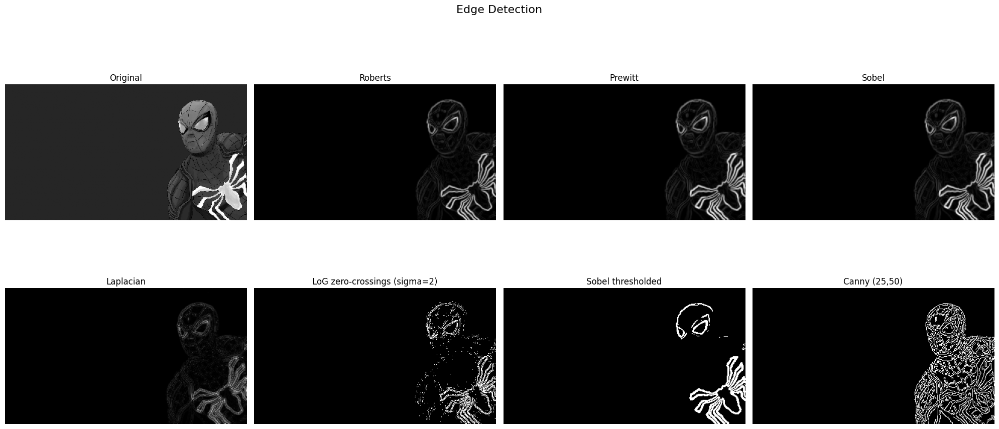


Edge pixels voting: 5921 | accumulator size: (919, 180)

Top Hough peaks (rho, theta, votes):
  rho =   320, theta =   45.0 deg, votes = 93
  rho =   339, theta =   45.0 deg, votes = 90
  rho =   320, theta =  -13.0 deg, votes = 88
  rho =   305, theta =  -19.0 deg, votes = 88
  rho =   322, theta =   16.0 deg, votes = 88
  rho =   324, theta =   11.0 deg, votes = 88
  rho =   334, theta =   17.0 deg, votes = 83
  rho =   351, theta =   45.0 deg, votes = 81
  rho =   151, theta =  -45.0 deg, votes = 80
  rho =   328, theta =  -11.0 deg, votes = 80
  rho =   260, theta =  -28.0 deg, votes = 79
  rho =   301, theta =   -1.0 deg, votes = 79

Edge pixels before linking : 5921
Gap pixels added by Hough  : 1153
Edge pixels after linking  : 7074
Connected edge segments    : 246 -> 127


TypeError: cannot unpack non-iterable numpy.int32 object

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

bgr = cv2.imread(img_path)
h0, w0 = bgr.shape[:2]
s = 400 / max(h0, w0)                         # keep the image small so the manual Hough is fast
bgr = cv2.resize(bgr, (int(w0 * s), int(h0 * s)))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
H, W = gray.shape
print("Image size:", gray.shape)

def norm255(x):
    x = np.abs(x).astype(np.float32)
    return (x / x.max() * 255).astype(np.uint8) if x.max() > 0 else x.astype(np.uint8)

# =====================================================================
# PART A: EDGE DETECTION
# =====================================================================
f = cv2.GaussianBlur(gray, (5, 5), 1.0).astype(np.float32)    # light smoothing first

def grad(kx, ky):
    gx = cv2.filter2D(f, cv2.CV_32F, kx)
    gy = cv2.filter2D(f, cv2.CV_32F, ky)
    return gx, gy, np.hypot(gx, gy)

# Roberts (2x2 cross-gradient)
rob_x = np.array([[1, 0], [0, -1]], np.float32)
rob_y = np.array([[0, 1], [-1, 0]], np.float32)
_, _, rob_mag = grad(rob_x, rob_y)

# Prewitt
pre_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
_, _, pre_mag = grad(pre_x, pre_x.T)

# Sobel
sob_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
gx, gy, sob_mag = grad(sob_x, sob_x.T)
sob_ang = np.degrees(np.arctan2(gy, gx))                      # gradient direction

# Laplacian and LoG (Laplacian of Gaussian) with zero crossings
lap = cv2.Laplacian(f, cv2.CV_32F, ksize=3)
log_resp = cv2.Laplacian(cv2.GaussianBlur(gray, (0, 0), 2.0).astype(np.float32), cv2.CV_32F, ksize=3)
pos = (log_resp > 0).astype(np.uint8)
zc = (cv2.dilate(pos, np.ones((3, 3), np.uint8)) != cv2.erode(pos, np.ones((3, 3), np.uint8)))
log_edges = (zc & (np.abs(log_resp) > 0.1 * np.abs(log_resp).max())).astype(np.uint8) * 255

# Canny (thresholds chosen automatically from the median intensity)
med = np.median(gray)
lo, hi = int(max(0, 0.66 * med)), int(min(255, 1.33 * med))
canny = cv2.Canny(gray, lo, hi)
print(f"Canny thresholds: low = {lo}, high = {hi}")

# Threshold gradient maps to get binary edge maps
def binarize(mag, frac=0.25):
    return ((mag > frac * mag.max()) * 255).astype(np.uint8)

edge_maps = [("Original", gray),
             ("Roberts", norm255(rob_mag)),
             ("Prewitt", norm255(pre_mag)),
             ("Sobel", norm255(sob_mag)),
             ("Laplacian", norm255(lap)),
             ("LoG zero-crossings (sigma=2)", log_edges),
             ("Sobel thresholded", binarize(sob_mag)),
             (f"Canny ({lo},{hi})", canny)]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, (t, im) in zip(axes.ravel(), edge_maps):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.suptitle("Edge Detection", fontsize=16)
plt.tight_layout()
plt.show()

# =====================================================================
# PART B: EDGE LINKING (LOCAL PROCESSING + MORPHOLOGICAL CLOSING)
# =====================================================================
# Local processing: a pixel (x,y) is linked to a neighbour (s,t) if
#   |M(x,y) - M(s,t)| <= E   and   |alpha(x,y) - alpha(s,t)| <= A
mag = sob_mag
strong = mag > 0.15 * mag.max()
E = 0.25 * mag.max()                 # magnitude tolerance
A = 25                               # angle tolerance (degrees)

linked_local = np.zeros((H, W), bool)
for dy in range(-2, 3):
    for dx in range(-2, 3):
        if dy == 0 and dx == 0:
            continue
        m2 = np.roll(mag, (dy, dx), axis=(0, 1))
        a2 = np.roll(sob_ang, (dy, dx), axis=(0, 1))
        s2 = np.roll(strong, (dy, dx), axis=(0, 1))
        dang = np.abs((sob_ang - a2 + 180) % 360 - 180)
        linked_local |= strong & s2 & (np.abs(mag - m2) <= E) & (dang <= A)
linked_local = (linked_local * 255).astype(np.uint8)

# Morphological closing bridges small gaps in the Canny edges
closed = cv2.morphologyEx(canny, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

# =====================================================================
# PART C: HOUGH TRANSFORM FOR LINES (manual accumulator)
#   Normal form of a line:  rho = x*cos(theta) + y*sin(theta)
# =====================================================================
edges = canny.copy()
ys, xs = np.nonzero(edges)
thetas_deg = np.arange(-90, 90, 1.0)
thetas = np.deg2rad(thetas_deg)
diag = int(np.ceil(np.hypot(H, W)))
rhos = np.arange(-diag, diag + 1)

acc = np.zeros((len(rhos), len(thetas)), np.int32)
for ti, th in enumerate(thetas):
    rho = np.round(xs * np.cos(th) + ys * np.sin(th)).astype(int) + diag
    acc[:, ti] = np.bincount(rho, minlength=len(rhos))        # every edge pixel votes
print(f"\nEdge pixels voting: {len(xs)} | accumulator size: {acc.shape}")

# Peak detection: non-maximum suppression + threshold, keep top K lines
K, thr_frac = 12, 0.45
accf = acc.astype(np.float32)
local_max = (accf == cv2.dilate(accf, np.ones((15, 15), np.uint8)))
cand = np.argwhere(local_max & (acc >= thr_frac * acc.max()))
cand = cand[np.argsort(-acc[cand[:, 0], cand[:, 1]])][:K]
peaks = [(rhos[r], thetas[t], acc[r, t]) for r, t in cand]

print("\nTop Hough peaks (rho, theta, votes):")
for rho, th, v in peaks:
    print(f"  rho = {rho:5d}, theta = {np.degrees(th):6.1f} deg, votes = {v}")

def draw_polar(canvas, rho, th, color, thick=1):
    a, b = np.cos(th), np.sin(th)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 - 3000 * b), int(y0 + 3000 * a))
    p2 = (int(x0 + 3000 * b), int(y0 - 3000 * a))
    cv2.line(canvas, p1, p2, color, thick)

lines_overlay = rgb.copy()
for rho, th, v in peaks:
    draw_polar(lines_overlay, rho, th, (255, 0, 0), 2)

# =====================================================================
# PART D: EDGE LINKING USING THE HOUGH TRANSFORM
#   For each Hough line: collect edge pixels lying on it, sort them along the line,
#   and join consecutive pixels whose gap <= max_gap.
# =====================================================================
def hough_link(edge_img, peaks, dist_tol=1.5, max_gap=20, min_len=25):
    ys, xs = np.nonzero(edge_img)
    linked = np.zeros_like(edge_img)
    added = 0
    for rho, th, _ in peaks:
        d = np.abs(xs * np.cos(th) + ys * np.sin(th) - rho)
        on = d <= dist_tol
        if on.sum() < 2:
            continue
        px, py = xs[on], ys[on]
        t = -px * np.sin(th) + py * np.cos(th)                # position along the line
        order = np.argsort(t)
        px, py, t = px[order], py[order], t[order]
        start = 0
        for i in range(1, len(t) + 1):
            if i == len(t) or (t[i] - t[i - 1]) > max_gap:    # gap too large: close the segment
                if t[i - 1] - t[start] >= min_len:
                    cv2.line(linked, (int(px[start]), int(py[start])), (int(px[i - 1]), int(py[i - 1])), 255, 1)
                start = i
    new_pixels = int(np.count_nonzero(linked & ~edge_img))
    return linked, new_pixels

hough_linked, new_px = hough_link(edges, peaks)
combined = cv2.bitwise_or(edges, hough_linked)
print(f"\nEdge pixels before linking : {np.count_nonzero(edges)}")
print(f"Gap pixels added by Hough  : {new_px}")
print(f"Edge pixels after linking  : {np.count_nonzero(combined)}")

# Compare number of connected edge segments before and after linking
n_before = cv2.connectedComponents(edges, connectivity=8)[0] - 1
n_after = cv2.connectedComponents(combined, connectivity=8)[0] - 1
print(f"Connected edge segments    : {n_before} -> {n_after}")

# =====================================================================
# PART E: OPENCV PROBABILISTIC HOUGH (line segments) AND CIRCLES
# =====================================================================
segs = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=50, minLineLength=40, maxLineGap=10)
seg_overlay = rgb.copy()
n_seg = 0
if segs is not None:
    n_seg = len(segs)
    for x1, y1, x2, y2 in segs[:, 0]:
        cv2.line(seg_overlay, (x1, y1), (x2, y2), (0, 255, 0), 2)
print(f"\nHoughLinesP segments found : {n_seg}")

circ_overlay = rgb.copy()
blur = cv2.medianBlur(gray, 5)
circles = cv2.HoughCircles(blur, cv2.HOUGH_GRADIENT, dp=1.2, minDist=30,
                           param1=hi, param2=40, minRadius=10, maxRadius=min(H, W) // 2)
n_circ = 0
if circles is not None:
    circles = np.round(circles[0]).astype(int)
    n_circ = len(circles)
    for cx, cy, r in circles:
        cv2.circle(circ_overlay, (cx, cy), r, (255, 0, 0), 2)
        cv2.circle(circ_overlay, (cx, cy), 2, (0, 255, 255), 3)
print(f"HoughCircles circles found : {n_circ}")

# =====================================================================
# DISPLAY: LINKING AND HOUGH RESULTS
# =====================================================================
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
items = [(canny, "Canny edges (with gaps)", "gray"),
         (linked_local, "Local-processing linking\n(magnitude + direction)", "gray"),
         (closed, "Morphological closing (5x5)", "gray"),
         (hough_linked, "Hough-linked segments", "gray"),
         (combined, f"Canny + Hough linking\n{n_before} -> {n_after} segments", "gray")]
for ax, (im, t, cm) in zip(axes.ravel()[:5], items):
    ax.imshow(im, cmap=cm, vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
axes[1, 1].imshow(lines_overlay); axes[1, 1].set_title(f"Hough lines (top {len(peaks)} peaks)"); axes[1, 1].axis("off")
axes[1, 2].imshow(seg_overlay);   axes[1, 2].set_title(f"HoughLinesP: {n_seg} segments"); axes[1, 2].axis("off")
axes[1, 3].imshow(circ_overlay);  axes[1, 3].set_title(f"HoughCircles: {n_circ} circles"); axes[1, 3].axis("off")
axes[0, 3].axis("off") if False else None
plt.suptitle("Edge Linking and Hough Transform Results", fontsize=16)
plt.tight_layout()
plt.show()

# Hough accumulator (parameter space)
plt.figure(figsize=(10, 6))
plt.imshow(acc, cmap="hot", aspect="auto",
           extent=[thetas_deg[0], thetas_deg[-1], rhos[-1], rhos[0]])
for rho, th, v in peaks:
    plt.plot(np.degrees(th), rho, "c+", ms=14, mew=2)
plt.xlabel("theta (degrees)"); plt.ylabel("rho (pixels)")
plt.title("Hough Accumulator Array (bright spots = lines, cyan + = detected peaks)")
plt.colorbar(label="votes")
plt.show()

# How one edge pixel votes: a sinusoid in (theta, rho) space
sample = np.random.default_rng(0).choice(len(xs), 5, replace=False)
plt.figure(figsize=(9, 5))
for i in sample:
    plt.plot(thetas_deg, xs[i] * np.cos(thetas) + ys[i] * np.sin(thetas), label=f"pixel ({xs[i]},{ys[i]})")
plt.xlabel("theta (degrees)"); plt.ylabel("rho")
plt.title("Each edge pixel maps to a sinusoid; sinusoids that cross at one point = a line")
plt.legend(fontsize=8); plt.grid(True)
plt.show()

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (14).jpg
Image size: (168, 300)

Fixed T = 127
Basic iterative global T = 119.85  (7 iterations)
Otsu T (manual) = 119 | Otsu T (OpenCV) = 119
Multi-level Otsu thresholds = 63, 155


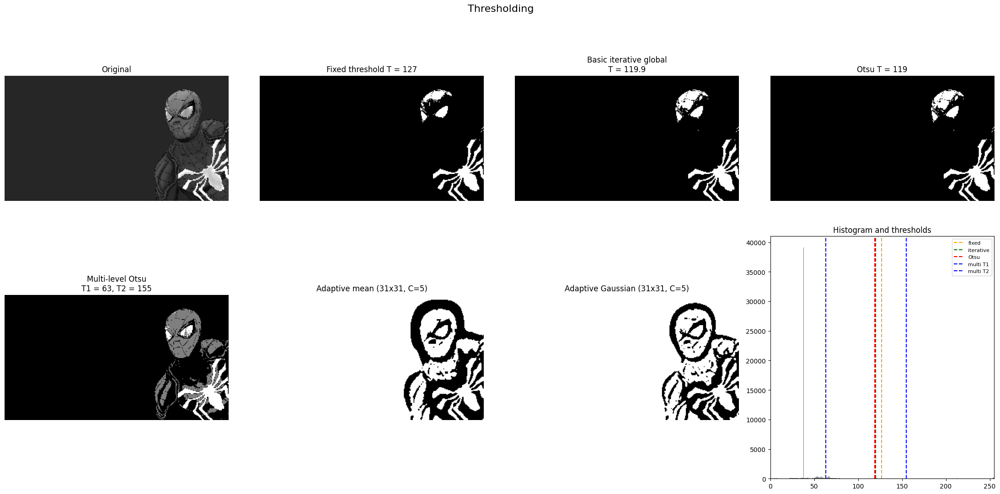

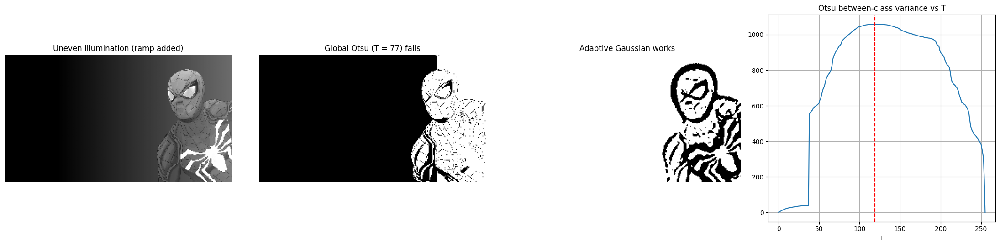


Seed intensity at centre = 38
Region growing, single seed, T =  5: region area = 39276 px (77.9 %)
Region growing, single seed, T = 15: region area = 42707 px (84.7 %)
Region growing, single seed, T = 30: region area = 44736 px (88.8 %)

Split-and-merge: 181 blocks -> 84 regions


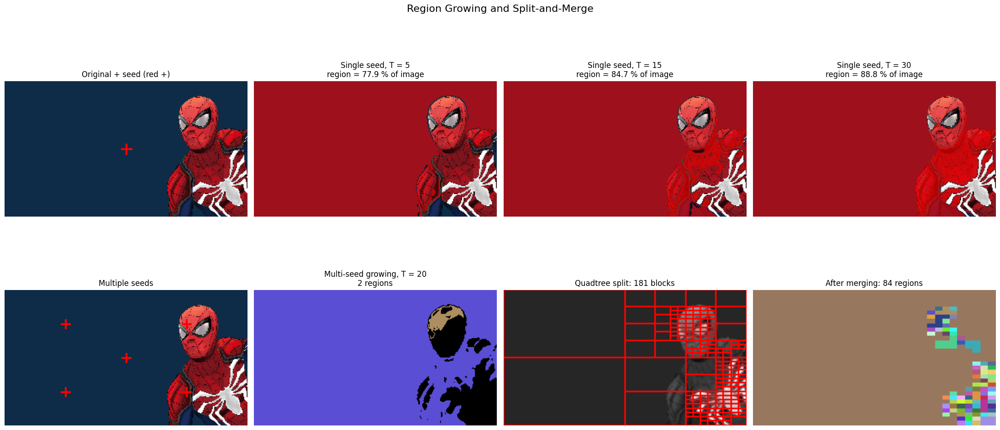


Marker-controlled watershed: 5 objects found
  object 1: area = 556 px
  object 2: area = 1 px
  object 3: area = 173 px
  object 4: area = 687 px
Watershed from all gradient minima (no marker control): 629 regions (over-segmentation)


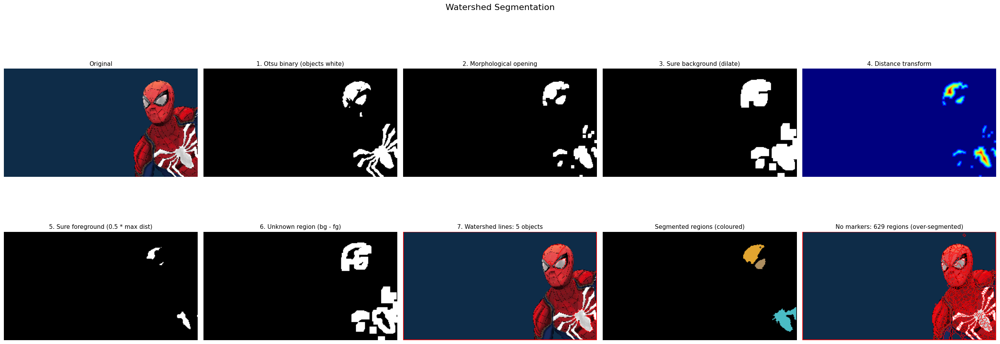

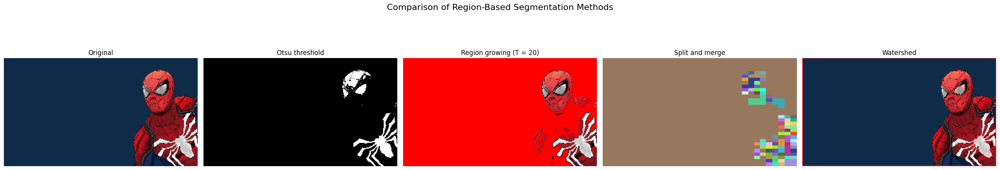

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

bgr = cv2.imread(img_path)
h0, w0 = bgr.shape[:2]
s = min(1.0, 300 / max(h0, w0))                 # keep it small so region growing is fast
bgr = cv2.resize(bgr, (int(w0 * s), int(h0 * s)))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
smooth = cv2.GaussianBlur(gray, (5, 5), 1.0)
H, W = gray.shape
print("Image size:", gray.shape)

hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)

def colorize(lab):
    rng = np.random.default_rng(3)
    pal = rng.integers(40, 255, (int(lab.max()) + 2, 3)).astype(np.uint8)
    pal[0] = 0
    return pal[np.clip(lab, 0, None)]

# =====================================================================
# PART A: THRESHOLDING
# =====================================================================
# A1. Basic iterative global threshold
def basic_global(img, eps=0.5, max_iter=100):
    T = img.mean()
    for it in range(1, max_iter + 1):
        lo, hi = img[img <= T], img[img > T]
        if len(lo) == 0 or len(hi) == 0:
            break
        Tn = 0.5 * (lo.mean() + hi.mean())
        if abs(Tn - T) < eps:
            return Tn, it
        T = Tn
    return T, it

# A2. Otsu: maximise the between-class variance
def otsu_manual(hist):
    p = hist / hist.sum()
    i = np.arange(256)
    w0 = np.cumsum(p)
    mu = np.cumsum(p * i)
    mut = mu[-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        sb = (mut * w0 - mu) ** 2 / (w0 * (1 - w0))
    sb = np.nan_to_num(sb)
    return int(np.argmax(sb)), sb

# A3. Multi-level Otsu (two thresholds -> three classes), brute force on the histogram
def multi_otsu_2(hist):
    p = hist / hist.sum()
    i = np.arange(256)
    P = np.concatenate([[0], np.cumsum(p)])
    S = np.concatenate([[0], np.cumsum(p * i)])
    best, bt = -1, (85, 170)
    for t1 in range(1, 255):
        w0, m0 = P[t1], S[t1]
        if w0 < 1e-9:
            continue
        for t2 in range(t1 + 1, 256):
            w1, w2 = P[t2] - w0, 1 - P[t2]
            if w1 < 1e-9 or w2 < 1e-9:
                continue
            m1, m2 = S[t2] - m0, S[256] - S[t2]
            sb = m0 * m0 / w0 + m1 * m1 / w1 + m2 * m2 / w2
            if sb > best:
                best, bt = sb, (t1, t2)
    return bt

T_fixed = 127
T_iter, n_iter = basic_global(gray.astype(np.float32))
T_otsu, sb_curve = otsu_manual(hist)
T_cv, bin_otsu_cv = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
t1, t2 = multi_otsu_2(hist)
print(f"\nFixed T = {T_fixed}")
print(f"Basic iterative global T = {T_iter:.2f}  ({n_iter} iterations)")
print(f"Otsu T (manual) = {T_otsu} | Otsu T (OpenCV) = {T_cv:.0f}")
print(f"Multi-level Otsu thresholds = {t1 - 1}, {t2 - 1}")

bin_fixed = ((gray > T_fixed) * 255).astype(np.uint8)
bin_iter = ((gray > T_iter) * 255).astype(np.uint8)
bin_otsu = ((gray > T_otsu) * 255).astype(np.uint8)
multi = (np.digitize(gray, [t1, t2]) * 127.5).astype(np.uint8)
ad_mean = cv2.adaptiveThreshold(smooth, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 31, 5)
ad_gauss = cv2.adaptiveThreshold(smooth, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 5)

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
items = [(gray, "Original"),
         (bin_fixed, f"Fixed threshold T = {T_fixed}"),
         (bin_iter, f"Basic iterative global\nT = {T_iter:.1f}"),
         (bin_otsu, f"Otsu T = {T_otsu}"),
         (multi, f"Multi-level Otsu\nT1 = {t1 - 1}, T2 = {t2 - 1}"),
         (ad_mean, "Adaptive mean (31x31, C=5)"),
         (ad_gauss, "Adaptive Gaussian (31x31, C=5)")]
for ax, (im, t) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
ax = axes.ravel()[7]
ax.bar(np.arange(256), hist, color="gray", width=1)
for T, c, l in [(T_fixed, "orange", "fixed"), (T_iter, "green", "iterative"),
                (T_otsu, "red", "Otsu"), (t1 - 1, "blue", "multi T1"), (t2 - 1, "blue", "multi T2")]:
    ax.axvline(T, color=c, ls="--", label=f"{l}")
ax.set_title("Histogram and thresholds"); ax.legend(fontsize=8); ax.set_xlim(0, 255)
plt.suptitle("Thresholding", fontsize=16)
plt.tight_layout()
plt.show()

# A4. Uneven illumination: global threshold fails, adaptive works
ramp = np.tile(np.linspace(-70, 70, W), (H, 1))
uneven = np.clip(gray.astype(np.float32) + ramp, 0, 255).astype(np.uint8)
uh = np.bincount(uneven.ravel(), minlength=256).astype(np.float64)
Tu, _ = otsu_manual(uh)
u_global = ((uneven > Tu) * 255).astype(np.uint8)
u_adapt = cv2.adaptiveThreshold(cv2.GaussianBlur(uneven, (5, 5), 1.0), 255,
                                cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 5)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (im, t) in zip(axes[:3], [(uneven, "Uneven illumination (ramp added)"),
                                  (u_global, f"Global Otsu (T = {Tu}) fails"),
                                  (u_adapt, "Adaptive Gaussian works")]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
axes[3].plot(sb_curve); axes[3].axvline(T_otsu, color="r", ls="--")
axes[3].set_title("Otsu between-class variance vs T"); axes[3].set_xlabel("T"); axes[3].grid(True)
plt.tight_layout()
plt.show()

# =====================================================================
# PART B: REGION GROWING (seeded) AND SPLIT-AND-MERGE
# =====================================================================
def region_grow(img, seeds, T=15, conn=8):
    # A neighbour joins the region if |intensity - running region mean| <= T
    g = img.astype(np.float32)
    labels = np.zeros(img.shape, np.int32)
    nbrs = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    if conn == 8:
        nbrs += [(-1, -1), (-1, 1), (1, -1), (1, 1)]
    for k, (sy, sx) in enumerate(seeds, 1):
        if labels[sy, sx] != 0:
            continue
        q = deque([(sy, sx)])
        labels[sy, sx] = k
        ssum, cnt = float(g[sy, sx]), 1
        while q:
            y, x = q.popleft()
            for dy, dx in nbrs:
                ny, nx = y + dy, x + dx
                if 0 <= ny < H and 0 <= nx < W and labels[ny, nx] == 0:
                    if abs(g[ny, nx] - ssum / cnt) <= T:
                        labels[ny, nx] = k
                        ssum += g[ny, nx]; cnt += 1
                        q.append((ny, nx))
    return labels

# Seeds are (row, col). Change these to put seeds inside the objects you want.
seed_main = (H // 2, W // 2)
seeds_multi = [(H // 2, W // 2), (H // 4, W // 4), (3 * H // 4, 3 * W // 4), (H // 4, 3 * W // 4), (3 * H // 4, W // 4)]
print(f"\nSeed intensity at centre = {smooth[seed_main]}")

Ts = [5, 15, 30]
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
axes[0, 0].imshow(rgb); axes[0, 0].plot(seed_main[1], seed_main[0], "r+", ms=18, mew=3)
axes[0, 0].set_title("Original + seed (red +)")
for ax, T in zip(axes[0, 1:], Ts):
    lab = region_grow(smooth, [seed_main], T)
    ov = rgb.copy(); ov[lab > 0] = (0.4 * ov[lab > 0] + 0.6 * np.array([255, 0, 0])).astype(np.uint8)
    ax.imshow(ov); ax.set_title(f"Single seed, T = {T}\nregion = {100 * (lab > 0).mean():.1f} % of image")
    print(f"Region growing, single seed, T = {T:2d}: region area = {int((lab > 0).sum())} px ({100 * (lab > 0).mean():.1f} %)")

lab_multi = region_grow(smooth, seeds_multi, 20)
axes[1, 0].imshow(rgb)
for (sy, sx) in seeds_multi:
    axes[1, 0].plot(sx, sy, "r+", ms=16, mew=3)
axes[1, 0].set_title("Multiple seeds")
axes[1, 1].imshow(colorize(lab_multi)); axes[1, 1].set_title(f"Multi-seed growing, T = 20\n{len(np.unique(lab_multi)) - 1} regions")

# Split and merge (quadtree)
def split_merge(img, T=10, min_size=8):
    g = img.astype(np.float64)
    blocks = []
    def split(y, x, h, w):
        reg = g[y:y + h, x:x + w]
        if reg.std() <= T or min(h, w) <= min_size:
            blocks.append((y, x, h, w)); return
        h2, w2 = h // 2, w // 2
        for (yy, xx, hh, ww) in [(y, x, h2, w2), (y, x + w2, h2, w - w2),
                                 (y + h2, x, h - h2, w2), (y + h2, x + w2, h - h2, w - w2)]:
            if hh > 0 and ww > 0:
                split(yy, xx, hh, ww)
    split(0, 0, img.shape[0], img.shape[1])

    ids = np.zeros(img.shape, np.int32)
    n = len(blocks)
    cnt = np.zeros(n); sm = np.zeros(n); sq = np.zeros(n)
    for k, (y, x, h, w) in enumerate(blocks):
        ids[y:y + h, x:x + w] = k
        r = g[y:y + h, x:x + w]
        cnt[k], sm[k], sq[k] = r.size, r.sum(), (r ** 2).sum()
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    pairs = set()
    for a, b in [(ids[:, :-1], ids[:, 1:]), (ids[:-1, :], ids[1:, :])]:
        m = a != b
        pairs |= set(zip(a[m].tolist(), b[m].tolist()))
    for i, j in pairs:                                  # merge adjacent blocks if the union is still uniform
        ri, rj = find(i), find(j)
        if ri == rj:
            continue
        c, ssum, ssq = cnt[ri] + cnt[rj], sm[ri] + sm[rj], sq[ri] + sq[rj]
        if np.sqrt(max(ssq / c - (ssum / c) ** 2, 0)) <= T:
            parent[rj] = ri
            cnt[ri], sm[ri], sq[ri] = c, ssum, ssq
    roots = np.array([find(k) for k in range(n)])
    uniq = {r: i + 1 for i, r in enumerate(np.unique(roots))}
    lut = np.array([uniq[r] for r in roots])
    return lut[ids], blocks

sm_lab, blocks = split_merge(smooth, T=12, min_size=8)
split_vis = cv2.cvtColor(smooth, cv2.COLOR_GRAY2RGB)
for (y, x, h, w) in blocks:
    cv2.rectangle(split_vis, (x, y), (x + w - 1, y + h - 1), (255, 0, 0), 1)
axes[1, 2].imshow(split_vis); axes[1, 2].set_title(f"Quadtree split: {len(blocks)} blocks")
axes[1, 3].imshow(colorize(sm_lab)); axes[1, 3].set_title(f"After merging: {len(np.unique(sm_lab))} regions")
print(f"\nSplit-and-merge: {len(blocks)} blocks -> {len(np.unique(sm_lab))} regions")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Region Growing and Split-and-Merge", fontsize=16)
plt.tight_layout()
plt.show()

# =====================================================================
# PART C: WATERSHED
# =====================================================================
# C1. Marker-controlled watershed
_, bw = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
border = np.concatenate([bw[0], bw[-1], bw[:, 0], bw[:, -1]])
if border.mean() > 127:                                   # make objects white, background black
    bw = 255 - bw
k3 = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(bw, cv2.MORPH_OPEN, k3, iterations=2)       # remove small noise
sure_bg = cv2.dilate(opening, k3, iterations=3)                         # certainly background
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist, 0.5 * dist.max(), 255, 0)              # cores of the objects
sure_fg = sure_fg.astype(np.uint8)
unknown = cv2.subtract(sure_bg, sure_fg)                                # region watershed must decide

n_cc, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1                                     # background = 1, objects = 2, 3, ...
markers[unknown == 255] = 0                               # 0 = unknown
markers_ws = cv2.watershed(bgr.copy(), markers.astype(np.int32))
n_obj = n_cc - 1
print(f"\nMarker-controlled watershed: {n_obj} objects found")

ws_overlay = rgb.copy()
ws_overlay[markers_ws == -1] = (255, 0, 0)                # watershed lines in red
ws_color = colorize(np.where(markers_ws > 1, markers_ws, 0))

for lab_id in range(2, markers_ws.max() + 1):
    area = int((markers_ws == lab_id).sum())
    if lab_id < 2 + 8:
        print(f"  object {lab_id - 1}: area = {area} px")

# C2. Over-segmentation: markers = every regional minimum of the gradient
grad = cv2.morphologyEx(smooth, cv2.MORPH_GRADIENT, k3)
minima = (grad == cv2.erode(grad, k3)).astype(np.uint8)
n_min, mk2 = cv2.connectedComponents(minima)
over = cv2.watershed(bgr.copy(), mk2.astype(np.int32))
over_overlay = rgb.copy(); over_overlay[over == -1] = (255, 0, 0)
print(f"Watershed from all gradient minima (no marker control): {n_min - 1} regions (over-segmentation)")

fig, axes = plt.subplots(2, 5, figsize=(26, 10.5))
items = [(rgb, "Original", None),
         (bw, "1. Otsu binary (objects white)", "gray"),
         (opening, "2. Morphological opening", "gray"),
         (sure_bg, "3. Sure background (dilate)", "gray"),
         (dist, "4. Distance transform", "jet"),
         (sure_fg, "5. Sure foreground (0.5 * max dist)", "gray"),
         (unknown, "6. Unknown region (bg - fg)", "gray"),
         (ws_overlay, f"7. Watershed lines: {n_obj} objects", None),
         (ws_color, "Segmented regions (coloured)", None),
         (over_overlay, f"No markers: {n_min - 1} regions (over-segmented)", None)]
for ax, (im, t, cm) in zip(axes.ravel(), items):
    ax.imshow(im, cmap=cm); ax.set_title(t, fontsize=11); ax.axis("off")
plt.suptitle("Watershed Segmentation", fontsize=16)
plt.tight_layout()
plt.show()

# =====================================================================
# SUMMARY: all methods side by side
# =====================================================================
lab_vis = rgb.copy(); lab_vis[region_grow(smooth, [seed_main], 20) > 0] = (255, 0, 0)
fig, axes = plt.subplots(1, 5, figsize=(26, 5.5))
for ax, (im, t) in zip(axes, [(rgb, "Original"),
                              (bin_otsu, "Otsu threshold"),
                              (lab_vis, "Region growing (T = 20)"),
                              (colorize(sm_lab), "Split and merge"),
                              (ws_overlay, "Watershed")]):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None); ax.set_title(t); ax.axis("off")
plt.suptitle("Comparison of Region-Based Segmentation Methods", fontsize=16)
plt.tight_layout()
plt.show()

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (15).jpg
Image size: (225, 400)
Object area in binary image A: 4566 pixels

Manual dilation == OpenCV dilation: True
Manual erosion  == OpenCV erosion : True

SE (3x3 cross):
 [[0 1 0]
 [1 1 1]
 [0 1 0]]

A:
 [[1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 1 1 1 1 1 0 0]
 [0 0 1 1 1 1 1 0 0]
 [0 0 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 0 0]
 [0 0 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

A eroded by cross:
 [[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 1 1 1 0 0 0]
 [0 0 0 1 1 1 1 0 0]
 [0 0 0 1 1 1 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

A dilated by cross:
 [[1 1 0 0 0 0 0 0 0]
 [1 0 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]

Opening (erosion then dilation):
 [[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 1 1 1 0 0

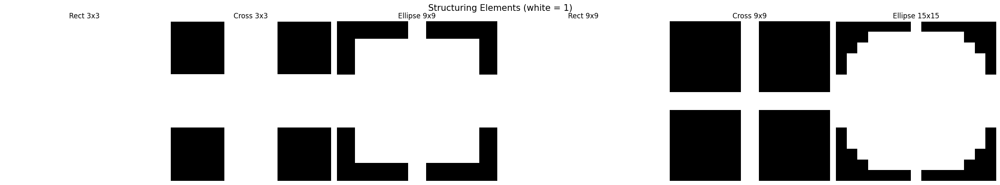

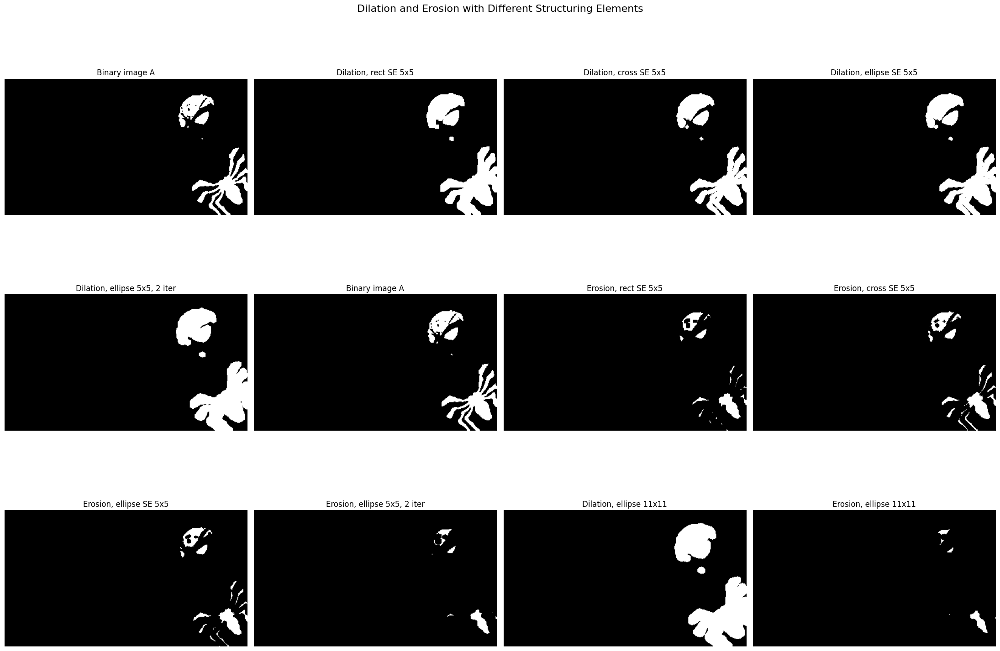


Object area (pixels) versus SE size, ellipse SE:
 SE size |  Dilation |   Erosion
       3 |      5655 |      3459
       5 |      6956 |      2093
       9 |      8701 |       859
      15 |     10822 |       240
      21 |     12594 |        21
Original area = 4566

Opening is idempotent  (open(open(A)) == open(A))  : True
Closing is idempotent  (close(close(A)) == close(A)): True
Opening is anti-extensive (open(A) is inside A)     : True
Closing is extensive      (A is inside close(A))    : True
Duality: open(A) == complement of close(complement of A): True
Areas -> A: 4566, opened: 3429, closed: 5343

Pixels that differ from the clean A (lower is better):
  Noisy                 : 950
  Opening 3x3           : 215
  Closing 3x3           : 1230
  Opening then closing  : 271


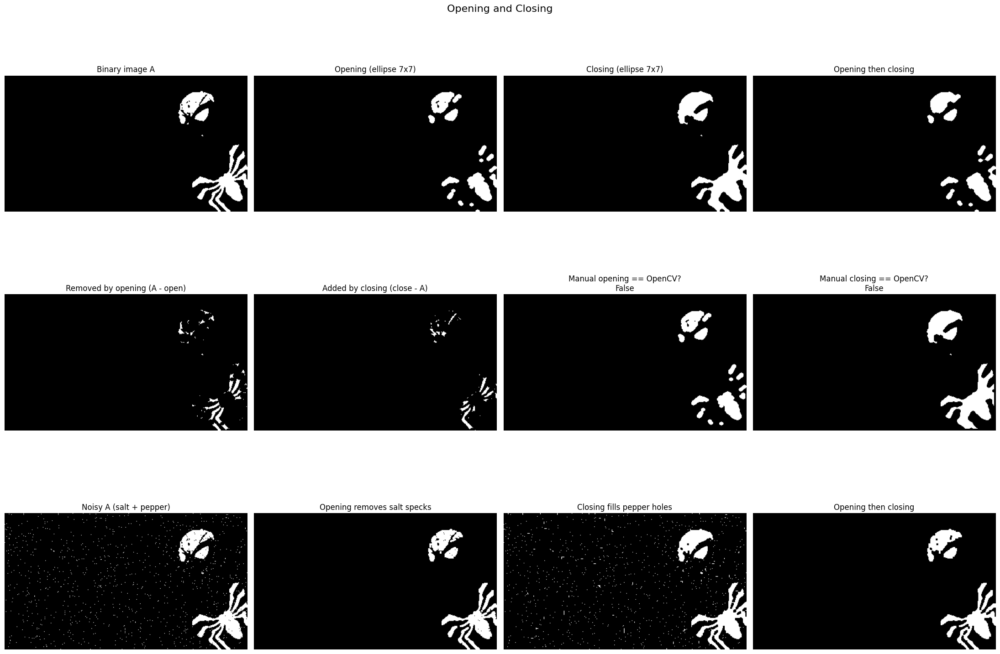


Boundary pixel counts:
  Internal boundary (3x3 rect)  : 1647
  Internal boundary (3x3 cross) : 1130
  External boundary (3x3 rect)  : 1575
  Morphological gradient        : 3222
  Gradient == OpenCV MORPH_GRADIENT: False
  Objects found (8-connected)   : 5
  findContours boundary length  : 1072 pixels


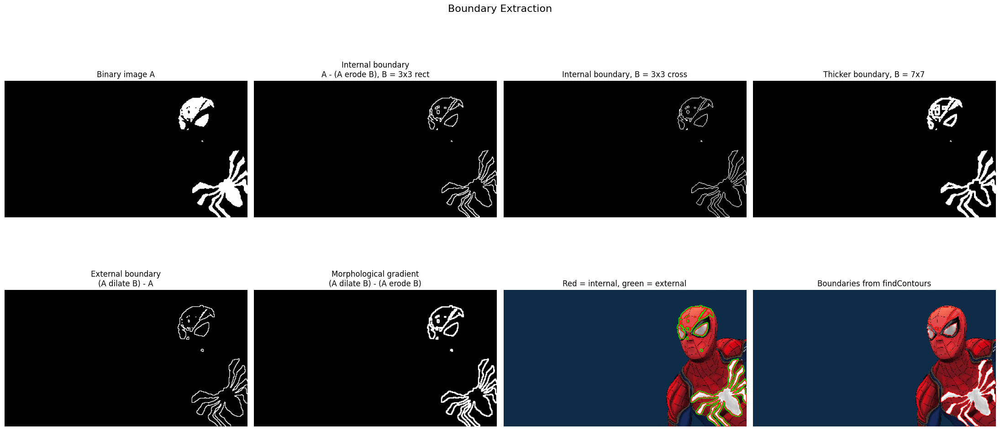


Grayscale: dilation raises mean from 47.9 to 66.5; erosion lowers it to 29.7


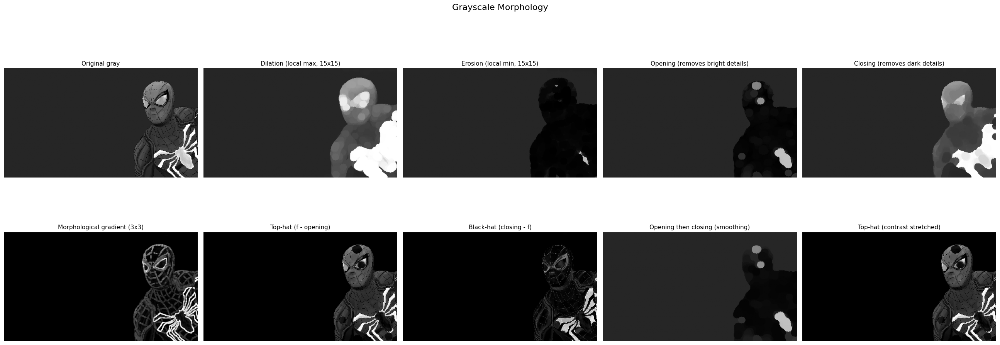

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

bgr = cv2.imread(img_path)
h0, w0 = bgr.shape[:2]
s = min(1.0, 400 / max(h0, w0))
bgr = cv2.resize(bgr, (int(w0 * s), int(h0 * s)))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
H, W = gray.shape
print("Image size:", gray.shape)

# Binary image A (objects = 255, background = 0)
_, A = cv2.threshold(cv2.GaussianBlur(gray, (5, 5), 1.0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
border = np.concatenate([A[0], A[-1], A[:, 0], A[:, -1]])
if border.mean() > 127:                      # make sure objects are white
    A = 255 - A
area = lambda im: int(np.count_nonzero(im))
print("Object area in binary image A:", area(A), "pixels")

# =====================================================================
# PART A: STRUCTURING ELEMENTS + MANUAL DILATION / EROSION
# =====================================================================
def se(shape, k):
    kind = {"rect": cv2.MORPH_RECT, "cross": cv2.MORPH_CROSS, "ellipse": cv2.MORPH_ELLIPSE}[shape]
    return cv2.getStructuringElement(kind, (k, k))

def shift(M, dy, dx):
    # translate M by (dy, dx), filling with zeros (no wrap-around)
    out = np.zeros_like(M)
    h, w = M.shape
    ys, ye = max(0, dy), min(h, h + dy)
    xs, xe = max(0, dx), min(w, w + dx)
    out[ys:ye, xs:xe] = M[ys - dy:ye - dy, xs - dx:xe - dx]
    return out

def offsets(B):
    cy, cx = B.shape[0] // 2, B.shape[1] // 2
    return [(i - cy, j - cx) for i in range(B.shape[0]) for j in range(B.shape[1]) if B[i, j]]

def dilate_manual(M, B):
    # A (+) B = union of A translated by every element b of B  (B is symmetric here)
    out = np.zeros_like(M)
    for dy, dx in offsets(B):
        out |= shift(M, dy, dx)
    return out

def erode_manual(M, B):
    # A (-) B = intersection of A translated by -b : B must fit completely inside A
    out = np.ones_like(M) * 255
    for dy, dx in offsets(B):
        out &= shift(M, -dy, -dx)
    return out

B3 = se("rect", 3)
d_man, e_man = dilate_manual(A, B3), erode_manual(A, B3)
d_cv = cv2.dilate(A, B3)
e_cv = cv2.erode(A, B3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
print("\nManual dilation == OpenCV dilation:", np.array_equal(d_man, d_cv))
print("Manual erosion  == OpenCV erosion :", np.array_equal(e_man, e_cv))

# Small hand-checkable example (1 = object)
tiny = np.zeros((9, 9), np.uint8)
tiny[2:7, 2:7] = 1
tiny[4, 7] = 1                                     # a one-pixel spur
tiny[0, 0] = 1                                     # an isolated noise pixel
cross = se("cross", 3)
print("\nSE (3x3 cross):\n", cross)
print("\nA:\n", tiny)
print("\nA eroded by cross:\n", erode_manual(tiny * 255, cross) // 255)
print("\nA dilated by cross:\n", dilate_manual(tiny * 255, cross) // 255)
print("\nOpening (erosion then dilation):\n",
      dilate_manual(erode_manual(tiny * 255, cross), cross) // 255)

fig, axes = plt.subplots(1, 6, figsize=(24, 4.5))
ses = [("Rect 3x3", se("rect", 3)), ("Cross 3x3", se("cross", 3)), ("Ellipse 9x9", se("ellipse", 9)),
       ("Rect 9x9", se("rect", 9)), ("Cross 9x9", se("cross", 9)), ("Ellipse 15x15", se("ellipse", 15))]
for ax, (t, b) in zip(axes, ses):
    ax.imshow(b, cmap="gray", vmin=0, vmax=1); ax.set_title(t); ax.axis("off")
plt.suptitle("Structuring Elements (white = 1)", fontsize=15)
plt.tight_layout(); plt.show()

# =====================================================================
# PART B: DILATION AND EROSION
# =====================================================================
fig, axes = plt.subplots(3, 4, figsize=(22, 16))
items = [("Binary image A", A)]
items += [(f"Dilation, {n} 5x5", cv2.dilate(A, se(n.split()[0], 5))) for n in ["rect SE", "cross SE", "ellipse SE"]]
items += [(f"Dilation, ellipse 5x5, {it} iter", cv2.dilate(A, se("ellipse", 5), iterations=it)) for it in [2]]
items += [("Binary image A", A)]
items += [(f"Erosion, {n} 5x5", cv2.erode(A, se(n.split()[0], 5))) for n in ["rect SE", "cross SE", "ellipse SE"]]
items += [(f"Erosion, ellipse 5x5, {it} iter", cv2.erode(A, se("ellipse", 5), iterations=it)) for it in [2]]
items += [("Dilation, ellipse 11x11", cv2.dilate(A, se("ellipse", 11))),
          ("Erosion, ellipse 11x11", cv2.erode(A, se("ellipse", 11))),
          ("Dilation of A (11x11) minus A", cv2.dilate(A, se("ellipse", 11)) - A),
          ("A minus Erosion of A (11x11)", A - cv2.erode(A, se("ellipse", 11)))]
for ax, (t, im) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.suptitle("Dilation and Erosion with Different Structuring Elements", fontsize=16)
plt.tight_layout(); plt.show()

print("\nObject area (pixels) versus SE size, ellipse SE:")
print(f"{'SE size':>8s} | {'Dilation':>9s} | {'Erosion':>9s}")
for k in [3, 5, 9, 15, 21]:
    print(f"{k:8d} | {area(cv2.dilate(A, se('ellipse', k))):9d} | {area(cv2.erode(A, se('ellipse', k))):9d}")
print(f"Original area = {area(A)}")

# =====================================================================
# PART C: OPENING AND CLOSING
# =====================================================================
Bo = se("ellipse", 7)
opened = cv2.morphologyEx(A, cv2.MORPH_OPEN, Bo)       # erosion followed by dilation
closed = cv2.morphologyEx(A, cv2.MORPH_CLOSE, Bo)      # dilation followed by erosion
open_manual = dilate_manual(erode_manual(A, Bo), Bo)
close_manual = erode_manual(dilate_manual(A, Bo), Bo)

# Properties
print("\nOpening is idempotent  (open(open(A)) == open(A))  :",
      np.array_equal(cv2.morphologyEx(opened, cv2.MORPH_OPEN, Bo), opened))
print("Closing is idempotent  (close(close(A)) == close(A)):",
      np.array_equal(cv2.morphologyEx(closed, cv2.MORPH_CLOSE, Bo), closed))
print("Opening is anti-extensive (open(A) is inside A)     :", bool(np.all(opened <= A)))
print("Closing is extensive      (A is inside close(A))    :", bool(np.all(A <= closed)))
comp = 255 - A
dual = 255 - cv2.morphologyEx(comp, cv2.MORPH_CLOSE, Bo)
print("Duality: open(A) == complement of close(complement of A):", np.array_equal(dual, opened))
print(f"Areas -> A: {area(A)}, opened: {area(opened)}, closed: {area(closed)}")

# Noise-removal demo: add salt (white specks in background) and pepper (black holes in objects)
rng = np.random.default_rng(5)
noisy = A.copy()
r = rng.random(A.shape)
noisy[(r < 0.01) & (A == 0)] = 255           # salt specks
noisy[(r > 0.99) & (A == 255)] = 0           # pepper holes
B3c = se("rect", 3)
n_open = cv2.morphologyEx(noisy, cv2.MORPH_OPEN, B3c)
n_close = cv2.morphologyEx(noisy, cv2.MORPH_CLOSE, B3c)
n_oc = cv2.morphologyEx(n_open, cv2.MORPH_CLOSE, B3c)     # opening then closing = full cleaning
err = lambda im: int(np.count_nonzero(im != A))
print("\nPixels that differ from the clean A (lower is better):")
for name, im in [("Noisy", noisy), ("Opening 3x3", n_open), ("Closing 3x3", n_close), ("Opening then closing", n_oc)]:
    print(f"  {name:22s}: {err(im)}")

# Size-selective opening: removes objects smaller than the SE
fig, axes = plt.subplots(3, 4, figsize=(22, 16))
items = [("Binary image A", A),
         ("Opening (ellipse 7x7)", opened),
         ("Closing (ellipse 7x7)", closed),
         ("Opening then closing", cv2.morphologyEx(opened, cv2.MORPH_CLOSE, Bo)),
         ("Removed by opening (A - open)", A - opened),
         ("Added by closing (close - A)", closed - A),
         ("Manual opening == OpenCV?\n" + str(np.array_equal(open_manual, opened)), open_manual),
         ("Manual closing == OpenCV?\n" + str(np.array_equal(close_manual, closed)), close_manual),
         ("Noisy A (salt + pepper)", noisy),
         ("Opening removes salt specks", n_open),
         ("Closing fills pepper holes", n_close),
         ("Opening then closing", n_oc)]
for ax, (t, im) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.suptitle("Opening and Closing", fontsize=16)
plt.tight_layout(); plt.show()

# =====================================================================
# PART D: BOUNDARY EXTRACTION
#   internal: beta(A) = A - (A erode B)
#   external: (A dilate B) - A
#   gradient: (A dilate B) - (A erode B)
# =====================================================================
Bb = se("rect", 3)                                  # 3x3 of ones gives a 1-pixel thick, 8-connected boundary
Bb4 = se("cross", 3)                                # cross gives a boundary that is 8-connected / thinner on diagonals
internal = cv2.subtract(A, cv2.erode(A, Bb, borderType=cv2.BORDER_CONSTANT, borderValue=0))
external = cv2.subtract(cv2.dilate(A, Bb), A)
mgrad = cv2.subtract(cv2.dilate(A, Bb), cv2.erode(A, Bb, borderType=cv2.BORDER_CONSTANT, borderValue=0))
internal4 = cv2.subtract(A, cv2.erode(A, Bb4, borderType=cv2.BORDER_CONSTANT, borderValue=0))
internal_thick = cv2.subtract(A, cv2.erode(A, se("rect", 7), borderType=cv2.BORDER_CONSTANT, borderValue=0))
cv_grad = cv2.morphologyEx(A, cv2.MORPH_GRADIENT, Bb)

print("\nBoundary pixel counts:")
print(f"  Internal boundary (3x3 rect)  : {area(internal)}")
print(f"  Internal boundary (3x3 cross) : {area(internal4)}")
print(f"  External boundary (3x3 rect)  : {area(external)}")
print(f"  Morphological gradient        : {area(mgrad)}")
print(f"  Gradient == OpenCV MORPH_GRADIENT: {np.array_equal(mgrad, cv_grad)}")
n_obj = cv2.connectedComponents(A, connectivity=8)[0] - 1
print(f"  Objects found (8-connected)   : {n_obj}")

contours, _ = cv2.findContours(A, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
perim_img = rgb.copy()
cv2.drawContours(perim_img, contours, -1, (255, 0, 0), 1)
print(f"  findContours boundary length  : {sum(len(c) for c in contours)} pixels")

overlay = rgb.copy()
overlay[internal > 0] = (255, 0, 0)
overlay[external > 0] = (0, 255, 0)

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
items = [(A, "Binary image A"),
         (internal, "Internal boundary\nA - (A erode B), B = 3x3 rect"),
         (internal4, "Internal boundary, B = 3x3 cross"),
         (internal_thick, "Thicker boundary, B = 7x7"),
         (external, "External boundary\n(A dilate B) - A"),
         (mgrad, "Morphological gradient\n(A dilate B) - (A erode B)"),
         (overlay, "Red = internal, green = external"),
         (perim_img, "Boundaries from findContours")]
for ax, (im, t) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.suptitle("Boundary Extraction", fontsize=16)
plt.tight_layout(); plt.show()

# =====================================================================
# PART E (BONUS): GRAYSCALE MORPHOLOGY
#   dilation = local max, erosion = local min
# =====================================================================
Bg = se("ellipse", 15)
g_dil = cv2.dilate(gray, Bg)
g_ero = cv2.erode(gray, Bg)
g_open = cv2.morphologyEx(gray, cv2.MORPH_OPEN, Bg)
g_close = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, Bg)
g_grad = cv2.morphologyEx(gray, cv2.MORPH_GRADIENT, se("rect", 3))
tophat = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, Bg)         # f - open(f): bright small objects
blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, Bg)     # close(f) - f: dark small objects
smoothing = cv2.morphologyEx(g_open, cv2.MORPH_CLOSE, Bg)     # opening-closing smoothing
print("\nGrayscale: dilation raises mean from",
      f"{gray.mean():.1f} to {g_dil.mean():.1f}; erosion lowers it to {g_ero.mean():.1f}")

fig, axes = plt.subplots(2, 5, figsize=(26, 10.5))
items = [(gray, "Original gray"), (g_dil, "Dilation (local max, 15x15)"), (g_ero, "Erosion (local min, 15x15)"),
         (g_open, "Opening (removes bright details)"), (g_close, "Closing (removes dark details)"),
         (g_grad, "Morphological gradient (3x3)"), (tophat, "Top-hat (f - opening)"),
         (blackhat, "Black-hat (closing - f)"), (smoothing, "Opening then closing (smoothing)"),
         (cv2.normalize(tophat, None, 0, 255, cv2.NORM_MINMAX), "Top-hat (contrast stretched)")]
for ax, (im, t) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t, fontsize=11); ax.axis("off")
plt.suptitle("Grayscale Morphology", fontsize=16)
plt.tight_layout(); plt.show()

A1. HUFFMAN: textbook source with 6 symbols
Symbol        p   Code     Length
a1         0.40   0             1
a2         0.30   10            2
a3         0.10   1110          4
a4         0.10   1111          4
a5         0.06   1101          4
a6         0.04   1100          4
Entropy H = 2.1435 bits/symbol | Average length L = 2.2000 bits/symbol
Efficiency = H / L = 97.43 % | Fixed 3-bit code would need 3.0 bits/symbol

A2. ARITHMETIC CODING with exact fractions: message 'eaii!'
Initial sub-intervals: a:[0.0,0.2), e:[0.2,0.5), i:[0.5,0.6), o:[0.6,0.8), u:[0.8,0.9), !:[0.9,1.0)
  after 'e': [0.2000000, 0.5000000)   width = 0.3000000
  after 'a': [0.2000000, 0.2600000)   width = 0.0600000
  after 'i': [0.2300000, 0.2360000)   width = 0.0060000
  after 'i': [0.2330000, 0.2336000)   width = 0.0006000
  after '!': [0.2335400, 0.2336000)   width = 0.0000600
Shortest code: 00111011110011  (14 bits for 5 symbols = 2.80 bits/symbol)
Ideal information content = 14.02 bits

A3. RUN-LENGTH CO

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (16).jpg
Image size: (256, 256) | raw size = 65536 bytes
Entropy of the image            : 2.353 bits/pixel -> best possible ratio 3.40:1
Entropy of the residual image   : 1.976 bits/pixel -> best possible ratio 4.05:1
(Neighbouring pixels are correlated, so the residual has a more peaked histogram and lower entropy.)


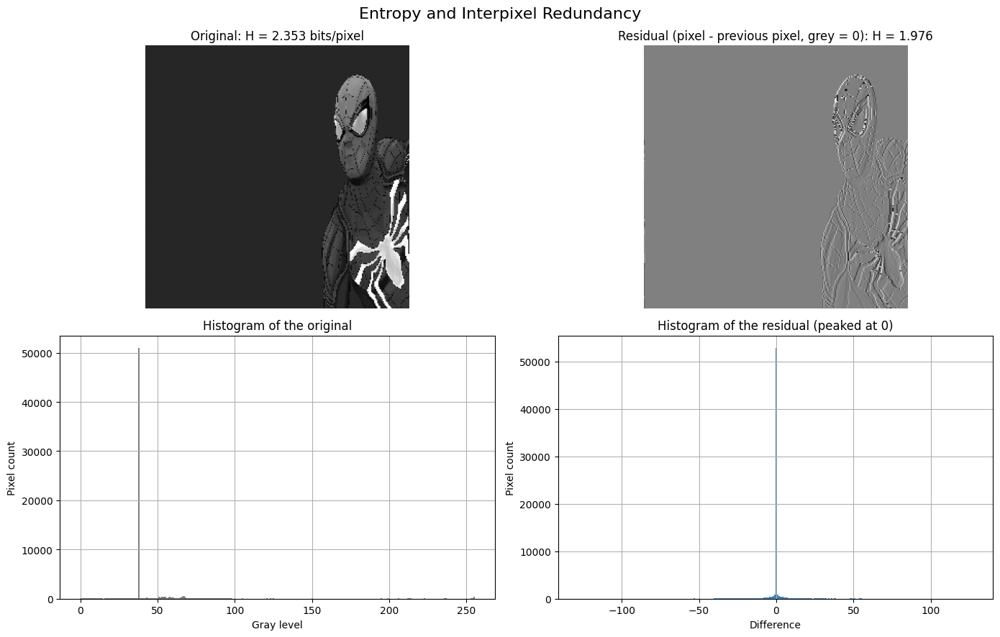


C. HUFFMAN CODING

Original:
  Distinct symbols    : 256
  Code lengths        : min 1, max 14 bits
  Average length L    : 2.595 bits/pixel   (entropy H = 2.353, so H <= L < H + 1: True)
  Coding efficiency   : 90.69 %
  Compressed size     : 21255 bytes  | ratio = 3.083:1
  With table (~512 B)  : ratio = 3.011:1
  Decoded == original : True
  Most frequent symbols  : 38->1, 67->010111, 58->001110, 53->001101, 54->001001
  Least frequent symbols : 181->01101110110101, 243->0001010101100, 187->01001010111100

Residual:
  Distinct symbols    : 255
  Code lengths        : min 1, max 14 bits
  Average length L    : 2.271 bits/pixel   (entropy H = 1.976, so H <= L < H + 1: True)
  Coding efficiency   : 86.99 %
  Compressed size     : 18606 bytes  | ratio = 3.522:1
  With table (~510 B)  : ratio = 3.428:1
  Decoded == original : True
  Most frequent symbols  : 0->1, 1->01010, 255->01001, 254->00001, 2->00000
  Least frequent symbols : 118->01111011010011, 160->0010000001110, 127->011000100

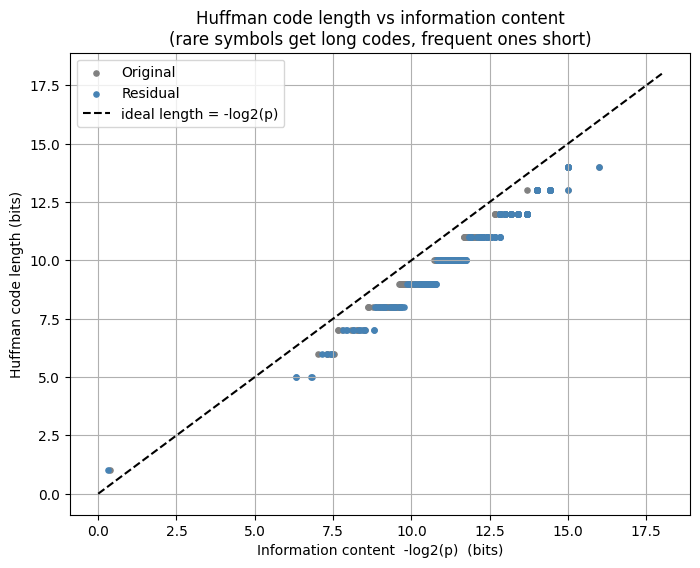


D. ARITHMETIC CODING

Original:
  Output length       : 154211 bits = 2.3531 bits/pixel (entropy H = 2.3531)
  Overhead vs entropy : +1.2 bits in total
  Compressed size     : 19276 bytes | ratio = 3.400:1
  Decoded == original : True

Residual:
  Output length       : 129489 bits = 1.9758 bits/pixel (entropy H = 1.9758)
  Overhead vs entropy : +0.7 bits in total
  Compressed size     : 16186 bytes | ratio = 4.049:1
  Decoded == original : True

Binary (Otsu):
  Output length       : 17158 bits = 0.2618 bits/pixel (entropy H = 0.2618)
  Overhead vs entropy : +1.3 bits in total
  Compressed size     : 2144 bytes | ratio = 3.820:1  (relative to 1 bit/pixel)
  Decoded == original : True

E. RUN-LENGTH CODING

Gray Original: 12733 runs for 65536 pixels (average run = 5.15) | size = 25516 bytes | ratio = 2.568:1  | decode ok: True

Gray Residual: 14130 runs for 65536 pixels (average run = 4.64) | size = 28308 bytes | ratio = 2.315:1  | decode ok: True

Binary (Otsu) image: 1109 runs | size

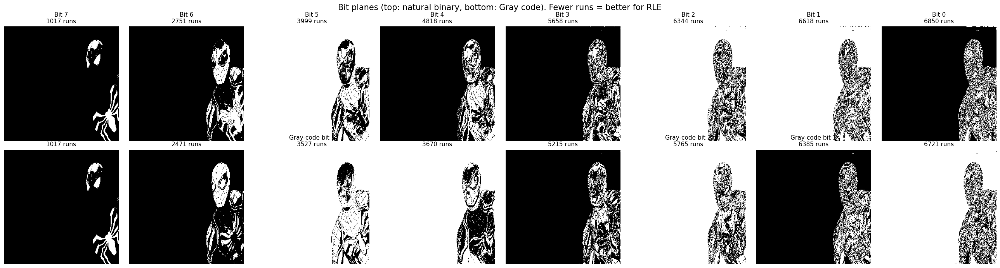

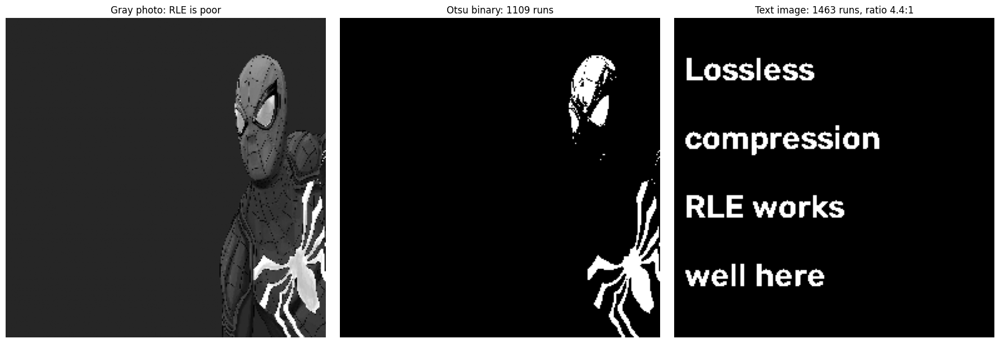


F. SUMMARY (payload only, 8-bit gray image, raw = 8.000 bits/pixel)
Method                          Bits/pixel     Ratio    Saving
Entropy bound, original              2.353     3.40:1     70.6%
Huffman, original                    2.595     3.08:1     67.6%
Arithmetic, original                 2.353     3.40:1     70.6%
RLE (gray), original                 3.115     2.57:1     61.1%
RLE bit-planes (natural)             5.262     1.52:1     34.2%
RLE bit-planes (Gray code)           4.811     1.66:1     39.9%
Entropy bound, residual              1.976     4.05:1     75.3%
Huffman, residual                    2.271     3.52:1     71.6%
Arithmetic, residual                 1.976     4.05:1     75.3%
RLE (gray), residual                 3.456     2.32:1     56.8%


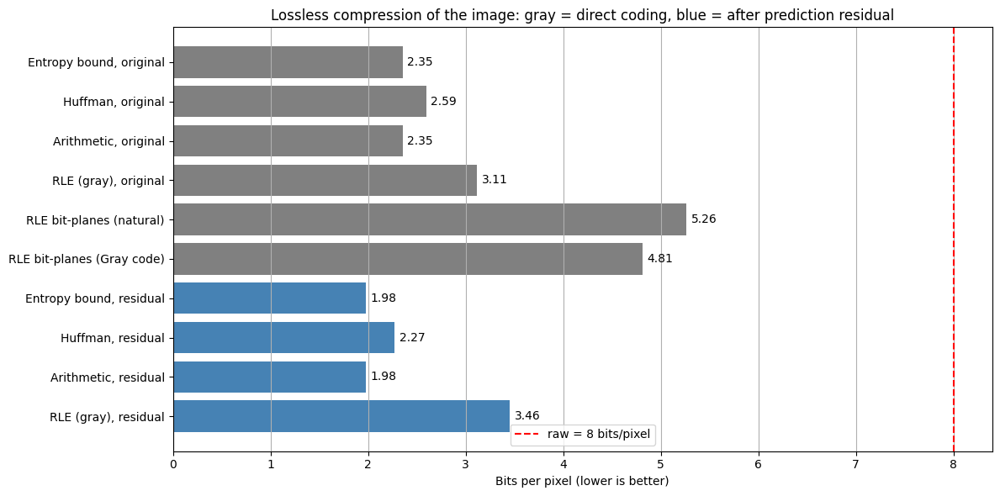

In [19]:
import cv2
import heapq
import itertools
import math
import numpy as np
import matplotlib.pyplot as plt
from bisect import bisect_right
from collections import Counter
from fractions import Fraction
from google.colab import files

# =====================================================================
# PART A: SMALL HAND-CHECKABLE EXAMPLES
# =====================================================================
def huffman_codes(freq):
    # freq: dict symbol -> count. Returns dict symbol -> bit string.
    counter = itertools.count()                       # tie-breaker so nodes are never compared
    heap = [(w, next(counter), s) for s, w in freq.items()]
    heapq.heapify(heap)
    if len(heap) == 1:
        return {heap[0][2]: "0"}
    while len(heap) > 1:                              # merge the two least probable nodes
        w1, _, n1 = heapq.heappop(heap)
        w2, _, n2 = heapq.heappop(heap)
        heapq.heappush(heap, (w1 + w2, next(counter), (n1, n2)))
    codes, stack = {}, [(heap[0][2], "")]
    while stack:
        node, code = stack.pop()
        if isinstance(node, tuple):
            stack.append((node[0], code + "0"))
            stack.append((node[1], code + "1"))
        else:
            codes[node] = code
    return codes

print("=" * 70)
print("A1. HUFFMAN: textbook source with 6 symbols")
print("=" * 70)
ex = {"a1": 40, "a2": 30, "a3": 10, "a4": 10, "a5": 6, "a6": 4}      # counts out of 100
ex_codes = huffman_codes(ex)
ex_H = -sum((c / 100) * math.log2(c / 100) for c in ex.values())
ex_L = sum((c / 100) * len(ex_codes[s]) for s, c in ex.items())
print(f"{'Symbol':8s}{'p':>7s}   {'Code':8s}{'Length':>7s}")
for s, c in sorted(ex.items(), key=lambda kv: -kv[1]):
    print(f"{s:8s}{c / 100:7.2f}   {ex_codes[s]:8s}{len(ex_codes[s]):7d}")
print(f"Entropy H = {ex_H:.4f} bits/symbol | Average length L = {ex_L:.4f} bits/symbol")
print(f"Efficiency = H / L = {100 * ex_H / ex_L:.2f} % | Fixed 3-bit code would need 3.0 bits/symbol")

print("\n" + "=" * 70)
print("A2. ARITHMETIC CODING with exact fractions: message 'eaii!'")
print("=" * 70)
sym_p = {"a": Fraction(2, 10), "e": Fraction(3, 10), "i": Fraction(1, 10),
         "o": Fraction(2, 10), "u": Fraction(1, 10), "!": Fraction(1, 10)}
cum_r, c = {}, Fraction(0)
for s, p in sym_p.items():
    cum_r[s] = (c, c + p)
    c += p
print("Initial sub-intervals: " + ", ".join(f"{s}:[{float(a):.1f},{float(b):.1f})" for s, (a, b) in cum_r.items()))
low, high = Fraction(0), Fraction(1)
for s in "eaii!":
    r = high - low
    high = low + r * cum_r[s][1]
    low = low + r * cum_r[s][0]
    print(f"  after '{s}': [{float(low):.7f}, {float(high):.7f})   width = {float(high - low):.7f}")
k = 1
while True:                                           # shortest binary fraction inside [low, high)
    m = math.ceil(low * 2 ** k)
    if Fraction(m, 2 ** k) < high:
        break
    k += 1
print(f"Shortest code: {format(m, f'0{k}b')}  ({k} bits for 5 symbols = {k / 5:.2f} bits/symbol)")
print(f"Ideal information content = {-math.log2(float(high - low)):.2f} bits")

print("\n" + "=" * 70)
print("A3. RUN-LENGTH CODING of a short string")
print("=" * 70)
def rle_encode(arr):
    arr = np.asarray(arr).ravel()
    change = np.flatnonzero(arr[1:] != arr[:-1]) + 1
    starts = np.concatenate(([0], change))
    ends = np.concatenate((change, [arr.size]))
    return [(int(arr[a]), int(b - a)) for a, b in zip(starts, ends)]

def rle_decode(runs, dtype=np.uint8):
    return np.repeat(np.array([v for v, _ in runs], dtype=dtype), [c for _, c in runs])

def rle_cost(runs, value_bits):
    # each run = value (value_bits) + count (8 bits); runs longer than 255 are split
    return sum(math.ceil(c / 255) for _, c in runs) * (value_bits + 8)

text = "WWWWBBBWWWWWWBB"
tr = rle_encode(np.frombuffer(text.encode(), np.uint8))
print("String :", text)
print("RLE    :", " ".join(f"({chr(v)},{n})" for v, n in tr))
print("Decoded:", "".join(chr(v) * n for v, n in tr))

# =====================================================================
# PART B: LOAD IMAGE AND COMPUTE ENTROPY
# =====================================================================
print("\n" + "=" * 70)
print("B. ENTROPY OF THE IMAGE")
print("=" * 70)
uploaded = files.upload()
img_path = list(uploaded.keys())[0]
gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))                   # 65,536 pixels: fast enough for pure-Python coders
flat = gray.ravel()
N = flat.size
raw_bits = N * 8
print("Image size:", gray.shape, "| raw size =", raw_bits // 8, "bytes")

def entropy(x):
    counts = np.bincount(np.asarray(x).ravel(), minlength=256)
    p = counts[counts > 0] / counts.sum()
    return float(-(p * np.log2(p)).sum())

# Interpixel redundancy: code the difference from the previous pixel instead of the pixel
res = np.empty_like(flat)
res[0] = flat[0]
res[1:] = ((flat[1:].astype(np.int16) - flat[:-1].astype(np.int16)) % 256).astype(np.uint8)
assert np.array_equal(np.cumsum(res.astype(np.int64)) % 256, flat)      # reversible, so still lossless
res_signed = ((res.astype(np.int16) + 128) % 256) - 128                  # for display only

H_img, H_res = entropy(flat), entropy(res)
print(f"Entropy of the image            : {H_img:.3f} bits/pixel -> best possible ratio {8 / H_img:.2f}:1")
print(f"Entropy of the residual image   : {H_res:.3f} bits/pixel -> best possible ratio {8 / H_res:.2f}:1")
print("(Neighbouring pixels are correlated, so the residual has a more peaked histogram and lower entropy.)")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title(f"Original: H = {H_img:.3f} bits/pixel"); axes[0, 0].axis("off")
axes[0, 1].imshow(res_signed.reshape(gray.shape) + 128, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title(f"Residual (pixel - previous pixel, grey = 0): H = {H_res:.3f}"); axes[0, 1].axis("off")
axes[1, 0].bar(np.arange(256), np.bincount(flat, minlength=256), width=1, color="gray")
axes[1, 0].set_title("Histogram of the original"); axes[1, 0].set_xlabel("Gray level")
axes[1, 1].bar(np.arange(-128, 128), np.bincount(res_signed + 128, minlength=256), width=1, color="steelblue")
axes[1, 1].set_title("Histogram of the residual (peaked at 0)"); axes[1, 1].set_xlabel("Difference")
for ax in axes[1]:
    ax.set_ylabel("Pixel count"); ax.grid(True)
plt.suptitle("Entropy and Interpixel Redundancy", fontsize=16)
plt.tight_layout(); plt.show()

# =====================================================================
# PART C: HUFFMAN CODING OF THE IMAGE
# =====================================================================
def huffman_encode(data):
    lst = data.tolist()
    freq = Counter(lst)
    codes = huffman_codes(freq)
    return freq, codes, "".join(codes[s] for s in lst)

def huffman_decode(bits, codes, n):
    inv = {v: k for k, v in codes.items()}
    out, cur = [], ""
    for b in bits:
        cur += b
        if cur in inv:
            out.append(inv[cur]); cur = ""
            if len(out) == n:
                break
    return np.array(out, dtype=np.uint8)

print("\n" + "=" * 70)
print("C. HUFFMAN CODING")
print("=" * 70)
huff = {}
for name, data in [("Original", flat), ("Residual", res)]:
    freq, codes, bits = huffman_encode(data)
    dec = huffman_decode(bits, codes, N)
    ok = np.array_equal(dec, data)
    Lavg = len(bits) / N
    H = entropy(data)
    header = len(codes) * 16                          # table cost: ~ (8-bit symbol + 8-bit length) per symbol
    huff[name] = (freq, codes, len(bits))
    print(f"\n{name}:")
    print(f"  Distinct symbols    : {len(codes)}")
    print(f"  Code lengths        : min {min(map(len, codes.values()))}, max {max(map(len, codes.values()))} bits")
    print(f"  Average length L    : {Lavg:.3f} bits/pixel   (entropy H = {H:.3f}, so H <= L < H + 1: {H <= Lavg < H + 1})")
    print(f"  Coding efficiency   : {100 * H / Lavg:.2f} %")
    print(f"  Compressed size     : {len(bits) // 8} bytes  | ratio = {raw_bits / len(bits):.3f}:1")
    print(f"  With table (~{header // 8} B)  : ratio = {raw_bits / (len(bits) + header):.3f}:1")
    print(f"  Decoded == original : {ok}")
    order = sorted(freq, key=lambda s: -freq[s])
    print("  Most frequent symbols  :", ", ".join(f"{s}->{codes[s]}" for s in order[:5]))
    print("  Least frequent symbols :", ", ".join(f"{s}->{codes[s]}" for s in order[-3:]))

plt.figure(figsize=(8, 6))
for name, col in [("Original", "gray"), ("Residual", "steelblue")]:
    freq, codes, _ = huff[name]
    syms = list(codes)
    plt.scatter([-math.log2(freq[s] / N) for s in syms], [len(codes[s]) for s in syms], s=14, c=col, label=name)
plt.plot([0, 18], [0, 18], "k--", label="ideal length = -log2(p)")
plt.xlabel("Information content  -log2(p)  (bits)"); plt.ylabel("Huffman code length (bits)")
plt.title("Huffman code length vs information content\n(rare symbols get long codes, frequent ones short)")
plt.legend(); plt.grid(True); plt.show()

# =====================================================================
# PART D: ARITHMETIC CODING (32-bit integer range coder, static model)
# =====================================================================
PREC = 32
WHOLE = 1 << PREC
HALF, QUARTER = WHOLE >> 1, WHOLE >> 2

def build_model(data):
    counts = np.bincount(data, minlength=256)
    syms = [i for i in range(256) if counts[i] > 0]
    cum = [0]
    for s in syms:
        cum.append(cum[-1] + int(counts[s]))
    return syms, cum, {s: i for i, s in enumerate(syms)}

def arith_encode(data, syms, cum, index):
    total = cum[-1]
    low, high, pending = 0, WHOLE - 1, 0
    out = []
    def emit(bit):
        nonlocal pending
        out.append(bit)
        out.extend([1 - bit] * pending)               # resolve the postponed (underflow) bits
        pending = 0
    for s in data.tolist():
        i = index[s]
        rng = high - low + 1
        high = low + rng * cum[i + 1] // total - 1    # narrow the interval to the symbol's slice
        low = low + rng * cum[i] // total
        while True:                                   # rescale (E1, E2, E3 cases)
            if high < HALF:
                emit(0)
            elif low >= HALF:
                emit(1); low -= HALF; high -= HALF
            elif low >= QUARTER and high < HALF + QUARTER:
                pending += 1; low -= QUARTER; high -= QUARTER
            else:
                break
            low, high = 2 * low, 2 * high + 1
    pending += 1
    emit(0 if low < QUARTER else 1)                   # flush
    return out

def arith_decode(bits, n, syms, cum):
    total, nb, pos, value = cum[-1], len(bits), 0, 0
    for _ in range(PREC):
        value = (value << 1) | (bits[pos] if pos < nb else 0); pos += 1
    low, high, out = 0, WHOLE - 1, []
    for _ in range(n):
        rng = high - low + 1
        scaled = ((value - low + 1) * total - 1) // rng
        i = bisect_right(cum, scaled) - 1
        out.append(syms[i])
        high = low + rng * cum[i + 1] // total - 1
        low = low + rng * cum[i] // total
        while True:
            if high < HALF:
                pass
            elif low >= HALF:
                low -= HALF; high -= HALF; value -= HALF
            elif low >= QUARTER and high < HALF + QUARTER:
                low -= QUARTER; high -= QUARTER; value -= QUARTER
            else:
                break
            low, high = 2 * low, 2 * high + 1
            value = (value << 1) | (bits[pos] if pos < nb else 0); pos += 1
    return np.array(out, dtype=np.uint8)

print("\n" + "=" * 70)
print("D. ARITHMETIC CODING")
print("=" * 70)
_, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
bwb = (bw > 0).astype(np.uint8).ravel()               # binary version of the image (0/1)

arith = {}
for name, data in [("Original", flat), ("Residual", res), ("Binary (Otsu)", bwb)]:
    syms, cum, index = build_model(data)
    out_bits = arith_encode(data, syms, cum, index)
    dec = arith_decode(out_bits, N, syms, cum)
    H = entropy(data)
    arith[name] = len(out_bits)
    print(f"\n{name}:")
    print(f"  Output length       : {len(out_bits)} bits = {len(out_bits) / N:.4f} bits/pixel (entropy H = {H:.4f})")
    print(f"  Overhead vs entropy : {len(out_bits) - H * N:+.1f} bits in total")
    print(f"  Compressed size     : {len(out_bits) // 8} bytes | ratio = {N * (8 if name != 'Binary (Otsu)' else 1) / len(out_bits):.3f}:1"
          + ("  (relative to 1 bit/pixel)" if name == "Binary (Otsu)" else ""))
    print(f"  Decoded == original : {np.array_equal(dec, data)}")

# =====================================================================
# PART E: RUN-LENGTH CODING
# =====================================================================
print("\n" + "=" * 70)
print("E. RUN-LENGTH CODING")
print("=" * 70)
rl = {}

# E1. Gray image and residual (each run = 8-bit value + 8-bit count)
for name, data in [("Original", flat), ("Residual", res)]:
    runs = rle_encode(data)
    ok = np.array_equal(rle_decode(runs), data)
    cost = rle_cost(runs, 8)
    rl[name] = cost
    print(f"\nGray {name}: {len(runs)} runs for {N} pixels (average run = {N / len(runs):.2f}) | "
          f"size = {cost // 8} bytes | ratio = {raw_bits / cost:.3f}:1 "
          f"{'(EXPANDS the data!)' if cost > raw_bits else ''} | decode ok: {ok}")

# E2. Binary (Otsu) image: each run = 1-bit value + 8-bit count
runs_bw = rle_encode(bwb)
cost_bw = rle_cost(runs_bw, 1)
print(f"\nBinary (Otsu) image: {len(runs_bw)} runs | size = {cost_bw // 8} bytes | ratio vs 1 bit/pixel = {N / cost_bw:.3f}:1 "
      f"| decode ok: {np.array_equal(rle_decode(runs_bw), bwb)}")

# E3. Synthetic scanned-text image (long runs, so RLE shines)
doc = np.full((256, 256), 255, np.uint8)
for i, line in enumerate(["Lossless", "compression", "RLE works", "well here"]):
    cv2.putText(doc, line, (8, 50 + 55 * i), cv2.FONT_HERSHEY_SIMPLEX, 0.9, 0, 2, cv2.LINE_AA)
docb = (doc < 128).astype(np.uint8)
runs_doc = rle_encode(docb.ravel())
cost_doc = rle_cost(runs_doc, 1)
print(f"Synthetic text image: {len(runs_doc)} runs | size = {cost_doc // 8} bytes | ratio vs 1 bit/pixel = {N / cost_doc:.2f}:1 "
      f"| decode ok: {np.array_equal(rle_decode(runs_doc).reshape(docb.shape), docb)}")

# E4. Bit-plane RLE: natural binary vs Gray code
gray_code = flat ^ (flat >> 1)
print("\nBit-plane RLE (1-bit value + 8-bit count per run):")
print(f"{'Plane':>6s} | {'Natural runs':>12s} | {'Gray-code runs':>14s}")
planes_nat, planes_gc, cost_nat, cost_gc = [], [], 0, 0
for b in range(7, -1, -1):
    pn, pg = (flat >> b) & 1, (gray_code >> b) & 1
    rn, rg = rle_encode(pn), rle_encode(pg)
    cost_nat += rle_cost(rn, 1); cost_gc += rle_cost(rg, 1)
    planes_nat.append((b, pn, len(rn))); planes_gc.append((b, pg, len(rg)))
    print(f"{'bit ' + str(b):>6s} | {len(rn):12d} | {len(rg):14d}")
print(f"Total size: natural = {cost_nat // 8} bytes (ratio {raw_bits / cost_nat:.2f}:1), "
      f"Gray code = {cost_gc // 8} bytes (ratio {raw_bits / cost_gc:.2f}:1)")
rl["Bit-plane natural"], rl["Bit-plane Gray"] = cost_nat, cost_gc

# Verify bit-plane reconstruction
rebuilt = np.zeros_like(flat)
for b, pg, _ in planes_gc:
    pass
g_rec = np.zeros_like(flat)
for b, pg, _ in planes_gc:
    g_rec |= (pg.astype(np.uint8) << b)
b_rec = g_rec.copy()
shift = 1
while shift < 8:                                      # Gray -> binary conversion
    b_rec ^= (b_rec >> shift); shift <<= 1
print("Gray-code planes reconstruct the original exactly:", np.array_equal(b_rec, flat))

fig, axes = plt.subplots(2, 8, figsize=(26, 7))
for j, ((b, pn, n1), (_, pg, n2)) in enumerate(zip(planes_nat, planes_gc)):
    axes[0, j].imshow(pn.reshape(gray.shape), cmap="gray"); axes[0, j].set_title(f"Bit {b}\n{n1} runs", fontsize=11)
    axes[1, j].imshow(pg.reshape(gray.shape), cmap="gray"); axes[1, j].set_title(f"Gray-code bit {b}\n{n2} runs", fontsize=11)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Bit planes (top: natural binary, bottom: Gray code). Fewer runs = better for RLE", fontsize=15)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("Gray photo: RLE is poor")
axes[1].imshow(bwb.reshape(gray.shape), cmap="gray"); axes[1].set_title(f"Otsu binary: {len(runs_bw)} runs")
axes[2].imshow(docb, cmap="gray"); axes[2].set_title(f"Text image: {len(runs_doc)} runs, ratio {N / cost_doc:.1f}:1")
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

# =====================================================================
# PART F: SUMMARY
# =====================================================================
print("\n" + "=" * 70)
print("F. SUMMARY (payload only, 8-bit gray image, raw = 8.000 bits/pixel)")
print("=" * 70)
rows = [("Entropy bound, original",        H_img * N),
        ("Huffman, original",              huff["Original"][2]),
        ("Arithmetic, original",           arith["Original"]),
        ("RLE (gray), original",           rl["Original"]),
        ("RLE bit-planes (natural)",       rl["Bit-plane natural"]),
        ("RLE bit-planes (Gray code)",     rl["Bit-plane Gray"]),
        ("Entropy bound, residual",        H_res * N),
        ("Huffman, residual",              huff["Residual"][2]),
        ("Arithmetic, residual",           arith["Residual"]),
        ("RLE (gray), residual",           rl["Residual"])]
print(f"{'Method':30s}{'Bits/pixel':>12s}{'Ratio':>10s}{'Saving':>10s}")
for name, bits in rows:
    print(f"{name:30s}{bits / N:12.3f}{raw_bits / bits:9.2f}:1{100 * (1 - bits / raw_bits):9.1f}%")

plt.figure(figsize=(12, 6))
vals = [b / N for _, b in rows]
cols = ["gray"] * 6 + ["steelblue"] * 4
bars = plt.barh([n for n, _ in rows][::-1], vals[::-1], color=cols[::-1])
plt.axvline(8, color="r", ls="--", label="raw = 8 bits/pixel")
for bar, v in zip(bars, vals[::-1]):
    plt.text(v + 0.05, bar.get_y() + bar.get_height() / 2, f"{v:.2f}", va="center")
plt.xlabel("Bits per pixel (lower is better)")
plt.title("Lossless compression of the image: gray = direct coding, blue = after prediction residual")
plt.legend(); plt.grid(True, axis="x"); plt.tight_layout(); plt.show()

A1. BIT PLANES of a 4x4 image
Image:
 [[ 12 200   7 255]
 [ 13 198   9 250]
 [100 101 128 129]
 [ 99 102 127 130]]

Binary values of the first row: ['00001100', '11001000', '00000111', '11111111']

Bit plane 7 (weight 2^7 = 128):
 [[0 1 0 1]
 [0 1 0 1]
 [0 0 1 1]
 [0 0 0 1]]

Bit plane 6 (weight 2^6 = 64):
 [[0 1 0 1]
 [0 1 0 1]
 [1 1 0 0]
 [1 1 1 0]]

Bit plane 5 (weight 2^5 = 32):
 [[0 0 0 1]
 [0 0 0 1]
 [1 1 0 0]
 [1 1 1 0]]

Bit plane 4 (weight 2^4 = 16):
 [[0 0 0 1]
 [0 0 0 1]
 [0 0 0 0]
 [0 0 1 0]]

Bit plane 3 (weight 2^3 = 8):
 [[1 1 0 1]
 [1 0 1 1]
 [0 0 0 0]
 [0 0 1 0]]

Bit plane 2 (weight 2^2 = 4):
 [[1 0 1 1]
 [1 1 0 0]
 [1 1 0 0]
 [0 1 1 0]]

Bit plane 1 (weight 2^1 = 2):
 [[0 0 1 1]
 [0 1 0 1]
 [0 0 0 0]
 [1 1 1 1]]

Bit plane 0 (weight 2^0 = 1):
 [[0 0 1 1]
 [1 0 1 0]
 [0 1 0 1]
 [1 0 1 0]]

Sum of plane * 2^b == original image: True
Gray code of 127 and 128 : 01000000 11000000 (differ in 1 bit)  vs natural: 01111111 10000000 (differ in 8 bits)

A2. PREDICTIVE CODING (D

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (17).jpg
Image size: (256, 256) | raw size = 65536 bytes (8 bits/pixel)
Natural planes rebuild the image exactly : True
Gray-code planes rebuild the image exactly: True

Entropy of the whole image = 2.353 bits/pixel

 Plane | H natural |  H Gray | H|left nat | H|left Gray | Runs nat | Runs Gray
 bit 7 |     0.241 |   0.241 |      0.093 |       0.093 |     1017 |      1017
 bit 6 |     0.454 |   0.397 |      0.216 |       0.195 |     2751 |      2471
 bit 5 |     0.499 |   0.387 |      0.285 |       0.246 |     3999 |      3527
 bit 4 |     0.527 |   0.587 |      0.325 |       0.278 |     4818 |      3670
 bit 3 |     0.477 |   0.464 |      0.350 |       0.331 |     5658 |      5215
 bit 2 |     0.514 |   0.493 |      0.383 |       0.358 |     6344 |      5765
 bit 1 |     0.473 |   0.525 |      0.382 |       0.387 |     6618 |      6385
 bit 0 |     0.525 |   0.510 |      0.403 |       0.395 |     6850 

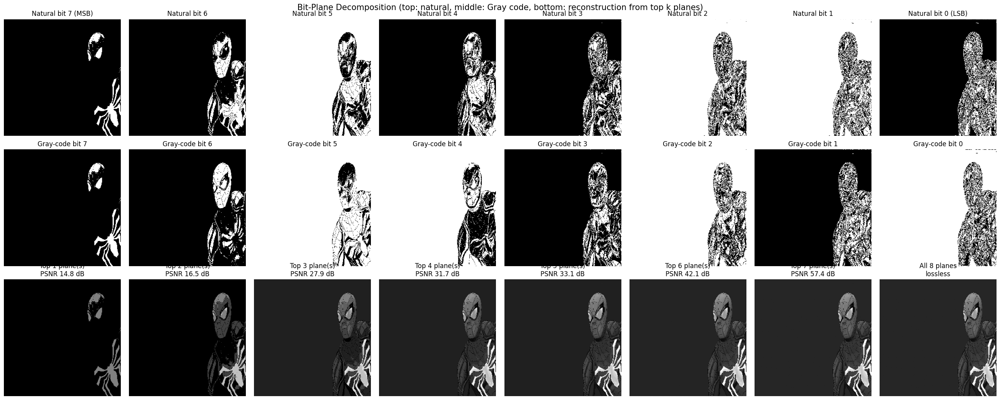

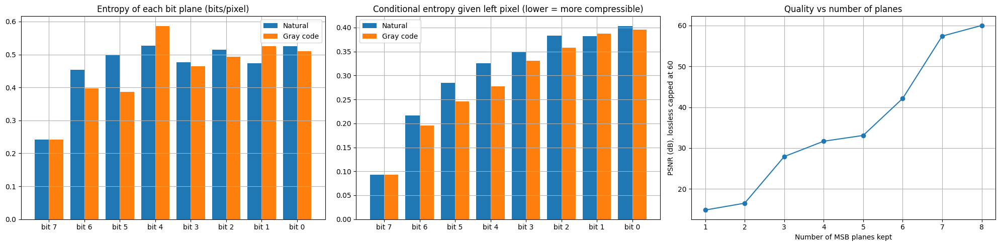


C. LOSSLESS PREDICTIVE CODING
Least-squares weights: a = 0.249, b = 0.670, c = 0.057

Predictor                             Entropy  Huffman L  Ratio (H)  Ratio (L)  Mean |e|  Zeros %
No prediction (original)                2.353      2.595      3.40:1      3.08:1                   
P1: left (a)                            1.999      2.298      4.00:1      3.48:1      5.38     80.8
P2: above (b)                           1.717      2.060      4.66:1      3.88:1      3.58     82.8
P3: above-left (c)                      2.061      2.351      3.88:1      3.40:1      5.91     80.3
P4: planar a+b-c                        2.020      2.310      3.96:1      3.46:1      5.01     80.3
P5: a+(b-c)/2                           2.036      2.325      3.93:1      3.44:1      4.90     80.2
P6: b+(a-c)/2                           1.937      2.236      4.13:1      3.58:1      4.20     80.7
P7: average (a+b)/2                     1.947      2.246      4.11:1      3.56:1      4.15     80.7
MED (JPEG-LS)  

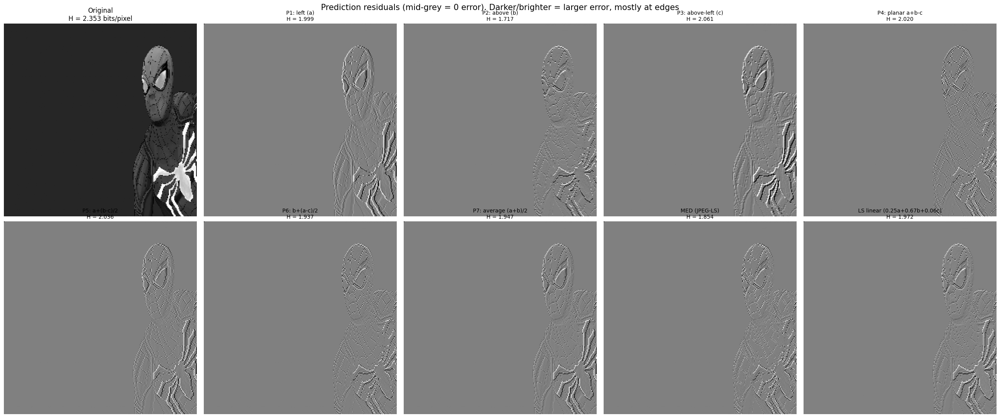

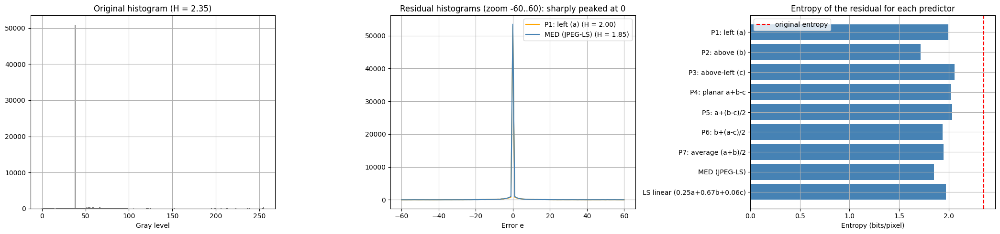


E. SUMMARY (payload only, raw = 8.000 bits/pixel)
Method                                     Bits/pixel    Ratio   Saving
Entropy, original pixels                        2.353    3.40:1    70.6%
Huffman, original pixels                        2.595    3.08:1    67.6%
Sum of bit-plane entropies (natural)            3.711    2.16:1    53.6%
Sum of bit-plane entropies (Gray)               3.604    2.22:1    55.0%
Bit planes, conditional on left (nat.)          2.438    3.28:1    69.5%
Bit planes, conditional on left (Gray)          2.285    3.50:1    71.4%
Entropy, residual of P2: above (b)              1.717    4.66:1    78.5%
Huffman, residual of P2: above (b)              2.060    3.88:1    74.3%


In [20]:
import cv2
import heapq
import itertools
import math
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# =====================================================================
# PART A: SMALL HAND-CHECKABLE EXAMPLES
# =====================================================================
print("=" * 70)
print("A1. BIT PLANES of a 4x4 image")
print("=" * 70)
tiny = np.array([[ 12, 200,   7, 255],
                 [ 13, 198,   9, 250],
                 [100, 101, 128, 129],
                 [ 99, 102, 127, 130]], dtype=np.uint8)
print("Image:\n", tiny)
print("\nBinary values of the first row:", [format(int(v), "08b") for v in tiny[0]])
tiny_planes = {b: (tiny >> b) & 1 for b in range(7, -1, -1)}
for b in range(7, -1, -1):
    print(f"\nBit plane {b} (weight 2^{b} = {2 ** b}):\n", tiny_planes[b])
rec_tiny = sum((tiny_planes[b].astype(np.int32) << b) for b in range(8))
print("\nSum of plane * 2^b == original image:", np.array_equal(rec_tiny, tiny))
tiny_gc = tiny ^ (tiny >> 1)
print("Gray code of 127 and 128 :", format(127 ^ (127 >> 1), "08b"), format(128 ^ (128 >> 1), "08b"),
      "(differ in 1 bit)  vs natural:", format(127, "08b"), format(128, "08b"), "(differ in 8 bits)")

print("\n" + "=" * 70)
print("A2. PREDICTIVE CODING (DPCM) of a 1-D signal, predictor f^(n) = f(n-1)")
print("=" * 70)
row = np.array([100, 102, 103, 103, 105, 110, 111, 109])
pred1 = np.concatenate(([0], row[:-1]))
err1 = row - pred1                         # e(n) = f(n) - f^(n); first sample is sent as it is
print("Signal f(n)   :", row.tolist())
print("Prediction    :", pred1.tolist())
print("Error e(n)    :", err1.tolist(), "<- small values near 0, so fewer bits")
dec1 = np.cumsum(err1)                     # f(n) = e(n) + f^(n)
print("Decoded       :", dec1.tolist(), "| identical to signal:", np.array_equal(dec1, row))

# =====================================================================
# PART B: LOAD IMAGE, BIT-PLANE DECOMPOSITION
# =====================================================================
print("\n" + "=" * 70)
print("B. BIT-PLANE DECOMPOSITION OF THE IMAGE")
print("=" * 70)
uploaded = files.upload()
img_path = list(uploaded.keys())[0]
gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))
H, W = gray.shape
N = H * W
g = gray.astype(np.int32)
print("Image size:", gray.shape, "| raw size =", N, "bytes (8 bits/pixel)")

def entropy(x, offset=0):
    counts = np.bincount(np.asarray(x).ravel() + offset)
    p = counts[counts > 0] / counts.sum()
    return float(-(p * np.log2(p)).sum())

def bin_entropy(plane):
    p1 = plane.mean()
    return 0.0 if p1 in (0, 1) else float(-(p1 * math.log2(p1) + (1 - p1) * math.log2(1 - p1)))

def cond_entropy(plane):
    # H(X | left neighbour in the same plane): captures spatial correlation inside a plane
    Lft, Cur = plane[:, :-1].ravel().astype(int), plane[:, 1:].ravel().astype(int)
    joint = np.bincount(Lft * 2 + Cur, minlength=4).reshape(2, 2) / Lft.size
    pL = joint.sum(axis=1)
    h = 0.0
    for a in range(2):
        for b in range(2):
            if joint[a, b] > 0:
                h -= joint[a, b] * math.log2(joint[a, b] / pL[a])
    return h

def n_runs(plane):
    f = plane.ravel()
    return int(np.count_nonzero(f[1:] != f[:-1]) + 1)

gray_code = g ^ (g >> 1)
planes_nat = {b: ((g >> b) & 1).astype(np.uint8) for b in range(7, -1, -1)}
planes_gc = {b: ((gray_code >> b) & 1).astype(np.uint8) for b in range(7, -1, -1)}

# Lossless check: natural binary planes and Gray-code planes both rebuild the image
rec_nat = sum((planes_nat[b].astype(np.int32) << b) for b in range(8))
gc_rec = sum((planes_gc[b].astype(np.int32) << b) for b in range(8))
bn, sh = gc_rec.copy(), 1
while sh < 8:                                    # Gray -> binary: b = g ^ (g>>1) ^ (g>>2) ...
    bn ^= (bn >> sh); sh <<= 1
print("Natural planes rebuild the image exactly :", np.array_equal(rec_nat, g))
print("Gray-code planes rebuild the image exactly:", np.array_equal(bn, g))

H_img = entropy(g)
print(f"\nEntropy of the whole image = {H_img:.3f} bits/pixel")
print(f"\n{'Plane':>6s} | {'H natural':>9s} | {'H Gray':>7s} | {'H|left nat':>10s} | {'H|left Gray':>11s} | {'Runs nat':>8s} | {'Runs Gray':>9s}")
sum_nat = sum_gc = sum_cn = sum_cg = 0.0
for b in range(7, -1, -1):
    hn, hg = bin_entropy(planes_nat[b]), bin_entropy(planes_gc[b])
    cn, cg = cond_entropy(planes_nat[b]), cond_entropy(planes_gc[b])
    sum_nat += hn; sum_gc += hg; sum_cn += cn; sum_cg += cg
    print(f"{'bit ' + str(b):>6s} | {hn:9.3f} | {hg:7.3f} | {cn:10.3f} | {cg:11.3f} | {n_runs(planes_nat[b]):8d} | {n_runs(planes_gc[b]):9d}")
print(f"{'Total':>6s} | {sum_nat:9.3f} | {sum_gc:7.3f} | {sum_cn:10.3f} | {sum_cg:11.3f}  (bits/pixel)")
print("Sum of plane entropies >= image entropy; the 'H|left' columns show how much neighbouring pixels in a plane help.")

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * math.log10(255 ** 2 / mse)

print(f"\n{'Planes kept':>11s} | {'Bits/pixel':>10s} | {'PSNR (dB)':>9s}")
recs = {}
for k in range(1, 9):
    r = ((g >> (8 - k)) << (8 - k)).astype(np.uint8)     # keep the top k planes, zero the rest
    recs[k] = r
    p = psnr(gray, r)
    print(f"{'top ' + str(k):>11s} | {k:10d} | {('inf (lossless)' if p == float('inf') else f'{p:9.2f}'):>9s}")

# Display: natural planes, Gray planes, reconstructions
fig, axes = plt.subplots(3, 8, figsize=(26, 10.5))
for j, b in enumerate(range(7, -1, -1)):
    axes[0, j].imshow(planes_nat[b], cmap="gray"); axes[0, j].set_title(f"Natural bit {b}" + (" (MSB)" if b == 7 else " (LSB)" if b == 0 else ""))
    axes[1, j].imshow(planes_gc[b], cmap="gray");  axes[1, j].set_title(f"Gray-code bit {b}")
    axes[2, j].imshow(recs[j + 1], cmap="gray", vmin=0, vmax=255)
    axes[2, j].set_title(f"Top {j + 1} plane(s)\nPSNR {psnr(gray, recs[j + 1]):.1f} dB" if j < 7 else "All 8 planes\nlossless")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Bit-Plane Decomposition (top: natural, middle: Gray code, bottom: reconstruction from top k planes)", fontsize=15)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
x = np.arange(8)
axes[0].bar(x - 0.2, [bin_entropy(planes_nat[b]) for b in range(7, -1, -1)], 0.4, label="Natural")
axes[0].bar(x + 0.2, [bin_entropy(planes_gc[b]) for b in range(7, -1, -1)], 0.4, label="Gray code")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"bit {b}" for b in range(7, -1, -1)])
axes[0].set_title("Entropy of each bit plane (bits/pixel)"); axes[0].legend(); axes[0].grid(True)
axes[1].bar(x - 0.2, [cond_entropy(planes_nat[b]) for b in range(7, -1, -1)], 0.4, label="Natural")
axes[1].bar(x + 0.2, [cond_entropy(planes_gc[b]) for b in range(7, -1, -1)], 0.4, label="Gray code")
axes[1].set_xticks(x); axes[1].set_xticklabels([f"bit {b}" for b in range(7, -1, -1)])
axes[1].set_title("Conditional entropy given left pixel (lower = more compressible)"); axes[1].legend(); axes[1].grid(True)
axes[2].plot(range(1, 9), [min(psnr(gray, recs[k]), 60) for k in range(1, 9)], "o-")
axes[2].set_xlabel("Number of MSB planes kept"); axes[2].set_ylabel("PSNR (dB), lossless capped at 60")
axes[2].set_title("Quality vs number of planes"); axes[2].grid(True)
plt.tight_layout(); plt.show()

# =====================================================================
# PART C: LOSSLESS PREDICTIVE CODING
#   e(x,y) = f(x,y) - f^(x,y),  f^ = predictor of the neighbours a (left), b (above), c (above-left)
# =====================================================================
def neighbours(img):
    # Same border rule is used by the decoder: top row -> b = c = a ; left column -> a = c = b ; (0,0) -> 128
    a = np.zeros_like(img); b = np.zeros_like(img); c = np.zeros_like(img)
    a[:, 1:] = img[:, :-1]; b[1:, :] = img[:-1, :]; c[1:, 1:] = img[:-1, :-1]
    b[0, 1:] = a[0, 1:]; c[0, 1:] = a[0, 1:]
    a[1:, 0] = b[1:, 0]; c[1:, 0] = b[1:, 0]
    a[0, 0] = b[0, 0] = c[0, 0] = 128
    return a, b, c

def med(a, b, c):                                  # Median Edge Detector (LOCO-I / JPEG-LS)
    mx, mn = np.maximum(a, b), np.minimum(a, b)
    return np.where(c >= mx, mn, np.where(c <= mn, mx, a + b - c))

predictors = {
    "P1: left (a)":            lambda a, b, c: a,
    "P2: above (b)":           lambda a, b, c: b,
    "P3: above-left (c)":      lambda a, b, c: c,
    "P4: planar a+b-c":        lambda a, b, c: a + b - c,
    "P5: a+(b-c)/2":           lambda a, b, c: a + (b - c) // 2,
    "P6: b+(a-c)/2":           lambda a, b, c: b + (a - c) // 2,
    "P7: average (a+b)/2":     lambda a, b, c: (a + b) // 2,
    "MED (JPEG-LS)":           med,
}

A_, B_, C_ = neighbours(g)
preds, resid = {}, {}
for name, fn in predictors.items():
    p = np.clip(fn(A_, B_, C_), 0, 255)
    preds[name] = p
    resid[name] = g - p

# Least-squares optimal linear predictor f^ = w1*a + w2*b + w3*c  (weights are sent as side information)
X = np.stack([A_.ravel(), B_.ravel(), C_.ravel()], axis=1).astype(np.float64)
w, *_ = np.linalg.lstsq(X, g.ravel().astype(np.float64), rcond=None)
p_ls = np.clip(np.round(X @ w), 0, 255).astype(np.int32).reshape(H, W)
name_ls = f"LS linear ({w[0]:.2f}a+{w[1]:.2f}b{w[2]:+.2f}c)"
preds[name_ls] = p_ls
resid[name_ls] = g - p_ls
print("\n" + "=" * 70)
print("C. LOSSLESS PREDICTIVE CODING")
print("=" * 70)
print(f"Least-squares weights: a = {w[0]:.3f}, b = {w[1]:.3f}, c = {w[2]:.3f}")

def huffman_avg_length(counts):
    # Average Huffman length = (sum of all merged weights) / total
    heap = [(int(c), i) for i, c in enumerate(counts) if c > 0]
    if len(heap) == 1:
        return 1.0
    heapq.heapify(heap)
    tick, total_cost = itertools.count(1000), 0
    while len(heap) > 1:
        w1, _ = heapq.heappop(heap); w2, _ = heapq.heappop(heap)
        total_cost += w1 + w2
        heapq.heappush(heap, (w1 + w2, next(tick)))
    return total_cost / sum(int(c) for c in counts)

H_orig = H_img
L_orig = huffman_avg_length(np.bincount(g.ravel()))
print(f"\n{'Predictor':36s}{'Entropy':>9s}{'Huffman L':>11s}{'Ratio (H)':>11s}{'Ratio (L)':>11s}{'Mean |e|':>10s}{'Zeros %':>9s}")
print(f"{'No prediction (original)':36s}{H_orig:9.3f}{L_orig:11.3f}{8 / H_orig:10.2f}:1{8 / L_orig:10.2f}:1{'':>10s}{'':>9s}")
stats = {}
for name, e in resid.items():
    Hh = entropy(e, 255)
    Ll = huffman_avg_length(np.bincount(e.ravel() + 255))
    stats[name] = (Hh, Ll)
    print(f"{name:36s}{Hh:9.3f}{Ll:11.3f}{8 / Hh:10.2f}:1{8 / Ll:10.2f}:1{np.abs(e).mean():10.2f}{100 * np.mean(e == 0):9.1f}")
best = min(stats, key=lambda k: stats[k][0])
print(f"\nBest predictor by entropy: {best} ({stats[best][0]:.3f} bits/pixel)")

# =====================================================================
# PART D: DECODER - rebuild the image pixel by pixel from the residuals only
# =====================================================================
def lossless_decode(e, fn):
    rec = np.zeros(e.shape, np.int32)
    for i in range(e.shape[0]):
        for j in range(e.shape[1]):
            if i == 0 and j == 0:
                a = b = c = 128
            elif i == 0:
                a = rec[i, j - 1]; b = c = a
            elif j == 0:
                b = rec[i - 1, j]; a = c = b
            else:
                a, b, c = rec[i, j - 1], rec[i - 1, j], rec[i - 1, j - 1]
            p = int(np.clip(fn(np.int32(a), np.int32(b), np.int32(c)), 0, 255))
            rec[i, j] = p + e[i, j]                 # f = e + f^
    return rec

print("\n" + "=" * 70)
print("D. DECODING CHECK (rebuild image from residuals using the same predictor)")
print("=" * 70)
for name in ["P1: left (a)", "P4: planar a+b-c", "MED (JPEG-LS)"]:
    dec = lossless_decode(resid[name], predictors[name])
    print(f"{name:20s}: decoded == original image : {np.array_equal(dec, g)}")

# =====================================================================
# DISPLAY
# =====================================================================
names = list(resid.keys())
fig, axes = plt.subplots(2, 5, figsize=(26, 11))
axes[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title(f"Original\nH = {H_img:.3f} bits/pixel")
for ax, nm in zip(list(axes.ravel()[1:]), names):
    ax.imshow(np.clip(resid[nm] + 128, 0, 255), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{nm}\nH = {stats[nm][0]:.3f}", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Prediction residuals (mid-grey = 0 error). Darker/brighter = larger error, mostly at edges", fontsize=15)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
axes[0].bar(np.arange(256), np.bincount(g.ravel(), minlength=256), width=1, color="gray")
axes[0].set_title(f"Original histogram (H = {H_img:.2f})"); axes[0].set_xlabel("Gray level")
for nm, col in [("P1: left (a)", "orange"), ("MED (JPEG-LS)", "steelblue")]:
    axes[1].plot(np.arange(-60, 61), np.bincount(resid[nm].ravel() + 255, minlength=511)[255 - 60:255 + 61],
                 color=col, label=f"{nm} (H = {stats[nm][0]:.2f})")
axes[1].set_title("Residual histograms (zoom -60..60): sharply peaked at 0"); axes[1].legend(); axes[1].set_xlabel("Error e")
axes[2].barh(names[::-1], [stats[n][0] for n in names[::-1]], color="steelblue")
axes[2].axvline(H_img, color="r", ls="--", label="original entropy")
axes[2].set_xlabel("Entropy (bits/pixel)"); axes[2].set_title("Entropy of the residual for each predictor"); axes[2].legend()
for ax in axes:
    ax.grid(True)
plt.tight_layout(); plt.show()

# =====================================================================
# PART E: SUMMARY
# =====================================================================
print("\n" + "=" * 70)
print("E. SUMMARY (payload only, raw = 8.000 bits/pixel)")
print("=" * 70)
rows = [("Entropy, original pixels",              H_img),
        ("Huffman, original pixels",              L_orig),
        ("Sum of bit-plane entropies (natural)",  sum_nat),
        ("Sum of bit-plane entropies (Gray)",     sum_gc),
        ("Bit planes, conditional on left (nat.)", sum_cn),
        ("Bit planes, conditional on left (Gray)", sum_cg),
        (f"Entropy, residual of {best}",          stats[best][0]),
        (f"Huffman, residual of {best}",          stats[best][1])]
print(f"{'Method':42s}{'Bits/pixel':>11s}{'Ratio':>9s}{'Saving':>9s}")
for nm, bpp in rows:
    print(f"{nm:42s}{bpp:11.3f}{8 / bpp:8.2f}:1{100 * (1 - bpp / 8):8.1f}%")

A. JPEG PIPELINE ON ONE 8x8 BLOCK
DCT matrix is orthonormal (C C^T = I): True
My DCT == cv2.dct: True
DC coefficient = -416.00  (= 8 x mean of the shifted block = -416.00)

Original block:
 [[ 52  55  61  66  70  61  64  73]
 [ 63  59  55  90 109  85  69  72]
 [ 62  59  68 113 144 104  66  73]
 [ 63  58  71 122 149 106  70  69]
 [ 67  61  68 104 126  88  68  70]
 [ 79  65  60  70  77  68  58  75]
 [ 85  71  64  59  55  61  65  83]
 [ 87  79  69  68  65  76  78  94]]

DCT coefficients (rounded):
 [[-416  -30  -60   27   55  -19   -2    0]
 [   4  -22  -61   10   13   -7   -8    5]
 [ -46    7   76  -24  -28    9    5   -5]
 [ -48   12   33  -14  -10    6    2    3]
 [  11   -6  -12   -4   -2    2   -2    2]
 [  -8    3    3   -7   -3    2    5    1]
 [  -1    0    0   -2   -1   -3    4    0]
 [   1    0   -2   -4    0   -1    0    3]]

Quantized coefficients (Q = 50 table):
 [[-26  -3  -6   2   2   0   0   0]
 [  0  -2  -4   1   0   0   0   0]
 [ -3   1   5  -1  -1   0   0   0]
 [ -3   

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers.jpg
Image size: (256, 256) | blocks: 1024 | raw = 8 bits/pixel
DCT -> IDCT with no quantization is lossless: True

Energy compaction (share of total coefficient energy in the first k zigzag coefficients):
  first  1 of 64 coefficients:  92.683 % of energy
  first  3 of 64 coefficients:  95.024 % of energy
  first  6 of 64 coefficients:  96.383 % of energy
  first 10 of 64 coefficients:  97.319 % of energy
  first 15 of 64 coefficients:  97.970 % of energy
  first 28 of 64 coefficients:  98.754 % of energy
  first 64 of 64 coefficients: 100.000 % of energy

k kept | PSNR (dB)
     1 |     20.61
     3 |     22.30
     6 |     23.74
    10 |     25.05
    15 |     26.28
    28 |     28.45
    64 | lossless

C. JPEG-STYLE COMPRESSION vs QUALITY FACTOR
Standard luminance table (Q = 50):
 [[ 16  11  10  16  24  40  51  61]
 [ 12  12  14  19  26  58  60  55]
 [ 14  13  16  24  40  57  69  56]
 [ 14  17  22  2

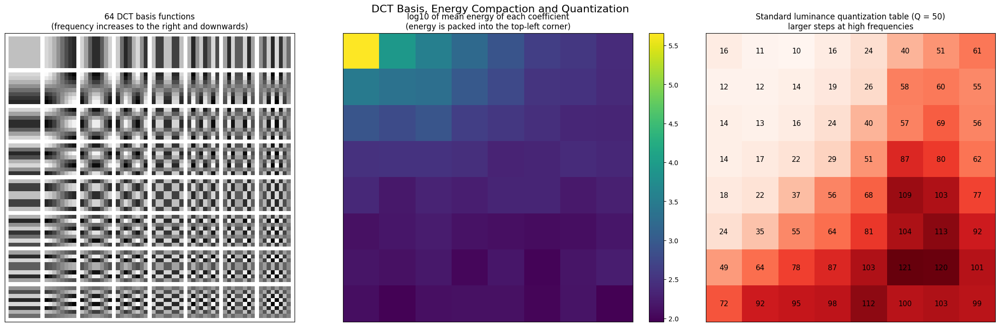

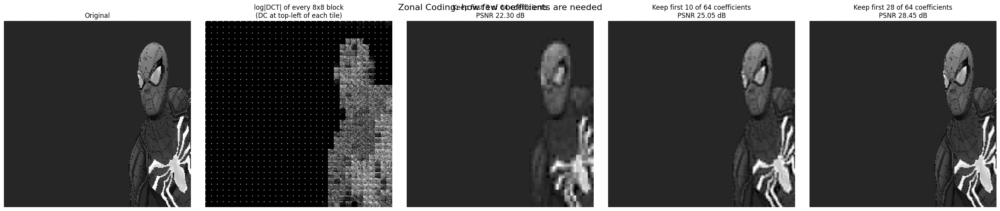

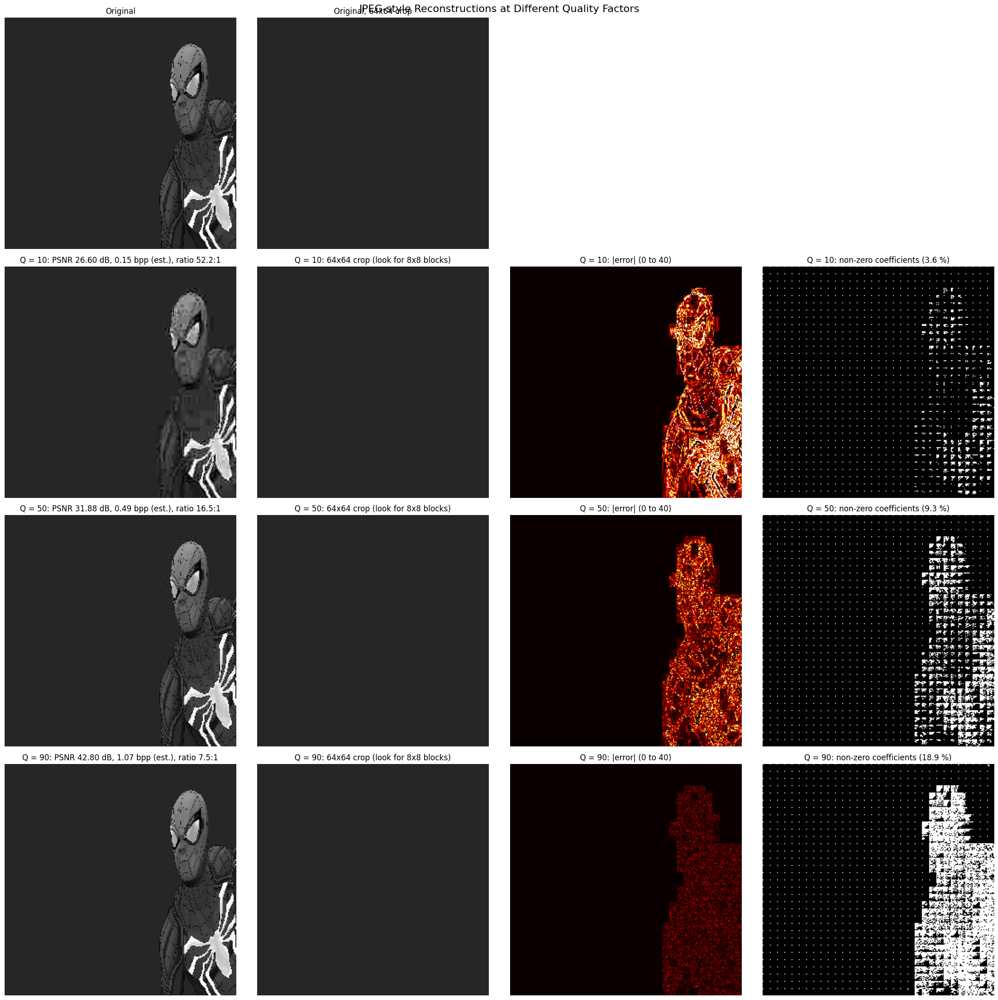

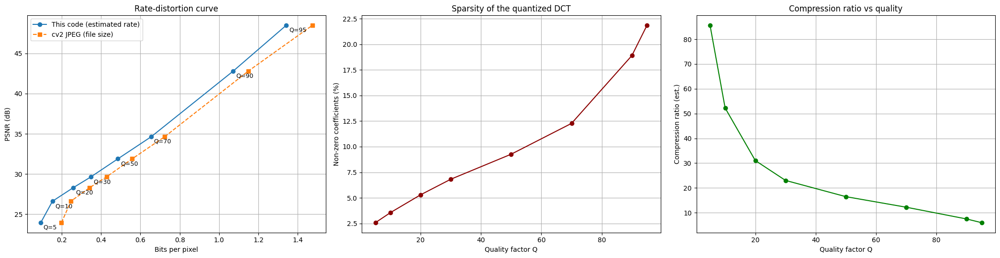


SUMMARY (grayscale, raw = 8 bits/pixel)
 Quality   PSNR dB  bits/pixel    ratio   saving
       5     23.93       0.093    85.6:1    98.8%
      10     26.60       0.153    52.2:1    98.1%
      20     28.27       0.258    31.0:1    96.8%
      30     29.62       0.348    23.0:1    95.7%
      50     31.88       0.486    16.5:1    93.9%
      70     34.64       0.655    12.2:1    91.8%
      90     42.80       1.072     7.5:1    86.6%
      95     48.51       1.341     6.0:1    83.2%


In [1]:
import cv2
import math
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from google.colab import files

# =====================================================================
# SETUP: DCT matrix, standard JPEG luminance quantization table, zigzag order
# =====================================================================
def dct_matrix(n=8):
    # C[k, i] = alpha(k) * cos((2i+1) k pi / 2n),  alpha(0)=sqrt(1/n), alpha(k>0)=sqrt(2/n)
    C = np.zeros((n, n))
    for k in range(n):
        a = math.sqrt(1 / n) if k == 0 else math.sqrt(2 / n)
        for i in range(n):
            C[k, i] = a * math.cos((2 * i + 1) * k * math.pi / (2 * n))
    return C

C = dct_matrix(8)

Q50 = np.array([[16, 11, 10, 16, 24, 40, 51, 61],
                [12, 12, 14, 19, 26, 58, 60, 55],
                [14, 13, 16, 24, 40, 57, 69, 56],
                [14, 17, 22, 29, 51, 87, 80, 62],
                [18, 22, 37, 56, 68, 109, 103, 77],
                [24, 35, 55, 64, 81, 104, 113, 92],
                [49, 64, 78, 87, 103, 121, 120, 101],
                [72, 92, 95, 98, 112, 100, 103, 99]], dtype=np.float64)

def qtable(Q):
    # IJG quality scaling: Q=50 gives the standard table, lower Q = coarser steps
    s = 5000 / Q if Q < 50 else 200 - 2 * Q
    return np.clip(np.floor((Q50 * s + 50) / 100), 1, 255)

# Zigzag order: sort by anti-diagonal, alternating direction on each diagonal
ZZ = sorted(((i, j) for i in range(8) for j in range(8)),
            key=lambda p: (p[0] + p[1], p[1] if (p[0] + p[1]) % 2 == 0 else p[0]))

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * math.log10(255 ** 2 / mse)

# =====================================================================
# PART A: ONE 8x8 BLOCK, STEP BY STEP
# =====================================================================
print("=" * 70)
print("A. JPEG PIPELINE ON ONE 8x8 BLOCK")
print("=" * 70)
blk = np.array([[52, 55, 61, 66, 70, 61, 64, 73],
                [63, 59, 55, 90, 109, 85, 69, 72],
                [62, 59, 68, 113, 144, 104, 66, 73],
                [63, 58, 71, 122, 149, 106, 70, 69],
                [67, 61, 68, 104, 126, 88, 68, 70],
                [79, 65, 60, 70, 77, 68, 58, 75],
                [85, 71, 64, 59, 55, 61, 65, 83],
                [87, 79, 69, 68, 65, 76, 78, 94]], dtype=np.float64)
np.set_printoptions(linewidth=150, suppress=True)
print("DCT matrix is orthonormal (C C^T = I):", np.allclose(C @ C.T, np.eye(8)))
shifted = blk - 128                                       # level shift: [0,255] -> [-128,127]
D = C @ shifted @ C.T                                     # 2-D DCT: F = C f C^T
print("My DCT == cv2.dct:", np.allclose(D, cv2.dct(shifted.astype(np.float32)), atol=1e-3))
print(f"DC coefficient = {D[0, 0]:.2f}  (= 8 x mean of the shifted block = {8 * shifted.mean():.2f})")
print("\nOriginal block:\n", blk.astype(int))
print("\nDCT coefficients (rounded):\n", np.round(D).astype(int))
Qb = Q50
qb = np.round(D / Qb).astype(int)                         # quantization: the ONLY lossy step
print("\nQuantized coefficients (Q = 50 table):\n", qb)
print(f"Non-zero coefficients: {np.count_nonzero(qb)} of 64")
zz = [int(qb[i, j]) for i, j in ZZ]
print("\nZigzag scan:", zz)
last = max(i for i, v in enumerate(zz) if v != 0)
print(f"Last non-zero at position {last}; the remaining {63 - last} zeros are replaced by one EOB code")
rec_blk = np.clip(np.round(C.T @ (qb * Qb) @ C + 128), 0, 255)     # dequantize, IDCT, shift back
print("\nReconstructed block:\n", rec_blk.astype(int))
print("Error (reconstructed - original):\n", (rec_blk - blk).astype(int))
print(f"Block PSNR = {psnr(blk, rec_blk):.2f} dB | max |error| = {int(np.abs(rec_blk - blk).max())}")
unq = C.T @ D @ C + 128
print("Without quantization the IDCT recovers the block exactly:", np.allclose(unq, blk))

# =====================================================================
# PART B: LOAD IMAGE, BLOCK DCT OF THE WHOLE IMAGE
# =====================================================================
print("\n" + "=" * 70)
print("B. BLOCK DCT OF THE IMAGE")
print("=" * 70)
uploaded = files.upload()
img_path = list(uploaded.keys())[0]
gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))                       # multiple of 8 and fast
H, W = gray.shape
g = gray.astype(np.float64)
N = H * W
print("Image size:", gray.shape, "| blocks:", (H // 8) * (W // 8), "| raw = 8 bits/pixel")

def to_blocks(img):   return img.reshape(H // 8, 8, W // 8, 8).transpose(0, 2, 1, 3)
def from_blocks(b):   return b.transpose(0, 2, 1, 3).reshape(H, W)
def dct_blocks(b):    return C @ b @ C.T
def idct_blocks(d):   return C.T @ d @ C

D_all = dct_blocks(to_blocks(g - 128))
rec0 = np.clip(np.round(from_blocks(idct_blocks(D_all)) + 128), 0, 255).astype(np.uint8)
print("DCT -> IDCT with no quantization is lossless:", np.array_equal(rec0, gray))

# Energy compaction
energy = (D_all ** 2).mean(axis=(0, 1))
tot = energy.sum()
print("\nEnergy compaction (share of total coefficient energy in the first k zigzag coefficients):")
cum = np.cumsum([energy[i, j] for i, j in ZZ]) / tot
for k in [1, 3, 6, 10, 15, 28, 64]:
    print(f"  first {k:2d} of 64 coefficients: {100 * cum[k - 1]:7.3f} % of energy")

# Zonal coding: keep only the first k zigzag coefficients of every block, no quantization
print(f"\n{'k kept':>6s} | {'PSNR (dB)':>9s}")
zonal = {}
for k in [1, 3, 6, 10, 15, 28, 64]:
    mask = np.zeros((8, 8))
    for i, j in ZZ[:k]:
        mask[i, j] = 1
    r = np.clip(np.round(from_blocks(idct_blocks(D_all * mask)) + 128), 0, 255).astype(np.uint8)
    zonal[k] = r
    p = psnr(gray, r)
    print(f"{k:6d} | {'lossless' if p == float('inf') else f'{p:9.2f}'}")

# =====================================================================
# PART C: JPEG-STYLE COMPRESSION AT DIFFERENT QUALITY FACTORS
# =====================================================================
def compress(Q):
    qt = qtable(Q)
    q = np.round(D_all / qt).astype(np.int32)             # quantize
    rec = np.clip(np.round(from_blocks(idct_blocks(q * qt)) + 128), 0, 255).astype(np.uint8)
    return q, rec

def entropy_bits(symbols):
    n = len(symbols)
    return 0.0 if n == 0 else -sum(c * math.log2(c / n) for c in Counter(symbols).values())

def jpeg_bits(q):
    # DC: difference from the previous block, coded as (size) + size extra bits
    # AC: zigzag, (zero-run, size) symbols + size extra bits, ZRL for runs > 15, EOB for trailing zeros
    # Symbol cost = entropy (ideal Huffman); header and table bytes are not counted
    dc, ac, extra, prev = [], [], 0, 0
    for bi in range(q.shape[0]):
        for bj in range(q.shape[1]):
            z = [int(q[bi, bj, i, j]) for i, j in ZZ]
            d = z[0] - prev; prev = z[0]
            s = abs(d).bit_length(); dc.append(s); extra += s
            run = 0
            for v in z[1:]:
                if v == 0:
                    run += 1
                else:
                    while run > 15:
                        ac.append((15, 0)); run -= 16
                    s = abs(v).bit_length(); ac.append((run, s)); extra += s; run = 0
            if run > 0:
                ac.append((0, 0))                          # EOB
    return entropy_bits(dc) + entropy_bits(ac) + extra

print("\n" + "=" * 70)
print("C. JPEG-STYLE COMPRESSION vs QUALITY FACTOR")
print("=" * 70)
print("Standard luminance table (Q = 50):\n", Q50.astype(int))
print("\nQuantization table for Q = 10:\n", qtable(10).astype(int))

Qs = [5, 10, 20, 30, 50, 70, 90, 95]
res = {}
print(f"\n{'Q':>3s} | {'PSNR':>6s} | {'Non-zero %':>10s} | {'Est. bpp':>8s} | {'Est. ratio':>10s} | "
      f"{'cv2 JPEG bytes':>14s} | {'cv2 ratio':>9s} | {'cv2 PSNR':>8s}")
for Q in Qs:
    q, rec = compress(Q)
    bits = jpeg_bits(q)
    ok, buf = cv2.imencode(".jpg", gray, [int(cv2.IMWRITE_JPEG_QUALITY), Q])
    cv_rec = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
    res[Q] = dict(q=q, rec=rec, psnr=psnr(gray, rec), nz=100 * np.count_nonzero(q) / q.size,
                  bpp=bits / N, cv_bytes=len(buf), cv_bpp=8 * len(buf) / N, cv_psnr=psnr(gray, cv_rec))
    r = res[Q]
    print(f"{Q:3d} | {r['psnr']:6.2f} | {r['nz']:10.2f} | {r['bpp']:8.3f} | {8 / r['bpp']:9.2f}:1 | "
          f"{r['cv_bytes']:14d} | {8 * N / 8 / r['cv_bytes']:8.2f}:1 | {r['cv_psnr']:8.2f}")
print("Est. = DC differences + (run,size) symbols at entropy + extra bits. cv2 includes file headers and uses fixed Huffman tables.")

# Blocking artifacts: error measured on block boundaries vs inside blocks
def boundary_ratio(a):
    d = np.abs(np.diff(a.astype(np.float64), axis=1))     # horizontal neighbour differences
    cols = np.arange(d.shape[1])
    edge = d[:, cols % 8 == 7].mean()
    inside = d[:, cols % 8 != 7].mean()
    return edge / inside
print(f"\nBlocking measure (mean step across block borders / inside blocks; 1.0 = no visible blocks):")
print(f"  Original: {boundary_ratio(gray):.3f}")
for Q in [10, 50, 90]:
    print(f"  Q = {Q:2d}  : {boundary_ratio(res[Q]['rec']):.3f}")

# =====================================================================
# DISPLAY
# =====================================================================
# Figure 1: basis functions, energy per coefficient, quantization table
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
tile = np.ones((8 * 9 + 1, 8 * 9 + 1))
for u in range(8):
    for v in range(8):
        b = np.outer(C[u], C[v])
        tile[1 + u * 9: 1 + u * 9 + 8, 1 + v * 9: 1 + v * 9 + 8] = (b + 0.25) / 0.5
axes[0].imshow(tile, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("64 DCT basis functions\n(frequency increases to the right and downwards)")
im = axes[1].imshow(np.log10(energy + 1e-9), cmap="viridis")
axes[1].set_title("log10 of mean energy of each coefficient\n(energy is packed into the top-left corner)")
plt.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].imshow(Q50, cmap="Reds")
for i in range(8):
    for j in range(8):
        axes[2].text(j, i, int(Q50[i, j]), ha="center", va="center", fontsize=11)
axes[2].set_title("Standard luminance quantization table (Q = 50)\nlarger steps at high frequencies")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("DCT Basis, Energy Compaction and Quantization", fontsize=16)
plt.tight_layout(); plt.show()

# Figure 2: zonal coding and DCT mosaic
fig, axes = plt.subplots(1, 5, figsize=(26, 5.5))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[0].set_title("Original")
axes[1].imshow(from_blocks(np.log1p(np.abs(D_all))), cmap="gray")
axes[1].set_title("log|DCT| of every 8x8 block\n(DC at top-left of each tile)")
for ax, k in zip(axes[2:], [3, 10, 28]):
    ax.imshow(zonal[k], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Keep first {k} of 64 coefficients\nPSNR {psnr(gray, zonal[k]):.2f} dB")
for ax in axes:
    ax.axis("off")
plt.suptitle("Zonal Coding: how few coefficients are needed", fontsize=16)
plt.tight_layout(); plt.show()

# Figure 3: reconstructions at Q = 10, 50, 90 with error, zoomed crop and non-zero map
cy, cx = H // 2 - 32, W // 2 - 32
fig, axes = plt.subplots(4, 4, figsize=(22, 22))
axes[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[0, 0].set_title("Original")
axes[0, 1].imshow(gray[cy:cy + 64, cx:cx + 64], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0, 1].set_title("Original, 64x64 crop")
axes[0, 2].imshow(from_blocks(np.ones((H // 8, W // 8, 8, 8)) * 0) + (np.indices((H, W)).sum(0) % 2) * 0, cmap="gray")
axes[0, 2].axis("off")
axes[0, 3].axis("off")
axes[0, 2].set_visible(False); axes[0, 3].set_visible(False)
for row, Q in enumerate([10, 50, 90], start=1):
    r = res[Q]
    axes[row, 0].imshow(r["rec"], cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"Q = {Q}: PSNR {r['psnr']:.2f} dB, {r['bpp']:.2f} bpp (est.), ratio {8 / r['bpp']:.1f}:1")
    axes[row, 1].imshow(r["rec"][cy:cy + 64, cx:cx + 64], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[row, 1].set_title(f"Q = {Q}: 64x64 crop (look for 8x8 blocks)")
    axes[row, 2].imshow(np.abs(g - r["rec"].astype(float)), cmap="hot", vmin=0, vmax=40)
    axes[row, 2].set_title(f"Q = {Q}: |error| (0 to 40)")
    axes[row, 3].imshow(from_blocks((r["q"] != 0).astype(float)), cmap="gray")
    axes[row, 3].set_title(f"Q = {Q}: non-zero coefficients ({r['nz']:.1f} %)")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("JPEG-style Reconstructions at Different Quality Factors", fontsize=16)
plt.tight_layout(); plt.show()

# Figure 4: rate-distortion and sparsity
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
axes[0].plot([res[Q]["bpp"] for Q in Qs], [res[Q]["psnr"] for Q in Qs], "o-", label="This code (estimated rate)")
axes[0].plot([res[Q]["cv_bpp"] for Q in Qs], [res[Q]["cv_psnr"] for Q in Qs], "s--", label="cv2 JPEG (file size)")
for Q in Qs:
    axes[0].annotate(f"Q={Q}", (res[Q]["bpp"], res[Q]["psnr"]), fontsize=9, xytext=(4, -10), textcoords="offset points")
axes[0].set_xlabel("Bits per pixel"); axes[0].set_ylabel("PSNR (dB)")
axes[0].set_title("Rate-distortion curve"); axes[0].legend(); axes[0].grid(True)
axes[1].plot(Qs, [res[Q]["nz"] for Q in Qs], "o-", color="darkred")
axes[1].set_xlabel("Quality factor Q"); axes[1].set_ylabel("Non-zero coefficients (%)")
axes[1].set_title("Sparsity of the quantized DCT"); axes[1].grid(True)
axes[2].plot(Qs, [8 / res[Q]["bpp"] for Q in Qs], "o-", color="green")
axes[2].set_xlabel("Quality factor Q"); axes[2].set_ylabel("Compression ratio (est.)")
axes[2].set_title("Compression ratio vs quality"); axes[2].grid(True)
plt.tight_layout(); plt.show()

# =====================================================================
# SUMMARY
# =====================================================================
print("\n" + "=" * 70)
print("SUMMARY (grayscale, raw = 8 bits/pixel)")
print("=" * 70)
print(f"{'Quality':>8s}{'PSNR dB':>10s}{'bits/pixel':>12s}{'ratio':>9s}{'saving':>9s}")
for Q in Qs:
    r = res[Q]
    print(f"{Q:8d}{r['psnr']:10.2f}{r['bpp']:12.3f}{8 / r['bpp']:8.1f}:1{100 * (1 - r['bpp'] / 8):8.1f}%")

A. HAAR WAVELET / TWO-BAND SUBBAND CODING OF A 1-D SIGNAL
Signal x             : [9.0, 7.0, 3.0, 5.0, 6.0, 10.0, 2.0, 6.0]
Pair averages        : [8.0, 4.0, 8.0, 4.0] <- low-pass band (half the samples)
Pair half-differences: [1.0, -1.0, -2.0, -2.0] <- high-pass band (detail)
Level 2 averages     : [6.0, 6.0] | details: [2.0, 2.0]
Level 3 average      : 6.0 | detail: 0.0
Full transform       : [np.float64(6.0), np.float64(0.0), 2.0, 2.0, 1.0, -1.0, -2.0, -2.0] (1 average + 7 details = 8 numbers, no redundancy)
Reconstruction       : [9.0, 7.0, 3.0, 5.0, 6.0, 10.0, 2.0, 6.0] | exact: True

Filter-bank view (orthonormal Haar: h0 = [1 1]/sqrt2, h1 = [-1 1]/sqrt2, downsample by 2)
  Low band : [11.314, 5.657, 11.314, 5.657]
  High band: [1.414, -1.414, -2.828, -2.828]
  Same as the lifting code: True
  Energy of x = 340.0, energy of subbands = 340.0 (orthonormal: equal)
  Quantizing all details to zero keeps the smooth shape: [8.0, 8.0, 4.0, 4.0, 8.0, 8.0, 4.0, 4.0]

B. 2-D WAVELET DECOMPO

Saving wp4140976-spider-man-4k-wallpapers.jpg to wp4140976-spider-man-4k-wallpapers (1).jpg
Image size: (256, 256) | levels: 4 | LL band size: 16 x 16 | raw = 8 bits/pixel

Wavelet    Max recon error   Exact?
haar              3.98e-13     True
5/3               0.00e+00     True
9/7               5.68e-13     True
Energy ratio sum(c^2)/sum(f^2): Haar = 1.0000, 9/7 = 0.9320  (1.0 = orthonormal)

Subband statistics (CDF 9/7, 4 levels)
Band       Size  Coeffs  Energy %      Std  Max |c|
LL4      16x16      256    81.739   374.18   2790.7
HL4      16x16      256     2.609   148.05   1118.0
LH4      16x16      256     0.753    80.28    749.1
HH4      16x16      256     0.782    81.81    592.2
HL3      32x32     1024     3.277    83.78    661.6
LH3      32x32     1024     0.612    36.21    364.3
HH3      32x32     1024     1.263    51.99    586.8
HL2      64x64     4096     2.903    39.42    476.3
LH2      64x64     4096     0.709    19.48    323.5
HH2      64x64     4096     0.687    19.18

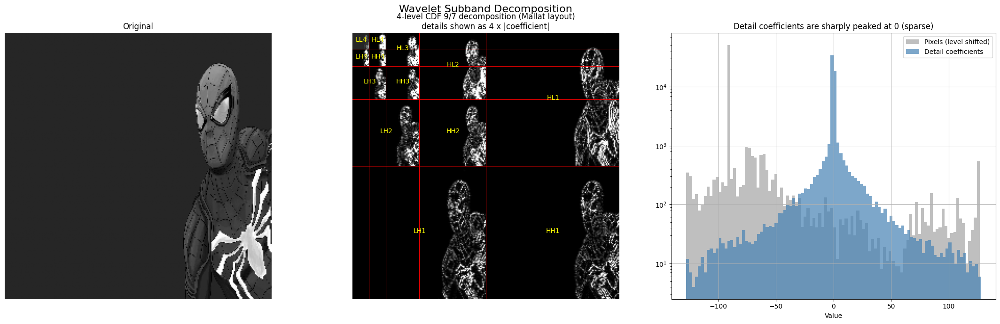

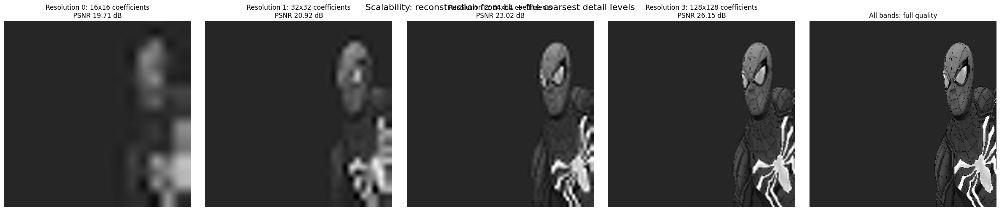

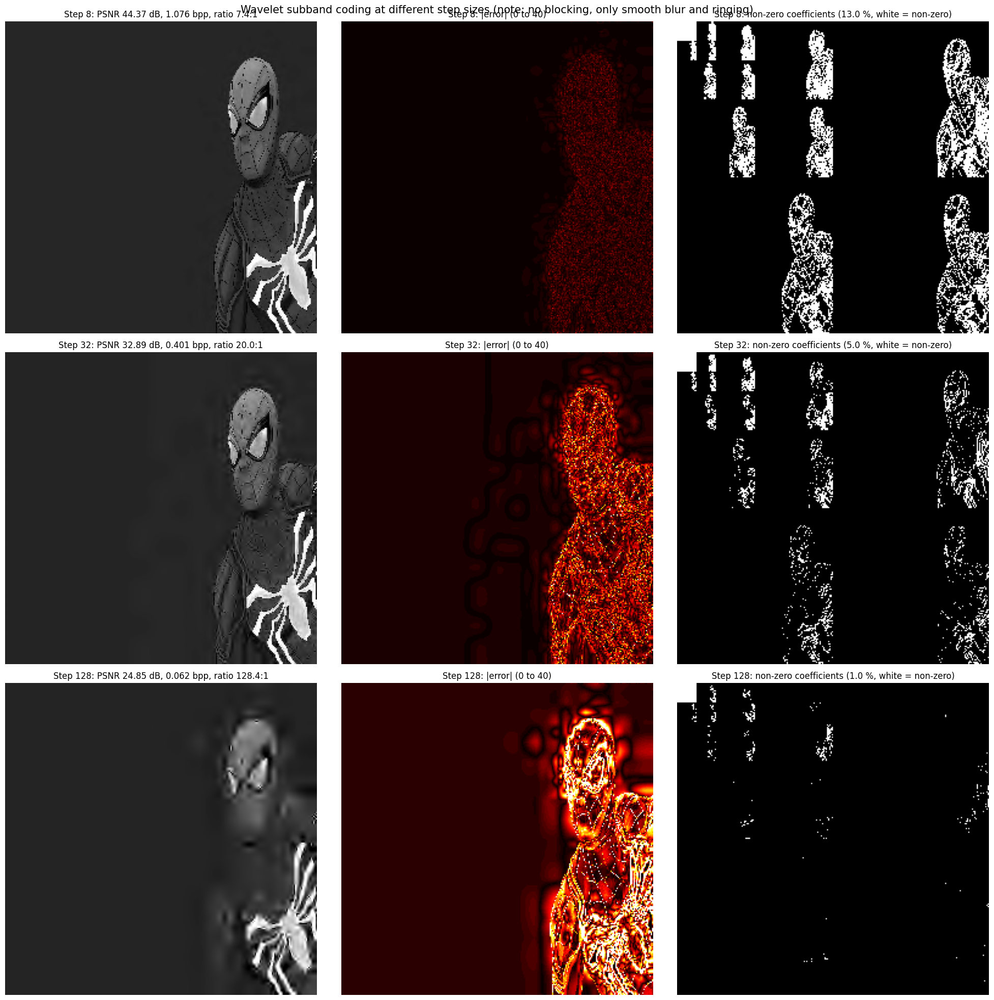

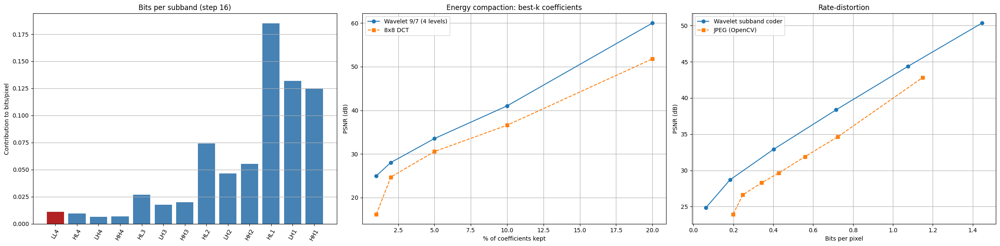


SUMMARY (grayscale, raw = 8 bits/pixel)
Method                            PSNR dB  bits/pixel    ratio
Lossless, 5/3 + band entropy          inf       2.185    3.66:1
Wavelet 9/7, step 4                 50.35       1.447     5.5:1
Wavelet 9/7, step 8                 44.37       1.076     7.4:1
Wavelet 9/7, step 16                38.36       0.716    11.2:1
Wavelet 9/7, step 32                32.89       0.401    20.0:1
Wavelet 9/7, step 64                28.68       0.183    43.8:1
Wavelet 9/7, step 128               24.85       0.062   128.4:1


In [2]:
import cv2
import math
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# =====================================================================
# SETUP: 1-D lifting wavelet transforms (Haar, CDF 5/3 reversible, CDF 9/7)
#   Every function works along axis 0, so 2-D is done by transposing.
#   Output layout of a 1-D analysis step: [ low-pass half | high-pass half ]
# =====================================================================
SQ2 = math.sqrt(2)
A9, B9, G9, D9, K9 = (-1.586134342059924, -0.052980118572961,
                       0.882911075530934, 0.443506852043971, 1.230174104914001)

def _split(x): return x[0::2].copy(), x[1::2].copy()
def _next(e):  return np.concatenate([e[1:], e[-1:]], axis=0)     # e[i+1], symmetric at the end
def _prev(o):  return np.concatenate([o[:1], o[:-1]], axis=0)     # o[i-1], symmetric at the start

def fwd1(x, kind):
    if kind == "haar":
        e, o = _split(x.astype(np.float64))
        return np.concatenate([(e + o) / SQ2, (e - o) / SQ2], axis=0)
    if kind == "5/3":                                  # integer-to-integer, reversible (JPEG 2000 lossless)
        e, o = _split(x.astype(np.int64))
        o = o - ((e + _next(e)) >> 1)                  # predict step
        e = e + ((_prev(o) + o + 2) >> 2)              # update step
        return np.concatenate([e, o], axis=0)
    e, o = _split(x.astype(np.float64))                # CDF 9/7 (JPEG 2000 lossy), four lifting steps
    o += A9 * (e + _next(e)); e += B9 * (_prev(o) + o)
    o += G9 * (e + _next(e)); e += D9 * (_prev(o) + o)
    return np.concatenate([e * SQ2 / K9, o * K9 / SQ2], axis=0)   # scaled to be near-orthonormal

def inv1(c, kind):
    n = c.shape[0] // 2
    l, h = c[:n].copy(), c[n:].copy()
    if kind == "haar":
        x = np.empty(c.shape, np.float64)
        x[0::2], x[1::2] = (l + h) / SQ2, (l - h) / SQ2
        return x
    if kind == "5/3":
        e = l - ((_prev(h) + h + 2) >> 2)
        o = h + ((e + _next(e)) >> 1)
        x = np.empty(c.shape, np.int64)
        x[0::2], x[1::2] = e, o
        return x
    e, o = l * K9 / SQ2, h * SQ2 / K9
    e -= D9 * (_prev(o) + o); o -= G9 * (e + _next(e))
    e -= B9 * (_prev(o) + o); o -= A9 * (e + _next(e))
    x = np.empty(c.shape, np.float64)
    x[0::2], x[1::2] = e, o
    return x

def dwt2(img, L, kind):
    # Mallat layout: LL in the top-left, HL top-right, LH bottom-left, HH bottom-right, recursing on LL
    c = img.astype(np.int64 if kind == "5/3" else np.float64).copy()
    s = c.shape[0]
    for _ in range(L):
        sub = c[:s, :s]
        sub = fwd1(sub.T, kind).T                      # horizontal filtering (rows)
        sub = fwd1(sub, kind)                          # vertical filtering (columns)
        c[:s, :s] = sub
        s //= 2
    return c

def idwt2(c, L, kind):
    c = c.copy()
    s = c.shape[0] >> (L - 1)
    for _ in range(L):
        sub = c[:s, :s]
        sub = inv1(sub, kind)
        sub = inv1(sub.T, kind).T
        c[:s, :s] = sub
        s *= 2
    return c

def subbands(N, L):
    out = [(f"LL{L}", (slice(0, N >> L), slice(0, N >> L)), L)]
    for l in range(L, 0, -1):
        s = N >> (l - 1); h = s // 2
        out += [(f"HL{l}", (slice(0, h), slice(h, s)), l),      # horizontal high-pass (vertical edges)
                (f"LH{l}", (slice(h, s), slice(0, h)), l),      # vertical high-pass (horizontal edges)
                (f"HH{l}", (slice(h, s), slice(h, s)), l)]     # diagonal detail
    return out

def psnr(a, b):
    mse = np.mean((np.asarray(a, np.float64) - np.asarray(b, np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * math.log10(255 ** 2 / mse)

def ent(a):
    _, cnt = np.unique(np.asarray(a).ravel(), return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

# =====================================================================
# PART A: HAND-CHECKABLE EXAMPLE (Haar)
# =====================================================================
print("=" * 70)
print("A. HAAR WAVELET / TWO-BAND SUBBAND CODING OF A 1-D SIGNAL")
print("=" * 70)
x = np.array([9, 7, 3, 5, 6, 10, 2, 6], dtype=np.float64)
print("Signal x             :", x.tolist())
avg, det = (x[0::2] + x[1::2]) / 2, (x[0::2] - x[1::2]) / 2
print("Pair averages        :", avg.tolist(), "<- low-pass band (half the samples)")
print("Pair half-differences:", det.tolist(), "<- high-pass band (detail)")
a2, d2 = (avg[0::2] + avg[1::2]) / 2, (avg[0::2] - avg[1::2]) / 2
a3, d3 = (a2[0] + a2[1]) / 2, (a2[0] - a2[1]) / 2
print("Level 2 averages     :", a2.tolist(), "| details:", d2.tolist())
print("Level 3 average      :", a3, "| detail:", d3)
wt = [a3, d3] + d2.tolist() + det.tolist()
print("Full transform       :", wt, "(1 average + 7 details = 8 numbers, no redundancy)")
r2 = np.array([a3 + d3, a3 - d3]); r4 = np.array([r2[0] + d2[0], r2[0] - d2[0], r2[1] + d2[1], r2[1] - d2[1]])
r8 = np.ravel(np.column_stack([r4 + det, r4 - det]))
print("Reconstruction       :", r8.tolist(), "| exact:", np.array_equal(r8, x))

h0 = np.array([1, 1]) / SQ2                            # low-pass analysis filter
h1 = np.array([-1, 1]) / SQ2                           # high-pass analysis filter
lo = np.convolve(x, h0)[1::2]                          # filter, then keep every 2nd sample
hi = np.convolve(x, h1)[1::2]
print("\nFilter-bank view (orthonormal Haar: h0 = [1 1]/sqrt2, h1 = [-1 1]/sqrt2, downsample by 2)")
print("  Low band :", np.round(lo, 3).tolist())
print("  High band:", np.round(hi, 3).tolist())
print("  Same as the lifting code:", np.allclose(np.concatenate([lo, hi]), fwd1(x, "haar")))
print(f"  Energy of x = {np.sum(x ** 2):.1f}, energy of subbands = {np.sum(lo ** 2) + np.sum(hi ** 2):.1f} (orthonormal: equal)")
print("  Quantizing all details to zero keeps the smooth shape:",
      np.round(inv1(np.concatenate([lo, np.zeros(4)]), "haar"), 2).tolist())

# =====================================================================
# PART B: LOAD IMAGE, 2-D DWT WITH THREE WAVELETS
# =====================================================================
print("\n" + "=" * 70)
print("B. 2-D WAVELET DECOMPOSITION OF THE IMAGE")
print("=" * 70)
uploaded = files.upload()
img_path = list(uploaded.keys())[0]
gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (256, 256))
H, W = gray.shape
N = H * W
g = gray.astype(np.float64)
L = 4                                                  # decomposition levels (LL4 is 16x16)
bands = subbands(N=H, L=L)
print("Image size:", gray.shape, "| levels:", L, "| LL band size:", H >> L, "x", W >> L, "| raw = 8 bits/pixel")

coefs = {}
print(f"\n{'Wavelet':8s}{'Max recon error':>18s}{'Exact?':>9s}")
for kind in ["haar", "5/3", "9/7"]:
    c = dwt2(g, L, kind)
    r = idwt2(c, L, kind)
    coefs[kind] = c
    exact = np.array_equal(r, gray.astype(np.int64)) if kind == "5/3" else np.allclose(r, g, atol=1e-6)
    print(f"{kind:8s}{np.abs(r - g).max():18.2e}{str(exact):>9s}")
print(f"Energy ratio sum(c^2)/sum(f^2): Haar = {np.sum(coefs['haar'] ** 2) / np.sum(g ** 2):.4f}, "
      f"9/7 = {np.sum(coefs['9/7'] ** 2) / np.sum(g ** 2):.4f}  (1.0 = orthonormal)")

c97 = coefs["9/7"]
tot = np.sum(c97 ** 2)
print(f"\nSubband statistics (CDF 9/7, {L} levels)")
print(f"{'Band':6s}{'Size':>9s}{'Coeffs':>8s}{'Energy %':>10s}{'Std':>9s}{'Max |c|':>9s}")
for name, sl, lev in bands:
    b = c97[sl]
    print(f"{name:6s}{b.shape[0]:5d}x{b.shape[1]:<3d}{b.size:8d}{100 * np.sum(b ** 2) / tot:10.3f}{b.std():9.2f}{np.abs(b).max():9.1f}")
ll_share = 100 * np.sum(c97[:H >> L, :W >> L] ** 2) / tot
print(f"The LL{L} band holds {100 * (H >> L) * (W >> L) / N:.2f} % of the coefficients but {ll_share:.2f} % of the energy.")

# Coding gain of a one-level orthonormal (Haar) subband split into M = 4 bands
c1 = dwt2(g, 1, "haar")
var4 = [c1[:H // 2, :W // 2].var(), c1[:H // 2, W // 2:].var(), c1[H // 2:, :W // 2].var(), c1[H // 2:, W // 2:].var()]
G = np.mean(var4) / np.exp(np.mean(np.log(var4)))
print(f"\nSubband coding gain, 1-level Haar, 4 bands: variances = {[round(v, 1) for v in var4]}")
print(f"  G = arithmetic mean / geometric mean of variances = {G:.2f}  ({10 * math.log10(G):.2f} dB)")
print("  (higher G = more bits saved than coding the image directly at the same distortion)")

# =====================================================================
# PART C: MULTIRESOLUTION: RECONSTRUCT FROM THE COARSEST BANDS ONLY
# =====================================================================
print("\n" + "=" * 70)
print("C. RESOLUTION SCALABILITY (keep LL and the coarsest detail levels only)")
print("=" * 70)
res_rec = []
print(f"{'Resolution':>11s}{'Image size':>12s}{'Coeffs kept %':>15s}{'PSNR vs original':>18s}")
for r in range(L + 1):
    s = H >> (L - r)
    m = np.zeros_like(c97); m[:s, :s] = c97[:s, :s]
    rec = np.clip(np.round(idwt2(m, L, "9/7")), 0, 255).astype(np.uint8)
    res_rec.append((s, rec))
    p = psnr(gray, rec)
    print(f"{r:11d}{str(s) + 'x' + str(s):>12s}{100 * s * s / N:15.2f}{('lossless' if p == float('inf') else f'{p:.2f} dB'):>18s}")
print("The decoder can stop after any resolution: low-resolution preview first, full detail later.")

# =====================================================================
# PART D: SUBBAND CODING = quantize every subband + entropy-code each band separately
# =====================================================================
def quantize(c, d):                                    # uniform dead-zone quantizer: zero bin is 2*d wide
    return (np.sign(c) * np.floor(np.abs(c) / d)).astype(np.int32)

def dequantize(q, d, r=0.5):                           # reconstruct in the middle of the bin
    return np.sign(q) * (np.abs(q) + r) * d

def compress(delta):
    q = quantize(c97, delta)
    rec = np.clip(np.round(idwt2(dequantize(q, delta), L, "9/7")), 0, 255).astype(np.uint8)
    bits_band = {name: q[sl].size * ent(q[sl]) for name, sl, _ in bands}
    return dict(q=q, rec=rec, psnr=psnr(gray, rec), nz=100 * np.count_nonzero(q) / q.size,
                bits_band=bits_band, bpp=sum(bits_band.values()) / N, bpp_single=ent(q))

print("\n" + "=" * 70)
print("D. SUBBAND CODING WITH A DEAD-ZONE QUANTIZER (same step in every band; 9/7 is near-orthonormal)")
print("=" * 70)
deltas = [4, 8, 16, 32, 64, 128]
res = {d: compress(d) for d in deltas}
print(f"{'Step':>5s} | {'PSNR':>6s} | {'Non-zero %':>10s} | {'bpp (per-band entropy)':>22s} | {'bpp (one table)':>15s} | {'Ratio':>7s}")
for d in deltas:
    r = res[d]
    print(f"{d:5d} | {r['psnr']:6.2f} | {r['nz']:10.2f} | {r['bpp']:22.3f} | {r['bpp_single']:15.3f} | {8 / r['bpp']:6.1f}:1")
print("Coding each subband with its own statistics always needs fewer bits than one common table.")
d0 = 16
print(f"\nWhere do the bits go? (step = {d0})")
print(f"{'Band':6s}{'bits/coeff':>11s}{'% of coeffs':>13s}{'% of bits':>11s}{'% zeros':>9s}")
tb = sum(res[d0]["bits_band"].values())
for name, sl, lev in bands:
    qb = res[d0]["q"][sl]
    print(f"{name:6s}{ent(qb):11.3f}{100 * qb.size / N:13.2f}{100 * res[d0]['bits_band'][name] / tb:11.2f}{100 * np.mean(qb == 0):9.1f}")

# Lossless: reversible 5/3 coefficients, per-band entropy
c53 = coefs["5/3"]
bits53 = sum(c53[sl].size * ent(c53[sl]) for _, sl, _ in bands)
H_img = ent(gray)
print("\n" + "-" * 70)
print("Lossless wavelet coding with the integer 5/3 transform (no quantization)")
print(f"  Entropy of the pixels                : {H_img:.3f} bits/pixel")
print(f"  Sum of 5/3 subband entropies         : {bits53 / N:.3f} bits/pixel -> ratio {8 / (bits53 / N):.2f}:1")
print("  Exact reconstruction                 :", np.array_equal(idwt2(c53, L, '5/3'), gray.astype(np.int64)))

# =====================================================================
# PART E: COMPARISONS (best-k coefficients vs DCT, rate-distortion vs JPEG)
# =====================================================================
def dct_matrix(n=8):
    Cm = np.zeros((n, n))
    for k in range(n):
        a = math.sqrt(1 / n) if k == 0 else math.sqrt(2 / n)
        for i in range(n):
            Cm[k, i] = a * math.cos((2 * i + 1) * k * math.pi / (2 * n))
    return Cm
Cm = dct_matrix(8)
blocks = (g - 128).reshape(H // 8, 8, W // 8, 8).transpose(0, 2, 1, 3)
D_all = Cm @ blocks @ Cm.T

def keep_wavelet(p):
    thr = np.quantile(np.abs(c97), 1 - p / 100)
    return np.clip(np.round(idwt2(np.where(np.abs(c97) >= thr, c97, 0), L, "9/7")), 0, 255)

def keep_dct(p):
    thr = np.quantile(np.abs(D_all), 1 - p / 100)
    rb = Cm.T @ np.where(np.abs(D_all) >= thr, D_all, 0) @ Cm
    return np.clip(np.round(rb.transpose(0, 2, 1, 3).reshape(H, W) + 128), 0, 255)

print("\n" + "=" * 70)
print("E1. KEEP ONLY THE LARGEST p % OF COEFFICIENTS (no quantization, no entropy coding)")
print("=" * 70)
ps = [1, 2, 5, 10, 20]
pw = [psnr(gray, keep_wavelet(p)) for p in ps]
pd = [psnr(gray, keep_dct(p)) for p in ps]
print(f"{'p %':>5s} | {'Wavelet 9/7':>12s} | {'8x8 DCT':>9s} | {'Difference':>10s}")
for p, a, b in zip(ps, pw, pd):
    print(f"{p:5d} | {a:10.2f} dB | {b:7.2f} dB | {a - b:+8.2f} dB")

print("\n" + "=" * 70)
print("E2. RATE-DISTORTION: wavelet subband coder vs OpenCV JPEG")
print("=" * 70)
Qs = [5, 10, 20, 30, 50, 70, 90]
jp = []
for Q in Qs:
    ok, buf = cv2.imencode(".jpg", gray, [int(cv2.IMWRITE_JPEG_QUALITY), Q])
    jp.append((8 * len(buf) / N, psnr(gray, cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE))))
print("JPEG:    " + ", ".join(f"Q={Q}: {b:.2f} bpp / {p:.1f} dB" for Q, (b, p) in zip(Qs, jp)))
print("Wavelet: " + ", ".join(f"step {d}: {res[d]['bpp']:.2f} bpp / {res[d]['psnr']:.1f} dB" for d in deltas))
print("(Wavelet rate is the ideal per-band entropy; JPEG size includes headers. Compare the trend, not the last 0.1 dB.)")

# =====================================================================
# DISPLAY
# =====================================================================
# Figure 1: Mallat layout and coefficient histograms
disp = np.clip(np.abs(c97) * 4, 0, 255)
s = H >> L
disp[:s, :s] = np.clip(c97[:s, :s] / (2 ** L), 0, 255)
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(disp, cmap="gray", vmin=0, vmax=255)
for l in range(1, L + 1):
    z = H >> l
    axes[1].axhline(z - 0.5, color="red", lw=0.8); axes[1].axvline(z - 0.5, color="red", lw=0.8)
    axes[1].text(1.5 * z, 0.5 * z, f"HL{l}", color="yellow", ha="center", fontsize=10)
    axes[1].text(0.5 * z, 1.5 * z, f"LH{l}", color="yellow", ha="center", fontsize=10)
    axes[1].text(1.5 * z, 1.5 * z, f"HH{l}", color="yellow", ha="center", fontsize=10)
axes[1].text(s / 2, s / 2, f"LL{L}", color="yellow", ha="center", fontsize=10)
axes[1].set_title(f"{L}-level CDF 9/7 decomposition (Mallat layout)\ndetails shown as 4 x |coefficient|"); axes[1].axis("off")
det_vals = np.concatenate([c97[sl].ravel() for name, sl, _ in bands[1:]])
axes[2].hist(g.ravel() - 128, bins=100, alpha=0.5, label="Pixels (level shifted)", color="gray", log=True)
axes[2].hist(det_vals, bins=100, range=(-128, 128), alpha=0.7, label="Detail coefficients", color="steelblue", log=True)
axes[2].set_title("Detail coefficients are sharply peaked at 0 (sparse)"); axes[2].set_xlabel("Value"); axes[2].legend(); axes[2].grid(True)
plt.suptitle("Wavelet Subband Decomposition", fontsize=16)
plt.tight_layout(); plt.show()

# Figure 2: resolution scalability
fig, axes = plt.subplots(1, L + 1, figsize=(26, 5.5))
for ax, (r, (sz, rec)) in zip(axes, enumerate(res_rec)):
    ax.imshow(rec, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Resolution {r}: {sz}x{sz} coefficients\nPSNR {psnr(gray, rec):.2f} dB" if r < L else "All bands: full quality")
    ax.axis("off")
plt.suptitle("Scalability: reconstruction from LL + the coarsest detail levels", fontsize=16)
plt.tight_layout(); plt.show()

# Figure 3: reconstructions at three step sizes
fig, axes = plt.subplots(3, 3, figsize=(20, 20))
for row, d in enumerate([8, 32, 128]):
    r = res[d]
    axes[row, 0].imshow(r["rec"], cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"Step {d}: PSNR {r['psnr']:.2f} dB, {r['bpp']:.3f} bpp, ratio {8 / r['bpp']:.1f}:1")
    axes[row, 1].imshow(np.abs(g - r["rec"].astype(float)), cmap="hot", vmin=0, vmax=40)
    axes[row, 1].set_title(f"Step {d}: |error| (0 to 40)")
    axes[row, 2].imshow(r["q"] != 0, cmap="gray")
    axes[row, 2].set_title(f"Step {d}: non-zero coefficients ({r['nz']:.1f} %, white = non-zero)")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Wavelet subband coding at different step sizes (note: no blocking, only smooth blur and ringing)", fontsize=15)
plt.tight_layout(); plt.show()

# Figure 4: bit budget, best-k comparison, rate-distortion
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
names = [n for n, _, _ in bands]
axes[0].bar(names, [res[d0]["bits_band"][n] / N for n in names], color=["firebrick"] + ["steelblue"] * (len(names) - 1))
axes[0].set_ylabel("Contribution to bits/pixel"); axes[0].set_title(f"Bits per subband (step {d0})")
axes[0].tick_params(axis="x", rotation=60); axes[0].grid(True, axis="y")
axes[1].plot(ps, pw, "o-", label="Wavelet 9/7 (4 levels)"); axes[1].plot(ps, pd, "s--", label="8x8 DCT")
axes[1].set_xlabel("% of coefficients kept"); axes[1].set_ylabel("PSNR (dB)")
axes[1].set_title("Energy compaction: best-k coefficients"); axes[1].legend(); axes[1].grid(True)
axes[2].plot([res[d]["bpp"] for d in deltas], [res[d]["psnr"] for d in deltas], "o-", label="Wavelet subband coder")
axes[2].plot([b for b, _ in jp], [p for _, p in jp], "s--", label="JPEG (OpenCV)")
axes[2].set_xlabel("Bits per pixel"); axes[2].set_ylabel("PSNR (dB)")
axes[2].set_title("Rate-distortion"); axes[2].legend(); axes[2].grid(True)
plt.tight_layout(); plt.show()

# =====================================================================
# SUMMARY
# =====================================================================
print("\n" + "=" * 70)
print("SUMMARY (grayscale, raw = 8 bits/pixel)")
print("=" * 70)
print(f"{'Method':32s}{'PSNR dB':>9s}{'bits/pixel':>12s}{'ratio':>9s}")
print(f"{'Lossless, 5/3 + band entropy':32s}{'inf':>9s}{bits53 / N:12.3f}{8 / (bits53 / N):8.2f}:1")
for d in deltas:
    r = res[d]
    print(f"{'Wavelet 9/7, step ' + str(d):32s}{r['psnr']:9.2f}{r['bpp']:12.3f}{8 / r['bpp']:8.1f}:1")

TOPOLOGICAL DESCRIPTORS
Connected components : 4
Holes                : 1
Euler number (C - H) : 3   (check: 4 - 1 = 3)

CHAIN CODES & REGIONAL DESCRIPTORS (outer boundaries)

[OUTER boundary 0] start=(np.int32(60), np.int32(210)), length=112 steps
 Chain code (first 40)     : 5444445454545555656565666665766666767676 ...
 Start-normalized (first 40): 0000010101011112121212222213222223232323 ...
 First difference (first 40): 0000171717100017171710000727000017171710 ...

[OUTER boundary 1] start=(np.int32(280), np.int32(200)), length=340 steps
 Chain code (first 40)     : 5555555555555555555555555555555555555555 ...
 Start-normalized (first 40): 0000000000000000000000000000000000000000 ...
 First difference (first 40): 0000000000000000000000000000000000000000 ...

[OUTER boundary 2] start=(np.int32(260), np.int32(45)), length=308 steps
 Chain code (first 40)     : 5444444444544454454454545454545545555555 ...
 Start-normalized (first 40): 0000000001000100100101010101011011111111 ...
 Firs

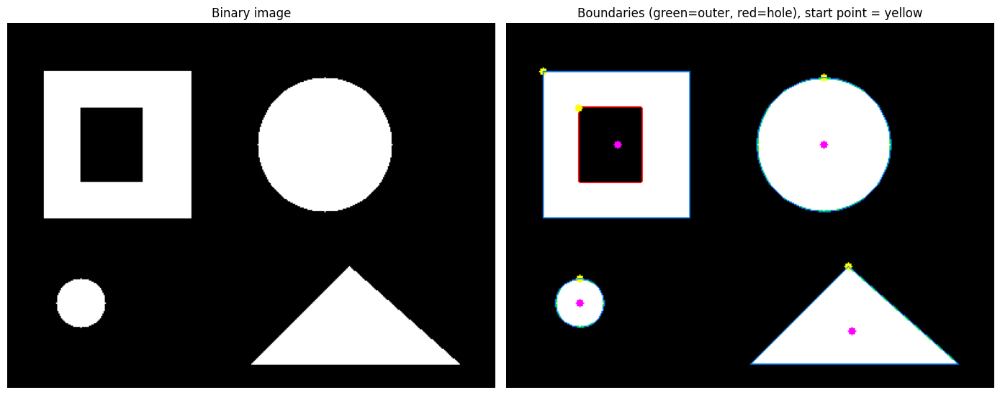

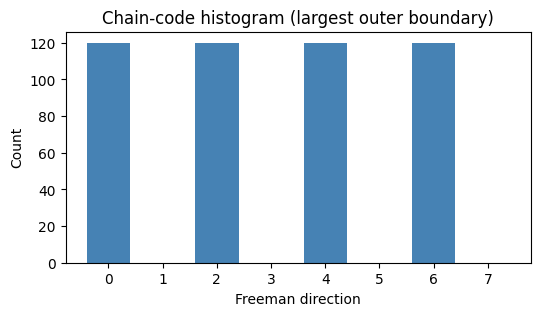

In [3]:
# ============================================================
# Boundary Representation: Chain Codes + Topological/Regional Descriptors
# Single cell for Google Colab
# ============================================================
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import measure

# ---------- 1. Create a sample binary image ----------
img = np.zeros((300, 400), np.uint8)
cv2.rectangle(img, (30, 40), (150, 160), 255, -1)       # square
cv2.rectangle(img, (60, 70), (110, 130), 0, -1)         # hole in square
cv2.circle(img, (260, 100), 55, 255, -1)                # disc
pts = np.array([[200, 280], [280, 200], [370, 280]])    # triangle
cv2.fillPoly(img, [pts], 255)
cv2.circle(img, (60, 230), 20, 255, -1)                 # small disc
_, bw = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

# ---------- 2. Freeman 8-direction chain code ----------
# Directions (x right, y down): 0=E,1=NE,2=N,3=NW,4=W,5=SW,6=S,7=SE
DIRS = {(1, 0): 0, (1, -1): 1, (0, -1): 2, (-1, -1): 3,
        (-1, 0): 4, (-1, 1): 5, (0, 1): 6, (1, 1): 7}

def chain_code_8(contour):
    pts = contour[:, 0, :]
    code = []
    for i in range(len(pts)):
        p, q = pts[i], pts[(i + 1) % len(pts)]
        d = (int(np.sign(q[0] - p[0])), int(np.sign(q[1] - p[1])))
        if d != (0, 0):
            code.append(DIRS[d])
    return code

def normalize_start(code):
    """Starting-point invariant: rotate to minimum-magnitude integer."""
    if not code: return code
    rots = [code[i:] + code[:i] for i in range(len(code))]
    return min(rots)

def first_difference(code, n=8):
    """Rotation invariant: counter-clockwise direction changes (mod n)."""
    if not code: return code
    return [(code[(i + 1) % len(code)] - code[i]) % n for i in range(len(code))]

# ---------- 3. Find boundaries (outer + holes) ----------
contours, hier = cv2.findContours(bw, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
hier = hier[0]

# ---------- 4. Topological descriptors ----------
labels = measure.label(bw > 0, connectivity=2)
n_components = labels.max()
n_holes = sum(1 for h in hier if h[3] != -1)
euler = measure.euler_number(bw > 0, connectivity=2)

print("=" * 60)
print("TOPOLOGICAL DESCRIPTORS")
print("=" * 60)
print(f"Connected components : {n_components}")
print(f"Holes                : {n_holes}")
print(f"Euler number (C - H) : {euler}   (check: {n_components} - {n_holes} = {n_components - n_holes})")

# ---------- 5. Chain code + regional descriptors per boundary ----------
print("\n" + "=" * 60)
print("CHAIN CODES & REGIONAL DESCRIPTORS (outer boundaries)")
print("=" * 60)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(bw, cmap="gray"); ax[0].set_title("Binary image")
vis = cv2.cvtColor(bw, cv2.COLOR_GRAY2RGB)
ax[1].set_title("Boundaries (green=outer, red=hole), start point = yellow")

props = measure.regionprops(labels)
for i, c in enumerate(contours):
    is_hole = hier[i][3] != -1
    color = (255, 0, 0) if is_hole else (0, 255, 0)
    cv2.drawContours(vis, [c], -1, color, 1)
    cv2.circle(vis, tuple(int(v) for v in c[0, 0]), 3, (255, 255, 0), -1)

    code = chain_code_8(c)
    norm = normalize_start(code)
    diff = first_difference(norm)
    kind = "HOLE " if is_hole else "OUTER"
    print(f"\n[{kind} boundary {i}] start={tuple(c[0,0])}, length={len(code)} steps")
    print(" Chain code (first 40)     :", ''.join(map(str, code[:40])), "...")
    print(" Start-normalized (first 40):", ''.join(map(str, norm[:40])), "...")
    print(" First difference (first 40):", ''.join(map(str, diff[:40])), "...")

# Regional descriptors for each connected region
for r in props:
    mask = (labels == r.label).astype(np.uint8)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    perim = cv2.arcLength(cnts[0], True)
    area = r.area
    compactness = (perim ** 2) / (4 * np.pi * area)       # 1.0 for a perfect circle
    circularity = 4 * np.pi * area / (perim ** 2)
    hull_area = r.area_convex
    hu = cv2.HuMoments(cv2.moments(mask, True)).flatten()
    hu_log = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
    holes_in_region = 1 - r.euler_number                   # per-region Euler number

    print(f"\n--- Region {r.label} ---")
    print(f" Area                 : {area:.0f}")
    print(f" Perimeter            : {perim:.2f}")
    print(f" Centroid (row, col)  : ({r.centroid[0]:.1f}, {r.centroid[1]:.1f})")
    print(f" Bounding box         : {r.bbox}")
    print(f" Compactness          : {compactness:.3f}")
    print(f" Circularity          : {circularity:.3f}")
    print(f" Extent (area/bbox)   : {r.extent:.3f}")
    print(f" Solidity (area/hull) : {area / hull_area:.3f}")
    print(f" Eccentricity         : {r.eccentricity:.3f}")
    print(f" Orientation (rad)    : {r.orientation:.3f}")
    print(f" Euler number         : {r.euler_number}  -> holes: {holes_in_region}")
    print(f" Hu moments (log10)   : {np.round(hu_log, 3)}")

    # draw centroid and convex hull
    hull = cv2.convexHull(cnts[0])
    cv2.polylines(vis, [hull], True, (0, 128, 255), 1)
    cv2.circle(vis, (int(r.centroid[1]), int(r.centroid[0])), 3, (255, 0, 255), -1)

ax[1].imshow(vis)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# ---------- 6. Chain-code direction histogram for the largest outer boundary ----------
outer = [c for i, c in enumerate(contours) if hier[i][3] == -1]
big = max(outer, key=cv2.contourArea)
code = chain_code_8(big)
plt.figure(figsize=(6, 3))
plt.bar(range(8), np.bincount(code, minlength=8), color="steelblue")
plt.xticks(range(8)); plt.xlabel("Freeman direction"); plt.ylabel("Count")
plt.title("Chain-code histogram (largest outer boundary)")
plt.show()

TEXTURE: Noise
Statistical moments:
  Mean (1st moment)       : 127.3119
  Variance (2nd moment)   : 5386.8049
  Std deviation           : 73.3949
  Skewness (3rd moment)   : -0.0152
  Kurtosis (4th moment)   : -1.1892
  Relative smoothness     : 0.0765
  Uniformity              : 0.0039
  Entropy (histogram)     : 7.9896

GLCM features (distance=1, averaged over 4 angles):
  contrast      : 168.5925
  dissimilarity : 10.6010
  homogeneity   : 0.0894
  energy        : 0.0315
  correlation   : -0.0021
  ASM           : 0.0010
  entropy       : 9.9882
  max_prob      : 0.0014

GLCM contrast per angle (d=1): {'0°': np.float64(169.731), '45°': np.float64(168.641), '90°': np.float64(167.962), '135°': np.float64(168.036)}
TEXTURE: Stripes
Statistical moments:
  Mean (1st moment)       : 126.5000
  Variance (2nd moment)   : 8019.6500
  Std deviation           : 89.5525
  Skewness (3rd moment)   : 0.0000
  Kurtosis (4th moment)   : -1.4921
  Relative smoothness     : 0.1098
  Uniformity       

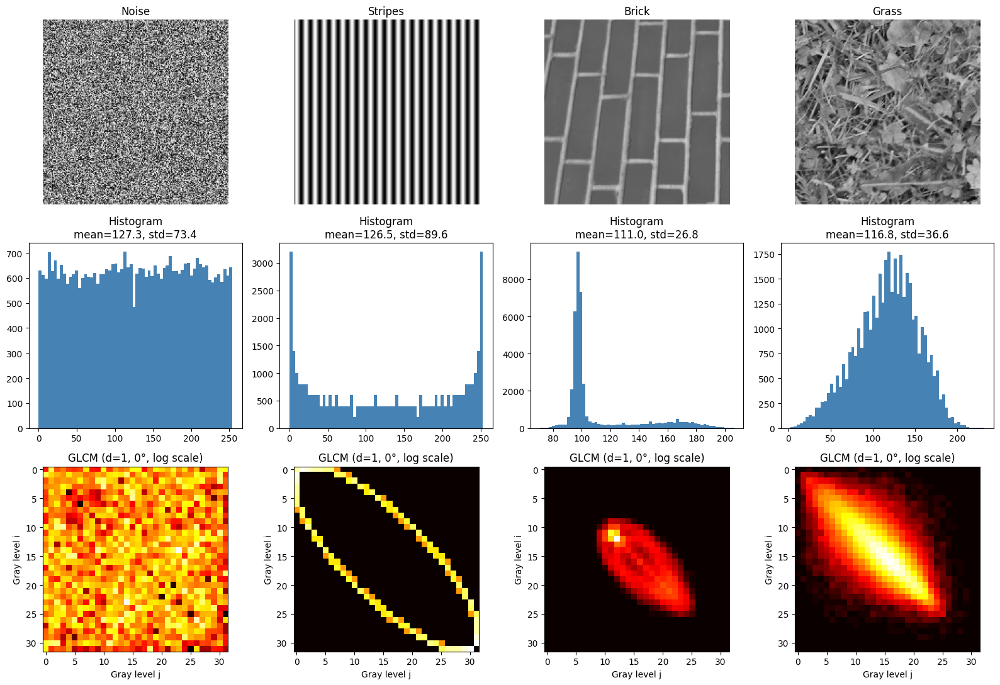

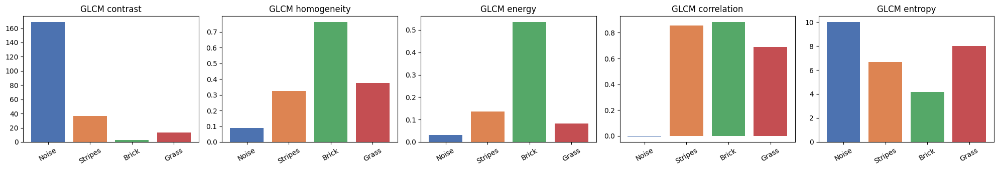

In [4]:
# ============================================================
# Texture Analysis: Statistical Moments + Gray-Level Co-occurrence Matrix (GLCM)
# Single cell for Google Colab
# ============================================================
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data
from skimage.feature import graycomatrix, graycoprops
from scipy.stats import skew, kurtosis, entropy as sp_entropy

# ---------- 1. Load sample texture images ----------
# Three different textures from skimage built-ins
def to_gray_u8(im):
    if im.ndim == 3:
        im = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    return im.astype(np.uint8)

rng = np.random.default_rng(0)
noise = (rng.random((200, 200)) * 255).astype(np.uint8)                    # random texture
stripes = np.tile((127 + 127 * np.sin(np.linspace(0, 40 * np.pi, 200))).astype(np.uint8), (200, 1))  # periodic
brick = to_gray_u8(data.brick())[:200, :200]                                # natural texture
grass = to_gray_u8(data.grass())[:200, :200]

textures = {"Noise": noise, "Stripes": stripes, "Brick": brick, "Grass": grass}

# To use your own image instead:
# textures = {"Mine": cv2.imread('your.png', 0)}

# ---------- 2. Statistical moments (first-order / histogram-based) ----------
def statistical_moments(img):
    x = img.astype(np.float64).ravel()
    hist = np.bincount(img.ravel(), minlength=256) / img.size
    levels = np.arange(256)
    mean = x.mean()
    var = x.var()
    std = np.sqrt(var)
    smooth = 1 - 1 / (1 + var / (255 ** 2))          # relative smoothness R
    uniformity = np.sum(hist ** 2)                   # energy of histogram
    ent = -np.sum(hist[hist > 0] * np.log2(hist[hist > 0]))
    return {
        "Mean (1st moment)": mean,
        "Variance (2nd moment)": var,
        "Std deviation": std,
        "Skewness (3rd moment)": skew(x),
        "Kurtosis (4th moment)": kurtosis(x),
        "Relative smoothness": smooth,
        "Uniformity": uniformity,
        "Entropy (histogram)": ent,
    }

# ---------- 3. GLCM (second-order) ----------
LEVELS = 32                                   # quantize to reduce matrix size
distances = [1, 3]
angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
angle_names = ["0°", "45°", "90°", "135°"]

def glcm_features(img):
    q = (img.astype(np.float64) / 256 * LEVELS).astype(np.uint8)   # quantize 0..LEVELS-1
    glcm = graycomatrix(q, distances=distances, angles=angles,
                        levels=LEVELS, symmetric=True, normed=True)
    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    feats = {p: graycoprops(glcm, p) for p in props}               # shape (len(dist), len(angles))
    # entropy and max probability (not in graycoprops)
    P = glcm.astype(np.float64)
    ent = -np.sum(np.where(P > 0, P * np.log2(P + 1e-12), 0), axis=(0, 1))
    feats["entropy"] = ent.T                                       # (dist, angle)
    feats["max_prob"] = P.max(axis=(0, 1)).T
    return glcm, feats

# ---------- 4. Run analysis and print results ----------
results = {}
for name, im in textures.items():
    mom = statistical_moments(im)
    glcm, feats = glcm_features(im)
    results[name] = (mom, glcm, feats)

    print("=" * 70)
    print(f"TEXTURE: {name}")
    print("=" * 70)
    print("Statistical moments:")
    for k, v in mom.items():
        print(f"  {k:<24}: {v:.4f}")
    print("\nGLCM features (distance=1, averaged over 4 angles):")
    for k, v in feats.items():
        print(f"  {k:<14}: {np.mean(v[0]):.4f}")
    print("\nGLCM contrast per angle (d=1):",
          dict(zip(angle_names, np.round(feats['contrast'][0], 3))))

# ---------- 5. Visualization: images, histograms, GLCM matrices ----------
n = len(textures)
fig, axes = plt.subplots(3, n, figsize=(4 * n, 11))
for j, (name, im) in enumerate(textures.items()):
    mom, glcm, feats = results[name]
    axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(name); axes[0, j].axis("off")
    axes[1, j].hist(im.ravel(), bins=64, color="steelblue")
    axes[1, j].set_title(f"Histogram\nmean={mom['Mean (1st moment)']:.1f}, std={mom['Std deviation']:.1f}")
    axes[2, j].imshow(np.log1p(glcm[:, :, 0, 0] * 1e4), cmap="hot")   # d=1, 0°
    axes[2, j].set_title("GLCM (d=1, 0°, log scale)")
    axes[2, j].set_xlabel("Gray level j"); axes[2, j].set_ylabel("Gray level i")
plt.tight_layout(); plt.show()

# ---------- 6. Feature comparison bar charts ----------
names = list(textures.keys())
feat_list = ["contrast", "homogeneity", "energy", "correlation", "entropy"]
fig, axes = plt.subplots(1, len(feat_list), figsize=(4 * len(feat_list), 3.5))
for ax, f in zip(axes, feat_list):
    vals = [np.mean(results[nm][2][f][0]) for nm in names]
    ax.bar(names, vals, color=["#4c72b0", "#dd8452", "#55a868", "#c44e52"][:len(names)])
    ax.set_title(f"GLCM {f}"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

TM_SQDIFF_NORMED (min best)    best location = (205, 55), score = 0.0000
TM_CCORR_NORMED (max best)     best location = (205, 55), score = 1.0000
TM_CCOEFF_NORMED (max best)    best location = (205, 55), score = 1.0000


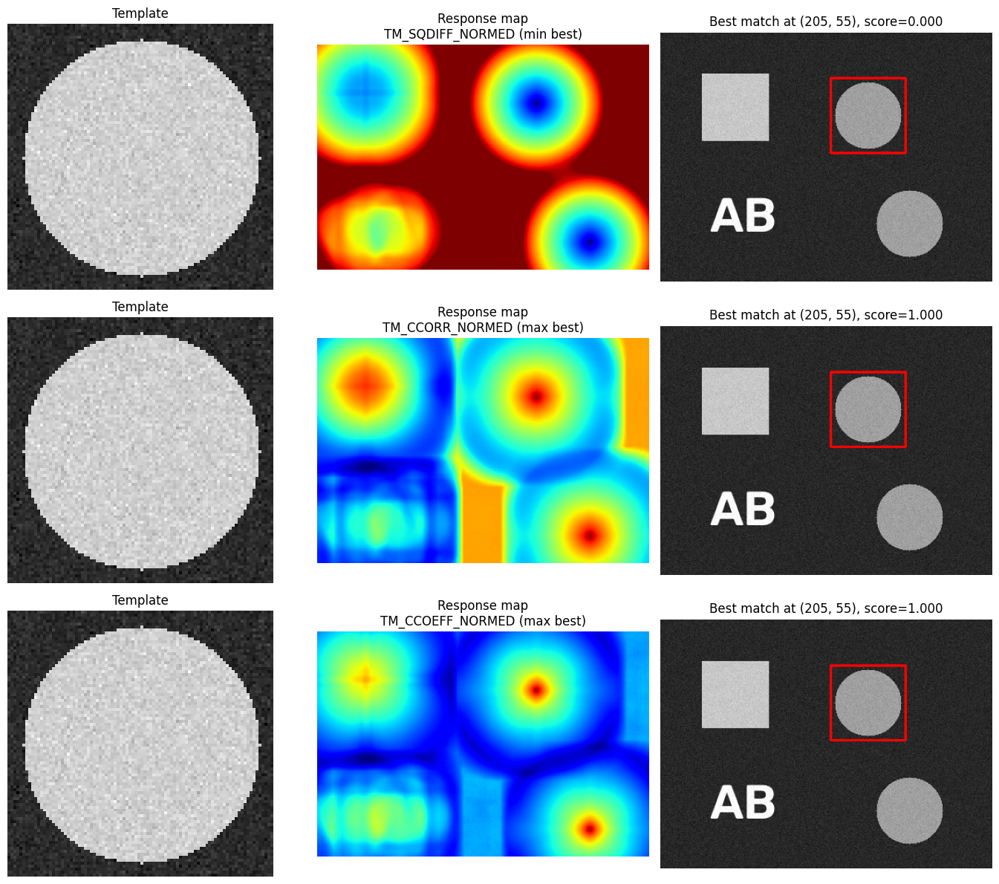

Match at (205,55) score=1.000
Match at (255,185) score=0.981


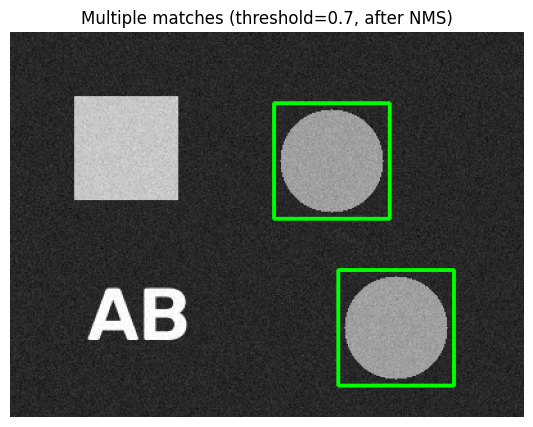


MINIMUM-DISTANCE CLASSIFICATION (digits, 10 classes)
euclidean    accuracy = 0.9037
manhattan    accuracy = 0.8926
mahalanobis  accuracy = 0.9593


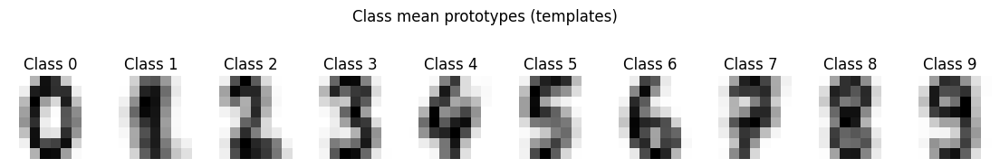

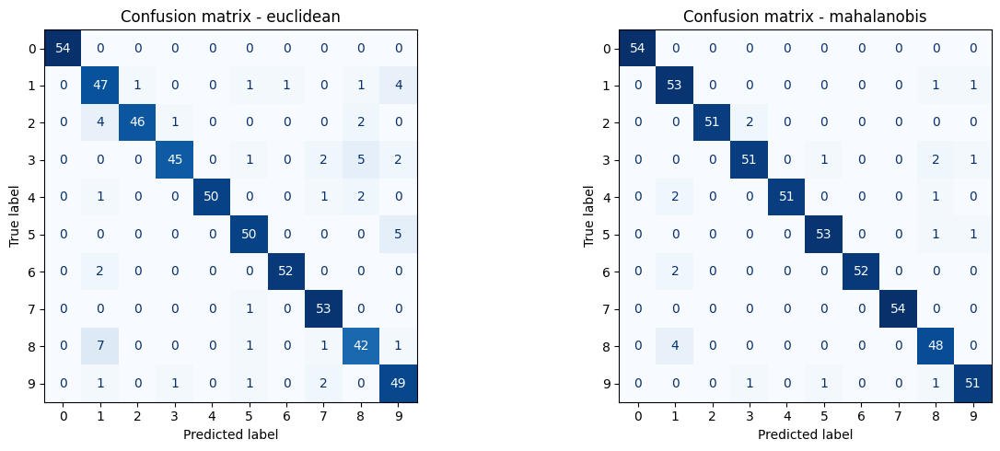

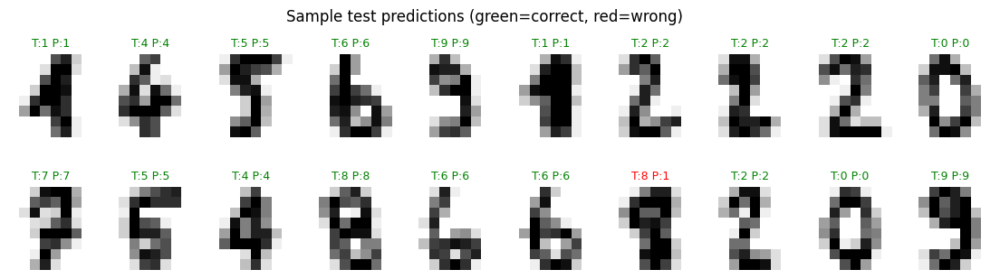

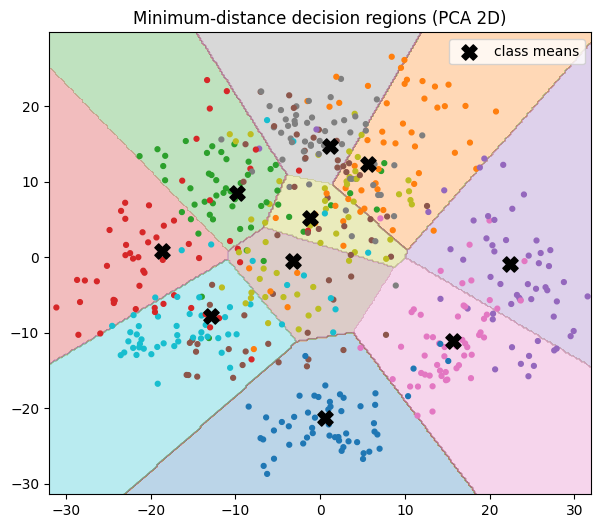

In [5]:
# ============================================================
# Pattern Recognition: Template Matching + Minimum-Distance Classification
# Single cell for Google Colab
# ============================================================
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

# ============================================================
# PART A: TEMPLATE MATCHING
# ============================================================
# ---------- A1. Build a scene and a template ----------
scene = np.full((300, 400), 40, np.uint8)
cv2.rectangle(scene, (50, 50), (130, 130), 200, -1)
cv2.circle(scene, (250, 100), 40, 160, -1)
cv2.putText(scene, "AB", (60, 240), cv2.FONT_HERSHEY_SIMPLEX, 2, 255, 4)
cv2.circle(scene, (300, 230), 40, 160, -1)                 # second circle (second match)
rng = np.random.default_rng(1)
scene = np.clip(scene + rng.normal(0, 8, scene.shape), 0, 255).astype(np.uint8)

template = scene[55:155, 205:295].copy()                   # crop of first circle
template = scene[55:145, 205:295].copy()
th, tw = template.shape

# ---------- A2. Match with 3 methods ----------
methods = {
    "TM_SQDIFF_NORMED (min best)": cv2.TM_SQDIFF_NORMED,
    "TM_CCORR_NORMED (max best)": cv2.TM_CCORR_NORMED,
    "TM_CCOEFF_NORMED (max best)": cv2.TM_CCOEFF_NORMED,
}

fig, axes = plt.subplots(len(methods), 3, figsize=(14, 4 * len(methods)))
for r, (name, m) in enumerate(methods.items()):
    res = cv2.matchTemplate(scene, template, m)
    minv, maxv, minl, maxl = cv2.minMaxLoc(res)
    top_left = minl if m == cv2.TM_SQDIFF_NORMED else maxl
    score = minv if m == cv2.TM_SQDIFF_NORMED else maxv

    vis = cv2.cvtColor(scene, cv2.COLOR_GRAY2RGB)
    cv2.rectangle(vis, top_left, (top_left[0] + tw, top_left[1] + th), (255, 0, 0), 2)

    axes[r, 0].imshow(template, cmap="gray"); axes[r, 0].set_title("Template")
    axes[r, 1].imshow(res, cmap="jet"); axes[r, 1].set_title(f"Response map\n{name}")
    axes[r, 2].imshow(vis); axes[r, 2].set_title(f"Best match at {top_left}, score={score:.3f}")
    for a in axes[r]: a.axis("off")
    print(f"{name:<30} best location = {top_left}, score = {score:.4f}")
plt.tight_layout(); plt.show()

# ---------- A3. Multiple matches via thresholding (TM_CCOEFF_NORMED) ----------
res = cv2.matchTemplate(scene, template, cv2.TM_CCOEFF_NORMED)
thr = 0.7
ys, xs = np.where(res >= thr)
boxes = [[int(x), int(y), tw, th] for x, y in zip(xs, ys)]
scores = [float(res[y, x]) for x, y in zip(xs, ys)]
idx = cv2.dnn.NMSBoxes(boxes, scores, thr, 0.3)             # non-maximum suppression
vis = cv2.cvtColor(scene, cv2.COLOR_GRAY2RGB)
for i in np.array(idx).flatten():
    x, y, w, h = boxes[i]
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    print(f"Match at ({x},{y}) score={scores[i]:.3f}")
plt.figure(figsize=(7, 5)); plt.imshow(vis); plt.axis("off")
plt.title(f"Multiple matches (threshold={thr}, after NMS)"); plt.show()

# ============================================================
# PART B: MINIMUM-DISTANCE CLASSIFIER
# ============================================================
# ---------- B1. Data: handwritten digits (8x8) ----------
digits = load_digits()
X, y = digits.data, digits.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

# ---------- B2. Train: class mean prototypes ----------
classes = np.unique(ytr)
means = np.array([Xtr[ytr == c].mean(axis=0) for c in classes])

# ---------- B3. Classify by minimum distance ----------
def min_distance_predict(X, means, metric="euclidean", cov_inv=None):
    if metric == "euclidean":
        d = np.linalg.norm(X[:, None, :] - means[None, :, :], axis=2)
    elif metric == "manhattan":
        d = np.abs(X[:, None, :] - means[None, :, :]).sum(axis=2)
    elif metric == "mahalanobis":
        diff = X[:, None, :] - means[None, :, :]
        d = np.sqrt(np.einsum("nkd,de,nke->nk", diff, cov_inv, diff))
    return d.argmin(axis=1), d

# Pooled covariance for Mahalanobis (regularized)
centered = np.vstack([Xtr[ytr == c] - means[i] for i, c in enumerate(classes)])
cov = np.cov(centered.T) + 1e-2 * np.eye(X.shape[1])
cov_inv = np.linalg.inv(cov)

print("\n" + "=" * 60)
print("MINIMUM-DISTANCE CLASSIFICATION (digits, 10 classes)")
print("=" * 60)
preds = {}
for metric in ["euclidean", "manhattan", "mahalanobis"]:
    p, _ = min_distance_predict(Xte, means, metric, cov_inv)
    preds[metric] = p
    print(f"{metric:<12} accuracy = {accuracy_score(yte, p):.4f}")

# ---------- B4. Visualize prototypes, confusion matrix, sample results ----------
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(means[i].reshape(8, 8), cmap="gray_r"); ax.set_title(f"Class {i}"); ax.axis("off")
plt.suptitle("Class mean prototypes (templates)", y=1.1); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, metric in zip(ax, ["euclidean", "mahalanobis"]):
    cm = confusion_matrix(yte, preds[metric])
    ConfusionMatrixDisplay(cm).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"Confusion matrix - {metric}")
plt.tight_layout(); plt.show()

p, d = min_distance_predict(Xte, means, "euclidean")
fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(Xte[i].reshape(8, 8), cmap="gray_r")
    ok = p[i] == yte[i]
    ax.set_title(f"T:{yte[i]} P:{p[i]}", color="green" if ok else "red", fontsize=9)
    ax.axis("off")
plt.suptitle("Sample test predictions (green=correct, red=wrong)"); plt.show()

# ---------- B5. Decision boundaries on 2D PCA projection ----------
from sklearn.decomposition import PCA
pca = PCA(2).fit(Xtr)
Ztr, Zte = pca.transform(Xtr), pca.transform(Xte)
m2 = np.array([Ztr[ytr == c].mean(axis=0) for c in classes])
gx, gy = np.meshgrid(np.linspace(Ztr[:, 0].min() - 2, Ztr[:, 0].max() + 2, 300),
                     np.linspace(Ztr[:, 1].min() - 2, Ztr[:, 1].max() + 2, 300))
grid = np.c_[gx.ravel(), gy.ravel()]
gp, _ = min_distance_predict(grid, m2, "euclidean")
plt.figure(figsize=(7, 6))
plt.contourf(gx, gy, gp.reshape(gx.shape), levels=np.arange(-0.5, 10.5, 1), cmap="tab10", alpha=0.3)
plt.scatter(Zte[:, 0], Zte[:, 1], c=yte, cmap="tab10", s=12)
plt.scatter(m2[:, 0], m2[:, 1], c="k", marker="X", s=120, label="class means")
plt.legend(); plt.title("Minimum-distance decision regions (PCA 2D)"); plt.show()